<a id="top"></a>
# TweetEval – Offensive Language Detection
## Notebook 07 · Final project (complete pipeline, Parts 1 to 6 + synthesis)

| | |
|---|---|
| **Course** | Machine Learning – CI1 – Faculté des Sciences de Bizerte |
| **Dataset** | TweetEval – Offensive (binary: `offensive` / `non-offensive`) |
| **Task** | Predict whether a tweet is offensive |
| **Main metric** | F1 of the **offensive** class (the data is imbalanced: about 1 tweet in 3 is offensive) |

This notebook gathers the whole project in one place, in the order in which the work was done. Notebooks 01 to 06 became **Parts 1 to 6** (Part 5 is the version that trains BiLSTM and BERT, Part 6 was extended to score BERT on the test set), and **Part 7** adds a final synthesis (consolidated tables, progress chart, demo on new tweets, conclusions).

| Part | Content | Reads | Writes |
|---|---|---|---|
| [1](#part1) | Exploratory data analysis | `data/raw/` (downloaded if missing) | `results/*/01_data_exploration/` |
| [2](#part2) | Text cleaning (`clean_text`) | `data/raw/` | `data/processed/*_clean.csv` |
| [3](#part3) | Stop-words, lemmatisation, vectorisation (TF-IDF vs BoW) | `*_clean.csv` | `data/processed/*_final.csv` |
| [4](#part4) | Class-balance experiments | `*_final.csv` | `train_balanced.csv`, balancing tables |
| [5](#part5) | Training of the models (5 required + optional) | `*_final.csv` | validation metrics, predictions, hyperparameters |
| [6](#part6) | Evaluation, model selection, final test (once) | Part 5 outputs, `models/bert/`, `test_final.csv` | `models/best_model_info.json`, test metrics |
| [7](#part7) | Final synthesis and conclusions | all saved results | – |

### How to use this notebook
* **Run it from top to bottom** (*Run All*), starting with the global configuration cell below. Parts depend on each other **through files** (`data/processed/`, `results/`), exactly as the separate notebooks did.
* Each part starts with its own **Setup** cell, so a single part can also be re-run alone once the files of the previous parts exist.
* Section numbers quoted *inside* a part (for example "section 6") refer to the numbering of that part.
* The stored outputs are those of the original runs of notebooks 01 to 05 (Part 5 includes BiLSTM and BERT). **Part 6 outputs were cleared**: run Part 6 to get the final test score.
* Required packages: `numpy`, `pandas`, `matplotlib`, `seaborn`, `scipy`, `scikit-learn`, `wordcloud`, `nltk`, `joblib`; optional: `gensim` (Word2Vec, Part 3), `torch` and `transformers` (BiLSTM and BERT, Parts 5 and 6).
* The project modules (`src/config.py`, `src/preprocessing.py`, `src/final_pipeline.py`, `src/<model>.py`, …) must be present next to this notebook.

### Rules followed in every part
Same random seed everywhere · TF-IDF fitted on **train only** · labels never modified · balancing only on **training** rows · choices made on **validation** (and cross-validation on train) ·
the **test set is used exactly once**, in Part 6, for the selected model.

### Contents
[Part 0 · Global configuration](#part0) · [Part 1 · EDA](#part1) · [Part 2 · Cleaning](#part2) · [Part 3 · Preprocessing experiments](#part3) · [Part 4 · Class balancing](#part4) ·
[Part 5 · Model training](#part5) · [Part 6 · Evaluation and final test](#part6) · [Part 7 · Final synthesis](#part7)

<a id="part0"></a>
## Part 0 · Global configuration
One place for the switches of the slow or optional parts. **The five required models always run**; only the extras depend on these switches.

| Switch | Meaning |
|---|---|
| `RUN_EXTRA` | classical optional models of Part 5 (Complement NB, SGD, Voting): a few seconds |
| `RUN_LSTM`, `RUN_BERT` | `True` = run, `False` = skip, `"auto"` = run only if `torch` is installed **and** a GPU is available (so a laptop without GPU never blocks for an hour). Set `True` on Google Colab with a GPU for BERT |
| `RUN_CV` | 5-fold cross-validation of the classical models in Part 5 (a few minutes) |

In [1]:
import sys, platform, warnings
from pathlib import Path

warnings.filterwarnings("ignore")

# Project root: works whether Jupyter was started in the root folder or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROJECT_ROOT = ROOT                                  # alias used by Parts 1 and 2
sys.path.insert(0, str(ROOT))                        # lets Python import the `src` package

# ---------------------------- SWITCHES (used by Part 5) --------------------------------
RUN_EXTRA = True            # Complement NB, SGD, Voting ensemble
RUN_LSTM  = "auto"          # True / False / "auto"  (auto = torch installed AND GPU present)
RUN_BERT  = "auto"          # True / False / "auto"  (set True on Google Colab with a GPU)
RUN_CV    = True            # 5-fold cross-validation (Part 5, section 12)

# ---------------------------- environment check ----------------------------------------
import numpy, pandas, sklearn, matplotlib
print("Project root :", ROOT)
print("Python       :", platform.python_version())
print("numpy / pandas / scikit-learn / matplotlib :", numpy.__version__, "/", pandas.__version__, "/", sklearn.__version__, "/", matplotlib.__version__)
print("src package  :", "found" if (ROOT / "src").is_dir() else "NOT FOUND -> run the notebook from the project root or from notebooks/")
print("Switches     : extra =", RUN_EXTRA, "| LSTM =", RUN_LSTM, "| BERT =", RUN_BERT, "| CV =", RUN_CV)

Project root : c:\Users\ASUS\Desktop\TweetEval-offensiveML
Python       : 3.13.14
numpy / pandas / scikit-learn / matplotlib : 2.5.4 / 3.1.1 / 1.9.1 / 3.11.2
src package  : found
Switches     : extra = True | LSTM = auto | BERT = auto | CV = True


**Reading.** The printed root must be the project folder (the one containing `src/`, `data/`, `results/`). If `src package` says `NOT FOUND`, the notebook was started from the wrong directory and the imports of the following parts would fail.

---

<a id="part1"></a>
# Part 1 · Exploratory Data Analysis (EDA)

### Goal of this part
Before training any model we must **understand the data**: its structure, its quality, the balance between the classes,
the length and style of the tweets, and the vocabulary that separates offensive from non-offensive tweets.
Every observation made here is translated into a **decision for the preprocessing** (Part 2) and for the choice of
evaluation metrics.

### Contents
1. [Setup](#p1-1)
2. [Loading the data](#p1-2)
3. [Structure of the data](#p1-3)
4. [Data quality checks](#p1-4)
5. [Class distribution](#p1-5)
6. [Text length analysis](#p1-6)
7. [Stylistic / surface features](#p1-7)
8. [Vocabulary analysis](#p1-8)
9. [WordClouds per class](#p1-9)
10. [Example tweets](#p1-10)
11. [Conclusions & implications for preprocessing](#p1-11)
12. [Saving the results](#p1-12)

> **How to read this part.** Code cells are commented line by line. Every cell that produces a result is followed by a
> **Results explained** cell that says what the output shows, how to read it, and what it implies for the rest of the project.
> All output folders (`results/figures/01_data_exploration/` and `results/metrics/01_data_exploration/`) are **created
> automatically** by the setup cell.

<a id="p1-1"></a>
## 1.1 Setup
Imports, paths, automatic creation of the output folders, and a consistent colour scheme (blue = non-offensive, red = offensive).

In [2]:
import re, sys, warnings                 # re: regular expressions | sys: import path | warnings: hide noise
from pathlib import Path                 # OS-independent file paths
from collections import Counter          # fast word counting

import numpy as np                       # numerical computing
import pandas as pd                      # tables (DataFrames)
import matplotlib.pyplot as plt          # plotting
import seaborn as sns                    # statistical plots and nicer styles
from scipy.stats import mannwhitneyu     # non-parametric test used to compare tweet lengths
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS   # standard English stop-word list
from wordcloud import WordCloud          # word-cloud images

warnings.filterwarnings("ignore")                       # keep the output readable
sns.set_theme(style="whitegrid", context="notebook")    # consistent plot style
plt.rcParams["figure.dpi"] = 110                        # sharper figures on screen

# --- Project root: works whether the notebook is launched from the root or from notebooks/ ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))                   # so that `import src...` works

# --- Folders ------------------------------------------------------------------
RAW_DIR = PROJECT_ROOT / "data" / "raw"                 # raw official files (never edited)
FIG_DIR = PROJECT_ROOT / "results" / "figures"
MET_DIR = PROJECT_ROOT / "results" / "metrics"

# Sub-folders dedicated to THIS notebook (one sub-folder per notebook keeps results organised)
NB_NAME = "01_data_exploration"
EDA_FIG_DIR = FIG_DIR / NB_NAME
EDA_MET_DIR = MET_DIR / NB_NAME

# Create every folder automatically.
# parents=True -> also creates missing parent folders | exist_ok=True -> no error if the folder already exists
for d in (RAW_DIR, FIG_DIR, MET_DIR, EDA_FIG_DIR, EDA_MET_DIR):
    d.mkdir(parents=True, exist_ok=True)

# --- Labels and colours (used by every plot) ----------------------------------
LABEL_NAMES = {0: "non-offensive", 1: "offensive"}
COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}     # blue / red
PALETTE = [COLORS["non-offensive"], COLORS["offensive"]]

def savefig(fig, name):
    """Save a figure into results/figures/01_data_exploration/, display it, then close it.
    The figure is passed explicitly, so we can never save the wrong one by mistake."""
    fig.tight_layout()                                          # avoid overlapping labels
    fig.savefig(EDA_FIG_DIR / name, dpi=300, bbox_inches="tight")
    plt.show()
    plt.close(fig)                                              # free memory

print("Project root   :", PROJECT_ROOT)
print("Raw data dir   :", RAW_DIR)
print("Figures saved in:", EDA_FIG_DIR)
print("Metrics saved in:", EDA_MET_DIR)

Project root   : c:\Users\ASUS\Desktop\TweetEval-offensiveML
Raw data dir   : c:\Users\ASUS\Desktop\TweetEval-offensiveML\data\raw
Figures saved in: c:\Users\ASUS\Desktop\TweetEval-offensiveML\results\figures\01_data_exploration
Metrics saved in: c:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\01_data_exploration


**Results explained.**
- The printed paths confirm that this part found the project root and will read the raw files from `data/raw/`. If the notebook is launched from `notebooks/`, the root is the parent folder; on another machine the paths differ, which is harmless.
- The two output sub-folders now exist (they are created by the `mkdir` loop), so no later `savefig` or `to_csv` can fail because of a missing folder.
- Nothing statistical here: the cell fixes the conventions used everywhere below (seaborn style, the `savefig` helper, **blue = non-offensive, red = offensive**).

<a id="p1-2"></a>
## 1.2 Loading the data

The official TweetEval repository provides **six plain-text files** (one tweet / one label per line):

| Split | Files | Role in the project |
|---|---|---|
| train | `train_text.txt`, `train_labels.txt` | fit the vectorizer and the models |
| val | `val_text.txt`, `val_labels.txt` | model selection |
| test | `test_text.txt`, `test_labels.txt` | final evaluation **only** |

The cell below downloads the files into `data/raw/` if they are missing (raw files are never edited afterwards),
then loads them using `src/data_loader.py` (with an identical fallback if the module is not found).

In [3]:
import urllib.request

# Official location of the dataset
BASE_URL = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/offensive/"
# Build the six file names: train_text.txt, train_labels.txt, val_text.txt, ...
FILES = [f"{s}_{k}.txt" for s in ("train", "val", "test") for k in ("text", "labels")]

for fname in FILES:
    target = RAW_DIR / fname
    if not target.exists():                          # download only what is missing
        print("Downloading", fname)
        urllib.request.urlretrieve(BASE_URL + fname, target)

# Preferred: the project loader. Fallback: an identical function defined here.
try:
    from src.data_loader import load_all
except ImportError:
    def _read_lines(path):
        with open(path, encoding="utf-8") as f:
            return [line.rstrip("\n") for line in f]          # one tweet / label per line

    def load_all(raw_dir=RAW_DIR):
        out = []
        for s in ("train", "val", "test"):
            texts = _read_lines(Path(raw_dir) / f"{s}_text.txt")
            labels = [int(x) for x in _read_lines(Path(raw_dir) / f"{s}_labels.txt")]
            assert len(texts) == len(labels), f"{s}: texts/labels mismatch"   # alignment check
            out.append(pd.DataFrame({"text": texts, "label": labels}))
        return tuple(out)

train_df, val_df, test_df = load_all()

# One big table with a "split" column: convenient for grouped statistics and plots
full_df = pd.concat(
    [train_df.assign(split="train"), val_df.assign(split="val"), test_df.assign(split="test")],
    ignore_index=True,
)
full_df["label_name"] = full_df["label"].map(LABEL_NAMES)                              # 0/1 -> readable name
full_df["split"] = pd.Categorical(full_df["split"], ["train", "val", "test"], ordered=True)   # fixed display order

print(f"train: {len(train_df):>6} tweets")
print(f"val  : {len(val_df):>6} tweets")
print(f"test : {len(test_df):>6} tweets")
print(f"total: {len(full_df):>6} tweets")

train:  11916 tweets
val  :   1324 tweets
test :    860 tweets
total:  14100 tweets


**Results explained.**
- The official splits contain **11,916 / 1,324 / 860 tweets** (14,100 in total), i.e. about 84.5 % / 9.4 % / 6.1 %. If no `Downloading ...` line was printed, the six raw files were already present locally.
- The **test set is small**: one tweet is worth about 0.12 accuracy points, so test scores will be noisier than validation scores.
- The loader checks `len(texts) == len(labels)` for every split, so the absence of an assertion error means texts and labels are aligned line by line.

<a id="p1-3"></a>
## 1.3 Structure of the data
`.head()`, `.info()` and `.describe()` as requested in the assignment.

In [4]:
print("=== HEAD (train) ===")
display(train_df.head(10))       # first 10 tweets with their label

=== HEAD (train) ===


,text,label
0,@user Bono... who cares. Soon people will unde...,0
1,@user Eight years the republicans denied obama...,1
2,@user Get him some line help. He is gonna be j...,0
3,@user @user She is great. Hi Fiona!,0
4,@user She has become a parody unto herself? Sh...,1
5,@user @user @user @user @user @user @user @use...,0
6,@user Your looking more like a plant #maga #wa...,1
7,@user @user Lol. Except he’s the most successf...,0
8,@user Been a Willie fan since before most of y...,0
9,@user Here's a link to my channel with a pleth...,0


**Results explained.**
- The data has exactly two columns: `text` (the tweet) and `label` (0 = non-offensive, 1 = offensive).
- All 10 tweets shown start with `@user`: most of the corpus consists of **replies**, and mentions were anonymised by the dataset authors. Row 5 is an extreme case: a long chain of `@user`.
- 3 of the 10 tweets are offensive (rows 1, 4, 6), close to the global rate of 33 %.
- Offensive does not mean profane. Row 1 ("...as phony as their fake president") and row 6 ("looking more like a plant") contain no swear word; only row 4 has an explicit insult (`idiot`). A first hint that vocabulary alone will not explain every label.

In [5]:
# .info(): number of rows, column types, non-null counts (-> missing values), memory usage
print("=== INFO (train) ===")
train_df.info()
print("\n=== INFO (val) ===")
val_df.info()
print("\n=== INFO (test) ===")
test_df.info()

=== INFO (train) ===
<class 'pandas.DataFrame'>
RangeIndex: 11916 entries, 0 to 11915
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    11916 non-null  str  
 1   label   11916 non-null  int64
dtypes: int64(1), str(1)
memory usage: 1.6 MB

=== INFO (val) ===
<class 'pandas.DataFrame'>
RangeIndex: 1324 entries, 0 to 1323
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    1324 non-null   str  
 1   label   1324 non-null   int64
dtypes: int64(1), str(1)
memory usage: 194.5 KB

=== INFO (test) ===
<class 'pandas.DataFrame'>
RangeIndex: 860 entries, 0 to 859
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   text    860 non-null    str  
 1   label   860 non-null    int64
dtypes: int64(1), str(1)
memory usage: 136.7 KB


**Results explained.**
- All three splits have **0 missing values** in both columns (non-null count = number of rows), so no imputation is required.
- Types are as expected: `text` is a string column and `label` is an integer.
- The whole dataset is tiny (about 186 KB for train, 21 KB for val, 14 KB for test): everything fits in memory and every experiment runs quickly.

In [6]:
# .describe(include="all"): statistics for ALL columns (count/unique/top/freq for text, mean/std/quartiles for label)
print("=== DESCRIBE – all columns (train) ===")
display(train_df.describe(include="all"))

# Check that only the values 0 and 1 occur in the label column of every split
print("Unique label values per split:")
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"  {name:5s} -> {sorted(d['label'].unique())}")

=== DESCRIBE – all columns (train) ===


,text,label
count,11916,11916.000000
unique,11883,NaN
top,@user Looks Like The Jokes On Liberals Again. ...,NaN
freq,5,NaN
mean,NaN,0.330732
std,NaN,0.470496
min,NaN,0.000000
25%,NaN,0.000000
50%,NaN,0.000000
75%,NaN,1.000000


Unique label values per split:
  train -> [np.int64(0), np.int64(1)]
  val   -> [np.int64(0), np.int64(1)]
  test  -> [np.int64(0), np.int64(1)]


**Results explained.**
- `unique = 11,883` out of `count = 11,916` means **33 duplicated tweets** in train, which matches the quality table in section 4. The most repeated tweet appears 5 times.
- `label` mean = **0.3307**: 33.07 % of train tweets are offensive. The median is 0 and the 75th percentile is 1, which only says that class 0 is the majority.
- The standard deviation (0.4705) is exactly the value expected for a yes/no variable with p = 0.33 (sqrt(p(1-p))), so it carries no extra information.
- Only the values 0 and 1 occur in each split: no corrupted label.

**Reading guide.** The dataset has only two columns: `text` (a string) and `label`. Since there are no numerical features, `describe()` is only informative for `label`: its mean is the proportion of offensive tweets. Richer numerical descriptors (length, punctuation, …) are built in sections 6 and 7.

<a id="p1-4"></a>
## 1.4 Data quality checks
Before modelling we verify: missing values, empty texts, duplicates, and — most importantly — **overlap between splits**
(identical tweets in train and test would inflate the final score = data leakage).

In [7]:
quality = []
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    quality.append({
        "split": name,
        "n_rows": len(d),
        "missing_text": d["text"].isna().sum(),                    # NaN texts
        "missing_label": d["label"].isna().sum(),                  # NaN labels
        "empty_text": (d["text"].str.strip() == "").sum(),         # blank tweets
        "duplicate_texts": d["text"].duplicated().sum(),           # 2nd and later copies of a text
        "duplicate_%": round(100 * d["text"].duplicated().mean(), 2),
    })
quality_df = pd.DataFrame(quality).set_index("split")
display(quality_df)

,n_rows,missing_text,missing_label,empty_text,duplicate_texts,duplicate_%
split,,,,,,
train,11916,0,0,0,33,0.28
val,1324,0,0,0,1,0.08
test,860,0,0,0,11,1.28


**Results explained.**
- No missing text, no missing label and no empty text in any split.
- Duplicated texts: **33 in train (0.28 %), 1 in val (0.08 %), 11 in test (1.28 %)**. The test set has the highest rate, but in absolute terms it is only 11 tweets.
- The counts include only the second and later copies of a text (`duplicated()`), so the first occurrence is not counted.
- Conclusion: the data is structurally clean; no row needs to be dropped.

In [8]:
# Overlap between splits: intersection of the sets of texts (data leakage check)
tr, va, te = set(train_df["text"]), set(val_df["text"]), set(test_df["text"])
print("Identical tweets  train ∩ val :", len(tr & va))
print("Identical tweets  train ∩ test:", len(tr & te))
print("Identical tweets  val   ∩ test:", len(va & te))

# Label noise: the same text carrying both labels inside train
grp = train_df.groupby("text")["label"].nunique()       # number of distinct labels per text
print("\nTweets appearing with both labels in train:", int((grp > 1).sum()))

Identical tweets  train ∩ val : 4
Identical tweets  train ∩ test: 4
Identical tweets  val   ∩ test: 0

Tweets appearing with both labels in train: 6


**Results explained.**
- Overlap between splits: **4 tweets in both train and val, 4 in both train and test, 0 in both val and test**.
- The risk of leakage is negligible: 4 of 860 test tweets (0.47 %) also exist in train, so even a model that memorised them could improve test accuracy by less than half a point.
- **6 train tweets carry both labels** (6 / 11,916 = 0.05 %). This is annotation noise: the same text was judged differently, which shows that a perfect score is impossible and that the labels are partly subjective.
- Decision: leave the raw data untouched and simply mention this in the report.

<a id="p1-5"></a>
## 1.5 Class distribution
Is the dataset balanced? This drives the choice of metrics: with an imbalanced dataset, **accuracy alone is misleading**
and precision / recall / F1 of the *offensive* class matter more.

In [9]:
# Count tweets per (split, class) -> wide table with one column per class
counts = (full_df.groupby(["split", "label_name"]).size().unstack(fill_value=0))[["non-offensive", "offensive"]]
counts["total"] = counts.sum(axis=1)
counts["% offensive"] = (100 * counts["offensive"] / counts["total"]).round(2)
counts["% non-offensive"] = (100 - counts["% offensive"]).round(2)
display(counts)

# Baseline: a "model" that always answers the majority class
maj = counts.loc["train", "non-offensive"] / counts.loc["train", "total"]
print(f"\nMajority-class baseline on train = {maj:.3f}  (a model that always predicts 'non-offensive')")
print(f"Imbalance ratio on train (non-off / off) = {counts.loc['train','non-offensive']/counts.loc['train','offensive']:.2f} : 1")

label_name,non-offensive,offensive,total,% offensive,% non-offensive
split,,,,,
train,7975,3941,11916,33.07,66.93
val,865,459,1324,34.67,65.33
test,620,240,860,27.91,72.09



Majority-class baseline on train = 0.669  (a model that always predicts 'non-offensive')
Imbalance ratio on train (non-off / off) = 2.02 : 1


**Results explained.**
- Offensive share: **33.07 % (train), 34.67 % (val), 27.91 % (test)**. Counts: 7,975 vs 3,941 in train, 865 vs 459 in val, 620 vs 240 in test.
- The majority-class baseline is **0.669** on train (imbalance ratio 2.02 : 1). On the test set the same trivial baseline would reach about 0.72 (620 / 860). A model must beat these numbers, and accuracy alone is not enough: **F1, precision and recall of the offensive class** are the right metrics.
- Validation (34.7 %) is close to train (33.1 %), while test is about 5 points lower: the test set follows a different class prior.

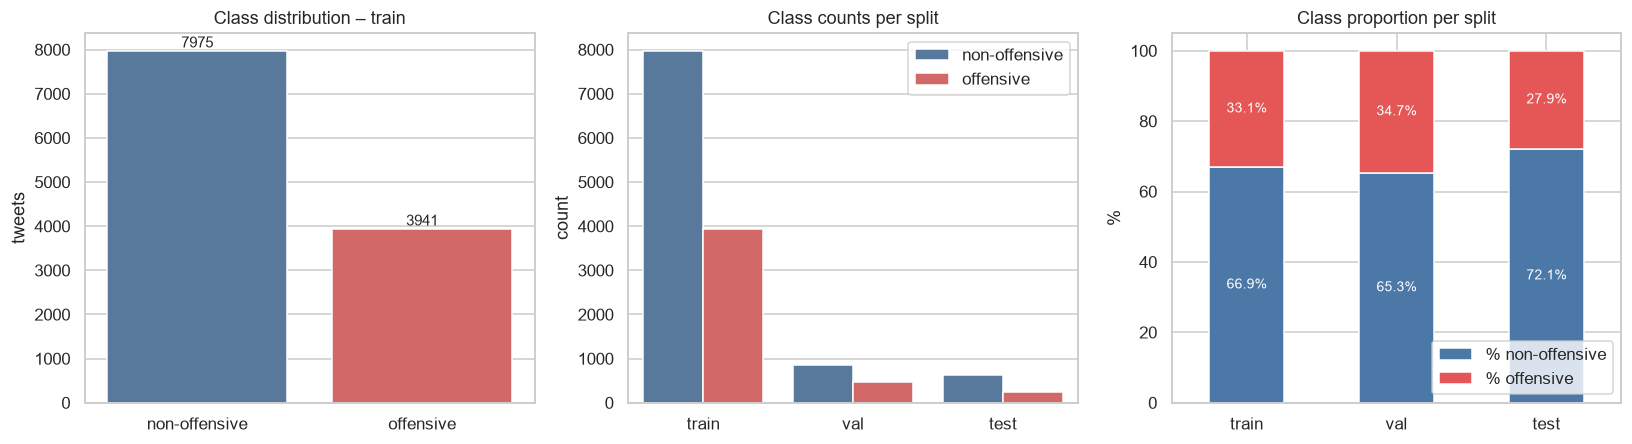

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))

# (a) class counts in train, with the value written above each bar
ax = axes[0]
sns.countplot(x="label_name", data=full_df[full_df.split == "train"],
              order=["non-offensive", "offensive"], palette=COLORS, ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Class distribution – train"); ax.set_xlabel(""); ax.set_ylabel("tweets")

# (b) class counts in each split
ax = axes[1]
sns.countplot(x="split", hue="label_name", data=full_df, hue_order=["non-offensive", "offensive"],
              palette=COLORS, ax=ax)
ax.set_title("Class counts per split"); ax.set_xlabel(""); ax.legend(title="")

# (c) class proportions (stacked bars, in %)
ax = axes[2]
prop = counts[["% non-offensive", "% offensive"]]
prop.plot(kind="bar", stacked=True, color=PALETTE, ax=ax, rot=0)
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
ax.set_title("Class proportion per split"); ax.set_xlabel(""); ax.set_ylabel("%"); ax.legend(title="", loc="lower right")

savefig(fig, "01_class_distribution.png")

**Results explained.**
- Panel (a) shows the train imbalance: 7,975 non-offensive vs 3,941 offensive tweets (about 2 to 1).
- Panel (b) shows that the three splits keep the same ordering (non-offensive > offensive), with very different sizes.
- Panel (c) shows the proportions: 66.9 / 33.1, 65.3 / 34.7 and 72.1 / 27.9.
- Why it matters: with fewer positives in test, the same false-positive rate gives a **lower precision**, so a gap between validation and test scores can come from the shift in class proportions and not necessarily from overfitting.

**Observations.**
- The corpus is **moderately imbalanced**: 33.1 % of train, 34.7 % of val and 27.9 % of test tweets are offensive. A trivial majority-class model already reaches ~0.67 accuracy, so models must be judged on **F1 / recall of the offensive class**.
- The proportion is **not identical across splits** (the official test set has fewer offensive tweets). This *distribution shift* is expected and explains why test scores may differ slightly from validation scores.

<a id="p1-6"></a>
## 1.6 Text length analysis
Number of **characters** and number of **words** per tweet, overall and per class.

In [11]:
full_df["n_chars"] = full_df["text"].str.len()                 # characters per tweet
full_df["n_words"] = full_df["text"].str.split().str.len()     # words per tweet (split on whitespace)

train_len = full_df[full_df.split == "train"]                  # statistics are computed on train only
print("=== Global statistics (train) ===")
display(train_len[["n_chars", "n_words"]].describe().round(2))

print("=== Statistics per class (train) ===")
display(train_len.groupby("label_name")[["n_chars", "n_words"]].describe().round(2).T)

print("=== Statistics per split (all tweets) ===")
display(full_df.groupby("split")[["n_chars", "n_words"]].mean().round(2))

=== Global statistics (train) ===


,n_chars,n_words
count,11916.00,11916.00
mean,125.76,22.02
std,86.46,15.05
min,8.00,2.00
25%,54.00,10.00
50%,102.00,18.00
75%,184.00,32.00
max,581.00,103.00


=== Statistics per class (train) ===


label_name     non-offensive  offensive
n_chars count        7975.00    3941.00
        mean          122.76     131.84
        std            86.33      86.42
        min             8.00      11.00
        25%            53.00      59.00
        50%            98.00     112.00
        75%           178.00     196.00
        max           577.00     581.00
n_words count        7975.00    3941.00
        mean           21.41      23.26
        std            14.98      15.12
        min             2.00       2.00
        25%             9.00      11.00
        50%            17.00      20.00
        75%            31.00      34.00
        max           103.00     101.00

=== Statistics per split (all tweets) ===


,n_chars,n_words
split,,
train,125.76,22.02
val,132.83,23.34
test,144.74,23.75


**Results explained.**
- Global (train): mean **125.8 characters / 22.0 words**, median 102 characters / 18 words, minimum 8 characters / 2 words, maximum 581 characters / 103 words. Mean > median means the distribution is **right-skewed**: many short tweets and a few very long ones.
- By class: offensive tweets are a little longer (mean 131.8 vs 122.8 characters, median 20 vs 17 words). The standard deviations are almost identical (86.4 vs 86.3), so the spread is the same and only a small shift separates the classes.
- By split: test tweets are **longer** (144.7 characters on average vs 125.8 in train, +15 %). This is a second difference between the official splits, in addition to the class proportions.

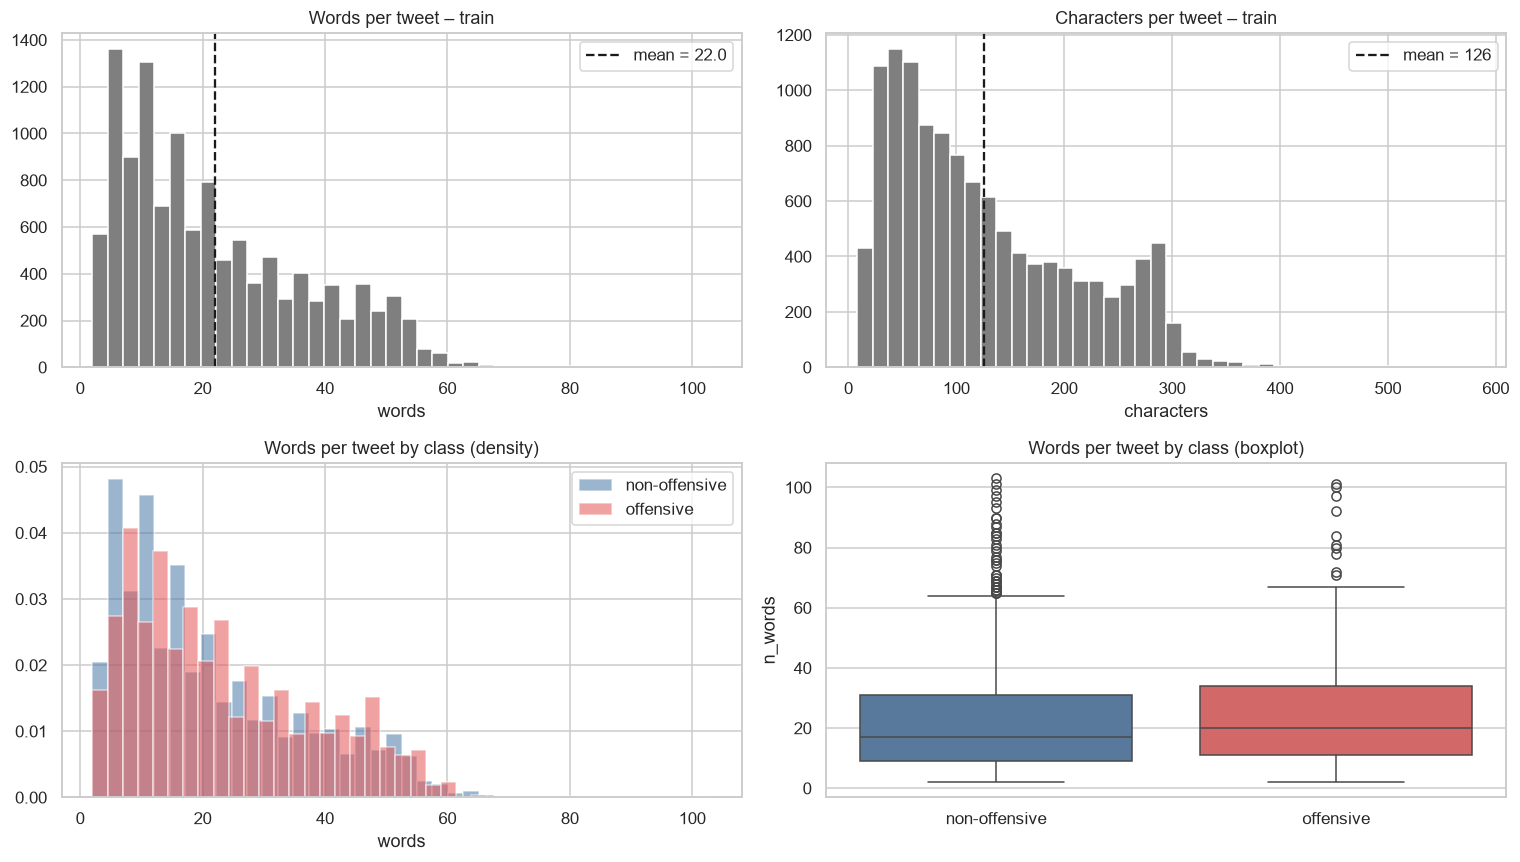

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Top row: global distributions (dashed line = mean)
axes[0, 0].hist(train_len["n_words"], bins=40, color="#7f7f7f", edgecolor="white")
axes[0, 0].axvline(train_len["n_words"].mean(), color="k", ls="--", label=f"mean = {train_len['n_words'].mean():.1f}")
axes[0, 0].set_title("Words per tweet – train"); axes[0, 0].set_xlabel("words"); axes[0, 0].legend()

axes[0, 1].hist(train_len["n_chars"], bins=40, color="#7f7f7f", edgecolor="white")
axes[0, 1].axvline(train_len["n_chars"].mean(), color="k", ls="--", label=f"mean = {train_len['n_chars'].mean():.0f}")
axes[0, 1].set_title("Characters per tweet – train"); axes[0, 1].set_xlabel("characters"); axes[0, 1].legend()

# Bottom-left: densities per class (density=True makes the two classes comparable despite different sizes)
for lab in ["non-offensive", "offensive"]:
    sub = train_len[train_len.label_name == lab]
    axes[1, 0].hist(sub["n_words"], bins=40, alpha=0.55, density=True, color=COLORS[lab], label=lab)
axes[1, 0].set_title("Words per tweet by class (density)"); axes[1, 0].set_xlabel("words"); axes[1, 0].legend()

# Bottom-right: boxplot (median, quartiles, outliers)
sns.boxplot(x="label_name", y="n_words", data=train_len, order=["non-offensive", "offensive"],
            palette=COLORS, ax=axes[1, 1])
axes[1, 1].set_title("Words per tweet by class (boxplot)"); axes[1, 1].set_xlabel("")

savefig(fig, "02_length_histograms.png")

**Results explained.**
- Both histograms (words and characters) are right-skewed, with the mean (dashed line) around 22 words / 126 characters, to the right of the bulk of the tweets.
- The class-density histogram and the boxplot show that the two classes **overlap heavily**: the offensive median is slightly higher (20 vs 17 words) and its quartiles are shifted a few words to the right (11-34 vs 9-31), but the shapes are the same.
- The few very long tweets (about 100 words) are mostly chains of `@user` (see the longest tweets in section 10), not real content.

In [13]:
a = train_len.loc[train_len.label == 0, "n_words"]      # lengths of non-offensive tweets
b = train_len.loc[train_len.label == 1, "n_words"]      # lengths of offensive tweets
# Mann-Whitney U: non-parametric test (no normality assumption) comparing two distributions
stat, p = mannwhitneyu(a, b)
print(f"Median words – non-offensive: {a.median():.0f} | offensive: {b.median():.0f}")
print(f"Mann-Whitney U test: U = {stat:.0f}, p-value = {p:.2e}")
print("-> difference is", "statistically significant" if p < 0.05 else "NOT statistically significant", "(alpha = 0.05)")

Median words – non-offensive: 17 | offensive: 20
Mann-Whitney U test: U = 14464391, p-value = 1.44e-12
-> difference is statistically significant (alpha = 0.05)


**Results explained.**
- Median length: 17 words (non-offensive) vs 20 words (offensive). The Mann-Whitney test (appropriate because length is not normally distributed) gives **U = 14,464,391 and p = 1.4e-12**, so the difference is statistically significant.
- Reading U: with 7,975 × 3,941 = 31.4 million pairs of tweets, U is the number of pairs where the non-offensive tweet is the longer one (ties count one half). U / pairs ≈ **0.46**, against 0.50 if length were unrelated to the class. The effect size is very small (rank-biserial correlation ≈ 0.08).
- The p-value is tiny only because the sample is large. Significant does not mean useful: length alone cannot separate the classes.

**Observations.**
- Tweets are **short** (a few dozen words at most), so the bag-of-words matrix will be **very sparse**.
- Offensive tweets are slightly longer, but the distributions overlap heavily: **length alone is not a useful discriminating feature** and the classifier must rely on the vocabulary.
- No extreme outliers need removal: very short tweets are valid and can still be offensive (e.g. a single insult).

<a id="p1-7"></a>
## 1.7 Stylistic / surface features
The assignment asks us to justify cleaning choices (negations, stop-words, hashtags, capitals…). To do so we measure how
frequent each of these elements is **per class**: an element that behaves differently between classes carries information
and should perhaps **not** be removed.

In TweetEval, user mentions are already anonymised as `@user` (≈ 92 % of tweets contain one) and, as the check below confirms, **URLs have already been removed** from the text.

In [14]:
# Emoji: unicode ranges of pictographs and symbols
EMOJI_RE = re.compile("[\U0001F300-\U0001FAFF\u2600-\u27BF\U0001F000-\U0001F2FF]")
# Negations: not/no/never..., contractions such as don't, and the generic suffix n't
NEGATION_RE = re.compile(r"\b(?:not|no|never|none|nobody|nothing|neither|nor|can't|cant|won't|don't|dont|doesn't|didn't|isn't|aren't|wasn't|weren't|n't)\b|n't\b", re.I)

# One boolean column per surface element: True if the tweet contains it
feat = pd.DataFrame({
    "mention":      full_df["text"].str.count(r"@\w+") > 0,
    "url":          full_df["text"].str.contains(r"http\S*|www\.", regex=True),
    "hashtag":      full_df["text"].str.contains(r"#\w+", regex=True),
    "emoji":        full_df["text"].apply(lambda t: bool(EMOJI_RE.search(t))),
    "exclamation !":full_df["text"].str.contains("!", regex=False),
    "question ?":   full_df["text"].str.contains("?", regex=False),
    "ALL-CAPS word":full_df["text"].apply(lambda t: any(w.isupper() and len(w) > 2 and w.isalpha() for w in t.split())),
    "elongation (sooo)": full_df["text"].str.contains(r"(\w)\1{2,}", regex=True),     # same letter 3+ times
    "negation":     full_df["text"].str.contains(NEGATION_RE),
    "profanity mask (* or ****)": full_df["text"].str.contains(r"\w\*+\w*|\*{2,}", regex=True),
})
feat["label_name"] = full_df["label_name"]
feat["split"] = full_df["split"]

# Percentage of tweets containing each element, per class (train only)
train_feat = feat[feat.split == "train"]
pct = (train_feat.drop(columns=["split"]).groupby("label_name").mean().T * 100).round(1)
pct["difference (off − non-off)"] = (pct["offensive"] - pct["non-offensive"]).round(1)
pct = pct[["non-offensive", "offensive", "difference (off − non-off)"]]
print("% of tweets containing each element (train):")
display(pct.sort_values("difference (off − non-off)", ascending=False))

% of tweets containing each element (train):


label_name,non-offensive,offensive,difference (off − non-off)
negation,25.7,29.3,3.6
ALL-CAPS word,14.6,16.6,2.0
mention,92.2,94.1,1.9
exclamation !,18.4,19.4,1.0
elongation (sooo),2.1,2.7,0.6
profanity mask (* or ****),0.7,1.0,0.3
url,0.0,0.0,0.0
question ?,15.2,14.3,-0.9
hashtag,15.4,12.6,-2.8
emoji,12.2,9.3,-2.9


**Results explained.** Share of train tweets containing each element, per class:
- Largest gaps, still small: **negation** 25.7 % vs 29.3 % (+3.6), **ALL-CAPS word** 14.6 % vs 16.6 % (+2.0), `!` 18.4 % vs 19.4 % (+1.0). In the other direction: **emoji** (12.2 % vs 9.3 %) and **hashtag** (15.4 % vs 12.6 %) are more frequent in non-offensive tweets.
- `@user` is in about 92-94 % of tweets of both classes, so it does not discriminate. **URLs: 0 %**, confirming that links were already removed from this version of the data.
- No surface feature differs by more than 4 points between the classes: none is a reliable signal on its own.
- Two caveats. (1) The ALL-CAPS test also catches acronyms such as MAGA, CNN or GOP, so it does not measure shouting only. (2) The negation regex only recognises the straight apostrophe (`don't`) and not the curly one (`don’t`), which is common in tweets; this probably underestimates negations. Part 2 finds about 31 % of train tweets with a negation after normalising the apostrophe, vs about 27 % here.

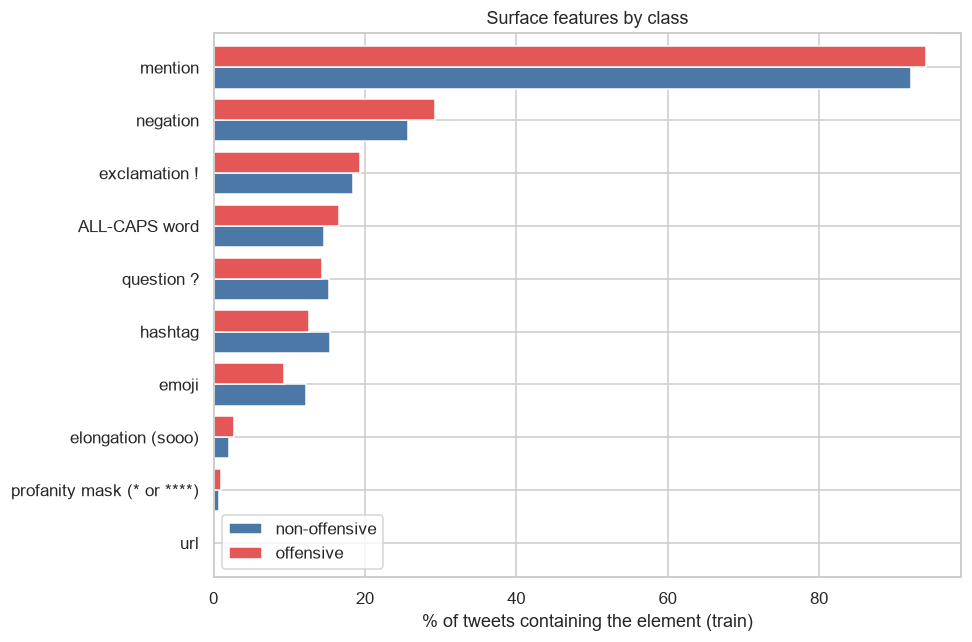

In [15]:
# Horizontal bars: the same table as above, sorted by the offensive-class percentage
plot_df = pct[["non-offensive", "offensive"]].sort_values("offensive")
ax = plot_df.plot(kind="barh", color=PALETTE, figsize=(9, 6), width=0.8)
ax.set_xlabel("% of tweets containing the element (train)")
ax.set_title("Surface features by class")
ax.legend(title="")

# IMPORTANT: ax.get_figure() returns the figure of THIS plot. (Using a stale `fig` variable from an earlier cell
# would save the wrong picture.)
savefig(ax.get_figure(), "03_surface_features.png")

**Results explained.**
- The bars show the same table as above, sorted by the offensive-class percentage: for every feature the red and blue bars have nearly the same length. Visually, the classes are very similar on surface features.
- The figure is saved with `ax.get_figure()`, so `03_surface_features.png` now contains this bar chart (in the previous version it could contain the length histograms).

In [16]:
# Numerical versions of the same features: how MANY mentions / hashtags / ... per tweet
num = pd.DataFrame({
    "n_mentions":   full_df["text"].str.count(r"@\w+"),
    "n_hashtags":   full_df["text"].str.count(r"#\w+"),
    "n_exclam":     full_df["text"].str.count("!"),
    "n_question":   full_df["text"].str.count(r"\?"),
    "n_caps_words": full_df["text"].apply(lambda t: sum(w.isupper() and len(w) > 2 and w.isalpha() for w in t.split())),
    # share of upper-case letters among all letters (max(1, ...) avoids a division by zero)
    "upper_ratio":  full_df["text"].apply(lambda t: sum(c.isupper() for c in t) / max(1, sum(c.isalpha() for c in t))),
})
num["label_name"] = full_df["label_name"]; num["split"] = full_df["split"]
display(num[num.split == "train"].groupby("label_name").mean(numeric_only=True).round(3))

,n_mentions,n_hashtags,n_exclam,n_question,n_caps_words,upper_ratio
label_name,,,,,,
non-offensive,2.752,0.443,0.361,0.221,0.327,0.078
offensive,2.032,0.325,0.438,0.238,0.451,0.077


**Results explained.** Mean counts per tweet (train):
- **Mentions**: 2.75 (non-offensive) vs 2.03 (offensive). Non-offensive tweets are more often part of long reply chains.
- **ALL-CAPS words**: 0.33 vs 0.45 (+38 % in relative terms) and **exclamation marks**: 0.36 vs 0.44 (+21 %): offensive tweets shout a little more.
- Hashtags (0.44 vs 0.33) and question marks (0.22 vs 0.24) differ very little.
- **upper_ratio** is **identical** (0.078 vs 0.077): offensive tweets do not contain more capital letters overall; they contain slightly more fully-capitalised words.
- Counts are small averages (below 3), so these differences are weak signals. Since Part 2 lowercases the text, the capitalisation cue is lost, which is accepted because it is so weak.

**Observations.** Differences between classes are small for most surface features (≤ 4 points). The largest are **negations** (29 % offensive vs 26 %) and ALL-CAPS words (+2 points); hashtags and emojis are slightly more common in non-offensive tweets. Masked profanity (`f***`) is rare (~1 %). These cues are weak individually, so we keep them (no aggressive cleaning) rather than rely on them.

**Implications for preprocessing.**

| Element | What we look for | Decision to take in Part 2 |
|---|---|---|
| `@user` mentions | present in ~92–94 % of tweets in both classes → almost no discriminating power | keep as the single placeholder `@user` or drop it |
| URLs (`http`) | 0 % of tweets in this version of the dataset | nothing to remove, but keep the regex for robustness |
| Hashtags | may contain topical words | keep the **word** (remove only `#`) |
| ALL-CAPS, `!` | shouting is a typical aggression cue | lowercasing loses it → consider a feature or keep `!` |
| Negations (`not`, `don't`) | change polarity ("not stupid") | **do not** remove them with the stop-words |
| Profanity masks (`f***`) | offensive even when obfuscated | keep `*` patterns or normalise them |
| Elongations (`sooo`) | emphasis | optional normalisation |

<a id="p1-8"></a>
## 1.8 Vocabulary analysis
Which words are the most frequent per class, and — more interesting — which words are **the most characteristic** of each class?

A minimal tokenizer (lowercase, alphabetic tokens) is used here for exploration only; the real cleaning is done in Part 2.

In [17]:
# Stop-words = standard English list + a few Twitter-specific tokens that carry no meaning here
STOP = set(ENGLISH_STOP_WORDS) | {"user", "http", "https", "amp", "rt", "im", "u"}
# A token = a letter followed by letters, apostrophes or asterisks (so "f***" survives)
TOKEN_RE = re.compile(r"[a-z][a-z'\*]+")

def tokenize(text, remove_stop=True):
    toks = TOKEN_RE.findall(text.lower())            # lowercase, then extract tokens
    toks = [t.strip("'") for t in toks]              # remove apostrophes at the edges
    if remove_stop:
        toks = [t for t in toks if t not in STOP and len(t) > 2]   # drop stop-words and very short tokens
    return toks

# One word counter per class (0 / 1), computed on the TRAIN set only
train_only = full_df[full_df.split == "train"]
counter = {lab: Counter() for lab in (0, 1)}
for lab, txt in zip(train_only["label"], train_only["text"]):
    counter[lab].update(tokenize(txt))

print("Distinct tokens (after stop-word removal)  non-offensive:", len(counter[0]), "| offensive:", len(counter[1]))
print("Total tokens                               non-offensive:", sum(counter[0].values()), "| offensive:", sum(counter[1].values()))

all_vocab = set(counter[0]) | set(counter[1])        # union of both vocabularies
print("Vocabulary size (train):", len(all_vocab))
print("Words appearing only once:", sum(1 for w in all_vocab if counter[0][w] + counter[1][w] == 1),
      "  → justifies min_df=2 in the TF-IDF")

Distinct tokens (after stop-word removal)  non-offensive: 13699 | offensive: 9117
Total tokens                               non-offensive: 70245 | offensive: 40326
Vocabulary size (train): 17295
Words appearing only once: 9374   → justifies min_df=2 in the TF-IDF


**Results explained.**
- After stop-word removal: **13,699 distinct tokens** in non-offensive tweets vs **9,117** in offensive ones; **70,245 vs 40,326 tokens in total**. The non-offensive class is larger simply because it has twice as many tweets. Per tweet it is the reverse: about 8.8 content tokens vs 10.2 for offensive tweets, consistent with them being longer.
- Combined vocabulary: **17,295** distinct tokens. Since 13,699 + 9,117 = 22,816, about 5,500 tokens (about one third) occur in **both** classes: the classes share a lot of vocabulary.
- **9,374 tokens (54 %) appear only once** in train: a long tail of rare words and typos. They cannot generalise to new tweets, which justifies `min_df=2` in the TF-IDF vectorizer.

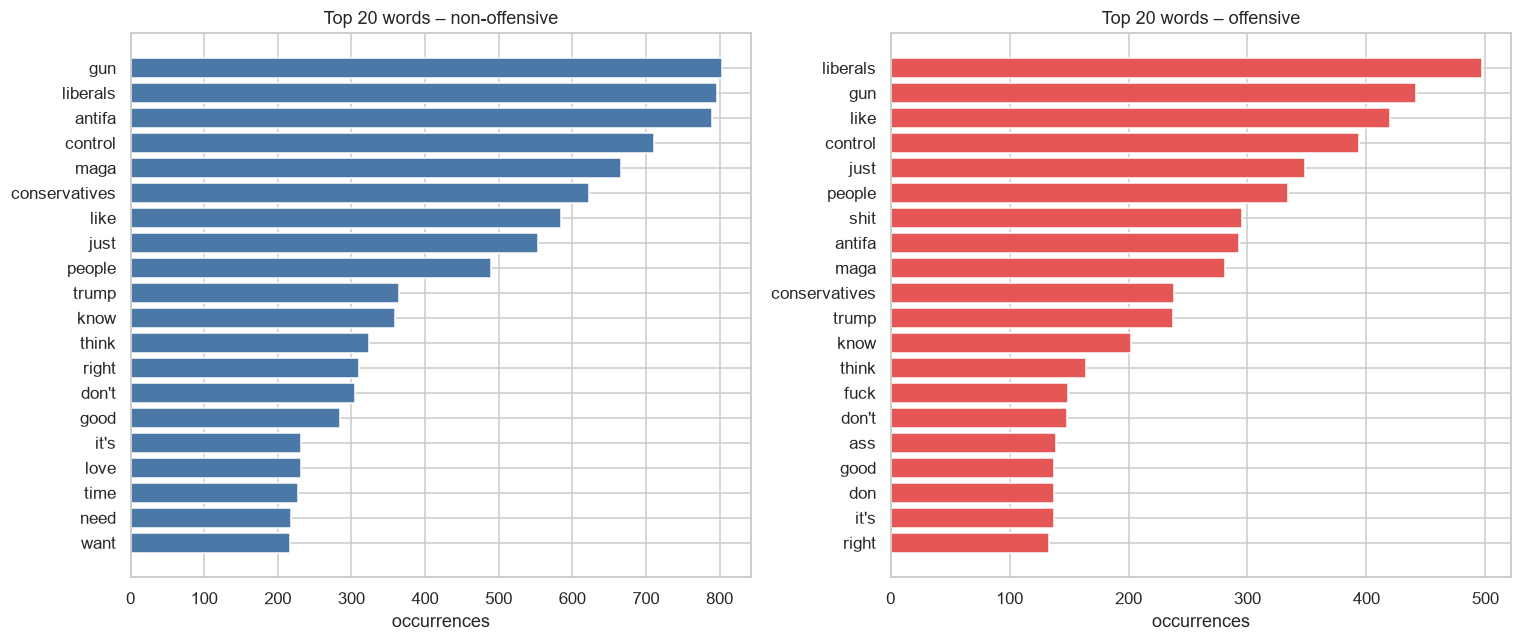

In [18]:
# Top 20 most frequent words of each class
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, lab in zip(axes, (0, 1)):
    name = LABEL_NAMES[lab]
    words, vals = zip(*counter[lab].most_common(20))       # 20 most frequent (word, count) pairs
    ax.barh(words[::-1], vals[::-1], color=COLORS[name])   # reversed so the most frequent is at the top
    ax.set_title(f"Top 20 words – {name}")
    ax.set_xlabel("occurrences")
savefig(fig, "04_top_words_per_class.png")

**Results explained.**
- The most frequent words are almost the same in both classes: `gun`, `control`, `liberals`, `antifa`, `maga`, `conservatives`, `trump`, `like`, `people`. The corpus is clearly **political** (gun control, US politics) in both classes, so topic words do not separate them.
- The only words that appear in the offensive top 20 but not in the non-offensive one are explicit: `shit`, `fuck`, `ass`. In the non-offensive top 20, `love`, `good`, `time`, `need` and `want` are present.
- **Tokenizer artefact**: `don` appears in the offensive list. The token regex does not include the curly apostrophe, so `don’t` is cut into `don` and `t` (and `t` is dropped as too short). This is why Part 2 converts `’` to `'`.
- Raw frequency is therefore poorly discriminative, which is why the log-odds ratio is used next.

Raw frequency is dominated by words common to both classes. A more informative measure is the **smoothed log-odds ratio**:

$$\text{score}(w) = \log\frac{(c_{off}(w)+1)/(N_{off}+V)}{(c_{non}(w)+1)/(N_{non}+V)}$$

A large positive score → the word is characteristic of the offensive class; a large negative score → of the non-offensive class.
The "+1" (Laplace smoothing) avoids dividing by zero for words absent from one class. Only words with at least 15 occurrences are kept to avoid noise.

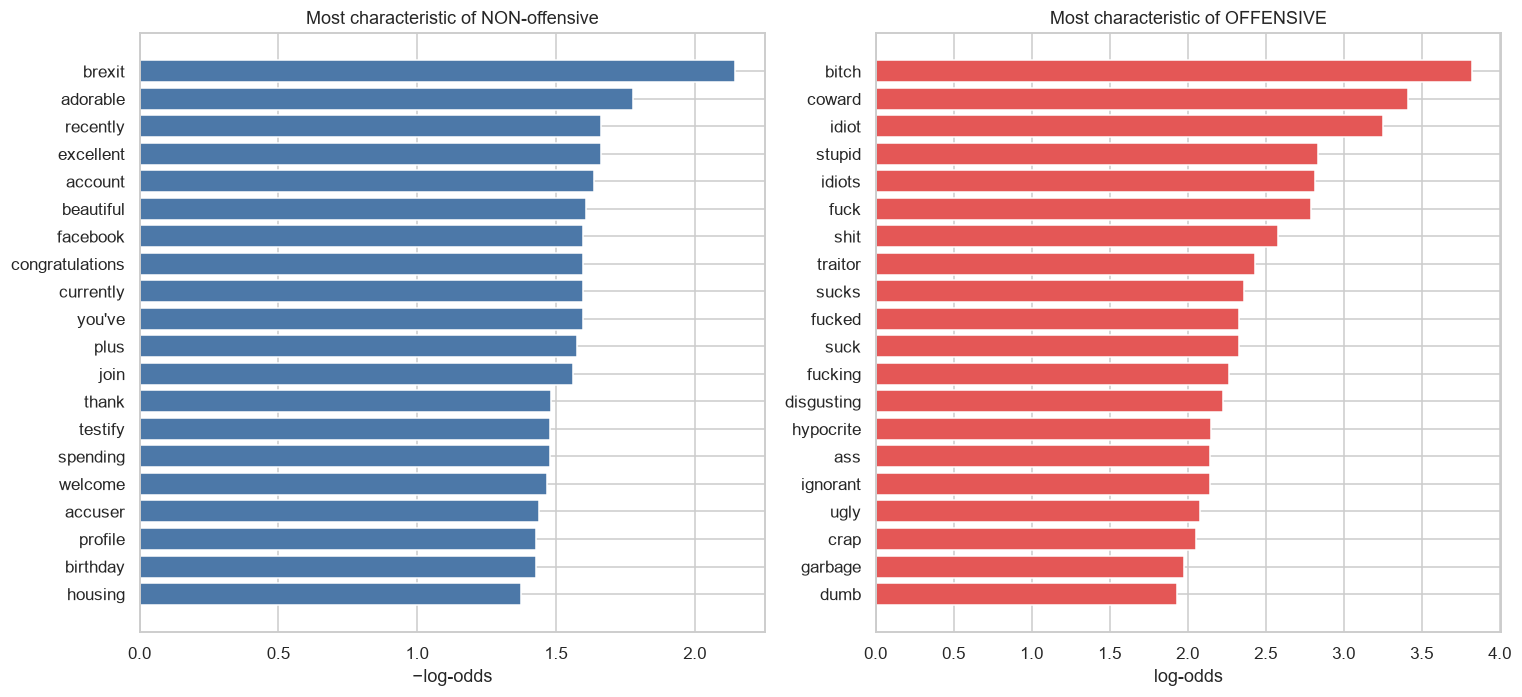

Top discriminative OFFENSIVE words (with counts):


,word,count_non_off,count_off,log_odds
0,bitch,2,89,3.82
1,coward,0,19,3.41
2,idiot,2,50,3.25
3,stupid,8,100,2.84
4,idiots,1,21,2.82
5,fuck,13,149,2.79
6,shit,33,295,2.58
7,traitor,1,14,2.43
8,sucks,5,41,2.36
9,fucked,3,26,2.33


In [19]:
V = len(all_vocab)                                           # vocabulary size (smoothing term)
N0, N1 = sum(counter[0].values()), sum(counter[1].values())  # total tokens per class

rows = []
for w in all_vocab:
    c0, c1 = counter[0][w], counter[1][w]                    # occurrences in non-offensive / offensive
    if c0 + c1 >= 15:                                        # ignore rare words (too noisy)
        score = np.log((c1 + 1) / (N1 + V)) - np.log((c0 + 1) / (N0 + V))
        rows.append((w, c0, c1, score))

lo = pd.DataFrame(rows, columns=["word", "count_non_off", "count_off", "log_odds"]).sort_values("log_odds")
top_off = lo.tail(20).iloc[::-1]     # 20 highest scores = most offensive-specific
top_non = lo.head(20)                # 20 lowest scores = most non-offensive-specific

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
axes[0].barh(top_non["word"][::-1], -top_non["log_odds"][::-1], color=COLORS["non-offensive"])
axes[0].set_title("Most characteristic of NON-offensive"); axes[0].set_xlabel("−log-odds")
axes[1].barh(top_off["word"][::-1], top_off["log_odds"][::-1], color=COLORS["offensive"])
axes[1].set_title("Most characteristic of OFFENSIVE"); axes[1].set_xlabel("log-odds")
savefig(fig, "05_discriminative_words.png")

print("Top discriminative OFFENSIVE words (with counts):")
display(top_off.head(10).round(2).reset_index(drop=True))

**Results explained.**
- **Offensive side**: the highest scores belong to insults and profanity: `bitch` (2 occurrences in non-offensive vs 89 in offensive, score 3.82), `coward` (0 vs 19), `idiot` (2 vs 50), `stupid` (8 vs 100), `fuck`, `shit`, `traitor`, `sucks`. A score of 3.82 means `bitch` is about **e^3.82 ≈ 46 times** more frequent (relative to class size, with smoothing) in offensive tweets.
- Profanity is not a perfect rule: `shit` occurs 33 times in non-offensive tweets, but 295 times in offensive ones (about 90 % of its occurrences).
- **Non-offensive side**: scores are weaker (maximum about 2.1, `brexit`, against 3.8). The vocabulary is polite or positive (`adorable`, `excellent`, `beautiful`, `congratulations`, `thank`, `welcome`, `birthday`) or simply neutral and topical (`brexit`, `facebook`, `account`, `housing`, `spending`, `testify`, `accuser`).
- Interpretation: the offensive class is defined by **the presence of insults**, whereas the non-offensive class is mostly defined by **their absence**. Some non-offensive markers reflect news topics of the collection period and may not generalise.

**Observations.**
- The **offensive** class is characterised by insults and profanity (`bitch`, `idiot`, `stupid`, `fuck`, `shit`, `coward`…), which is why a lexical model (TF-IDF + linear classifier) should work reasonably well.
- The **non-offensive** class is characterised by neutral / positive or topical vocabulary.
- About 54 % of the 17,295 training tokens appear only once → long-tailed vocabulary; `min_df=2` and `max_features` in TF-IDF reduce noise and dimensionality.
- Offensiveness is sometimes **contextual** (sarcasm, implicit insults) and cannot be captured by single words: this limits bag-of-words models and motivates `ngram_range=(1, 2)`.

<a id="p1-9"></a>
## 1.9 WordClouds per class
Word size is proportional to frequency (stop-words, `@user` and `http` removed).

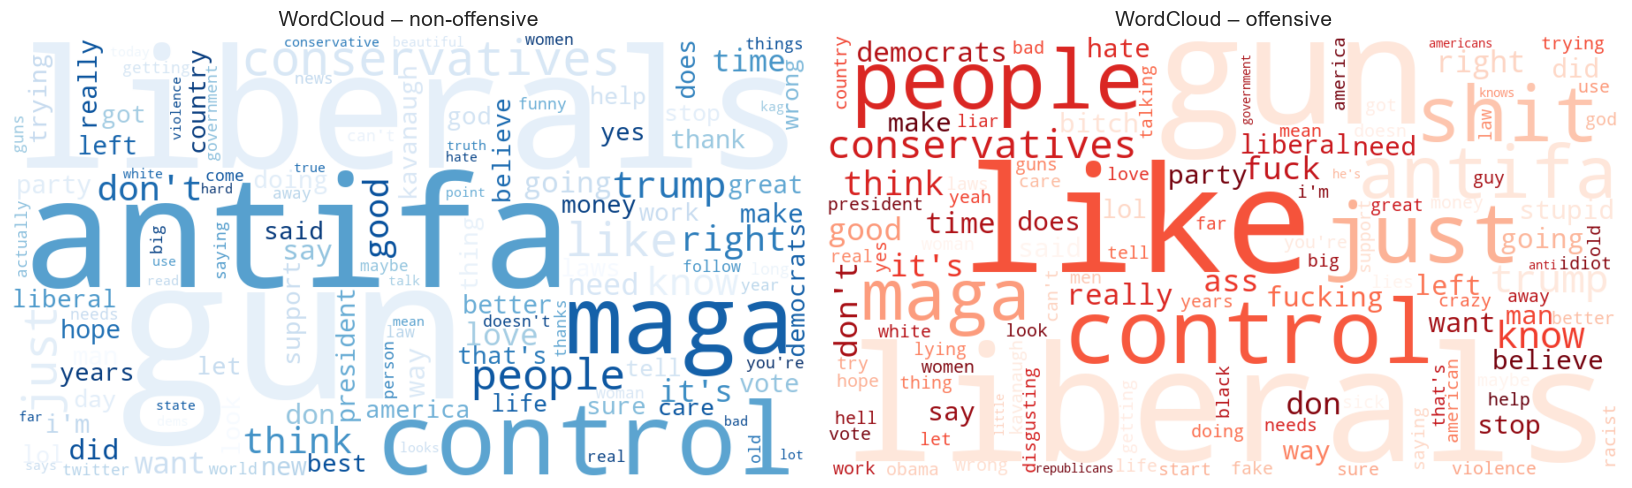

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cmaps = {0: "Blues", 1: "Reds"}                              # colour maps matching the class colours
for ax, lab in zip(axes, (0, 1)):
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmaps[lab],
                   max_words=120, random_state=42).generate_from_frequencies(counter[lab])   # fixed seed = reproducible
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"WordCloud – {LABEL_NAMES[lab]}", fontsize=14)
savefig(fig, "06_wordclouds.png")

**Results explained.**
- The clouds are built from the same frequency counts as the bar charts, so the largest words are those of the top-20 charts: political vocabulary (`gun`, `control`, `liberals`, `antifa`, `maga`, `trump`) in both classes.
- The two clouds look alike, which confirms that **what people talk about** does not tell the classes apart. Only a few words (`shit`, `fuck`, `ass`) visibly distinguish the offensive cloud.

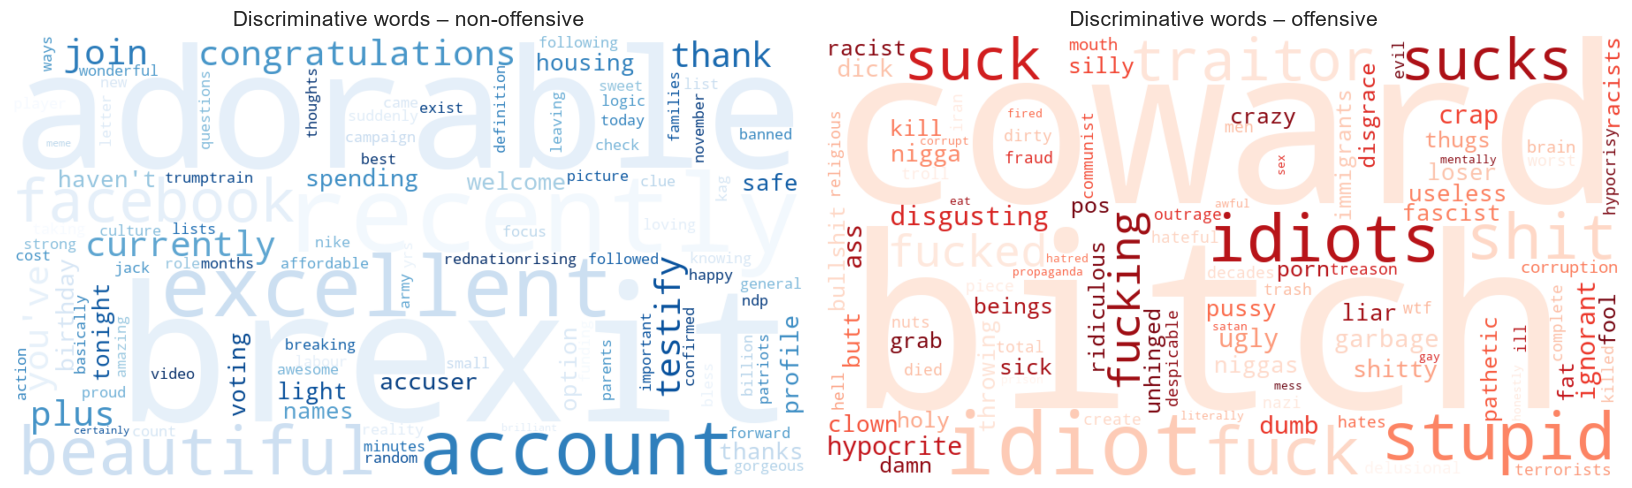

In [21]:
# Second pair of clouds: word size = log-odds score instead of raw frequency
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
pos = lo[lo.log_odds > 0].set_index("word")["log_odds"].to_dict()                       # offensive-specific words
neg = {w: -s for w, s in lo[lo.log_odds < 0].set_index("word")["log_odds"].to_dict().items()}   # sign flipped: sizes must be > 0
for ax, freqs, lab in zip(axes, (neg, pos), (0, 1)):
    wc = WordCloud(width=900, height=500, background_color="white", colormap=cmaps[lab],
                   max_words=100, random_state=42).generate_from_frequencies(freqs)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(f"Discriminative words – {LABEL_NAMES[lab]}", fontsize=14)
savefig(fig, "07_wordclouds_discriminative.png")

**Results explained.**
- These clouds use the log-odds score as word size, so each cloud shows what **distinguishes** its class.
- Offensive cloud: insults (`bitch`, `idiot(s)`, `stupid`, `coward`), profanity, and attack words (`hypocrite`, `liar`, `loser`, `useless`, `clown`, `traitor`). It also contains **political and identity words** (`racist(s)`, `fascist`, `immigrants`, `terrorists`, `gay`) and some racial slurs.
- Non-offensive cloud: friendly or neutral words (`adorable`, `excellent`, `beautiful`, `congratulations`, `thank`, `welcome`, `birthday`) and topical words (`brexit`, `facebook`, `account`, `housing`). It is paler than the offensive one because its scores are lower.
- **Bias warning**: identity words such as `immigrants` or `gay` appear because they are used in offensive tweets in this corpus, not because they are offensive themselves. A bag-of-words model may learn to flag neutral tweets that merely mention these groups; this deserves a sentence in the limitations of the report.

**Note.** The first pair of clouds is based on frequency and shows what people talk about; the second pair is based on the log-odds score and highlights what **distinguishes** the classes — it is the more relevant one for classification. *Content warning: the offensive cloud contains vulgar words.*

<a id="p1-10"></a>
## 1.10 Example tweets
Reading real examples helps to spot difficulties that statistics cannot show (sarcasm, quoted insults, missing context).

In [22]:
pd.set_option("display.max_colwidth", 200)       # show the full tweet in the tables
print("=== 8 random NON-offensive tweets ===")
display(train_df[train_df.label == 0].sample(8, random_state=1)[["text"]].reset_index(drop=True))
print("=== 8 random OFFENSIVE tweets (content warning) ===")
display(train_df[train_df.label == 1].sample(8, random_state=1)[["text"]].reset_index(drop=True))

=== 8 random NON-offensive tweets ===


,text
0,@user What??? She is cute but she doesn't look like me at all
1,@user @user Thank you @user
2,#MAGA Sing like no one is listening Love like you've never been hurt Vote GOP when no one is watching And don't listen to Liberals' dirt
3,Remind me again why exactly there's a lingerie store next to a krav maga dojo
4,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...
5,@user She is!!! 😍
6,@user @user so you say. When you are older you may understand. What anyone believes is quite irrelevant--as you yourself are asserting.
7,@user And god forbid you are already talking to someone or dating they get real mad 😂🤷🏼‍♀️ we like those people over you for a reason sorry bout it 😂


=== 8 random OFFENSIVE tweets (content warning) ===


,text
0,@user So has the Law changed...you just make an allegation now days and your guilty until proven innocent. Liberals are mentally ill!
1,@user @user @user For the love of all things sacred he cannot be voted in. He is well down towrds the bottom of that scummy swamp. The Scales of Justice need to let him drown in his own shit. Make...
2,@user THE DEVIL MADE ME DO IT!!!!! THE UGLY FACE OF LIBERALS! I FEEL SORRY FOR THE INNOCENT HONEST ONES THAT ARE JUST BRAINWASHED!
3,@user State Sponsored Kids Protesting the 2nd Amendment? Youth invasion of D.C. took place as young fascists-in-training were corralled into D.C. to demand that govt strip away the liberties of ...
4,@user Wtf aren’t they treating antifa as terrorism?
5,Really # MAGA VOTE TRUMP 2020
6,@user Cuz liberals are sick of cnn!!!!
7,"@user @user @user This is fun, I asked him for proof and he blocked me. I was about to joke about how he'd go from The Antifa are the real Nazis!"""" to similar alt-shite talking points, boy that su..."


**Results explained** (8 + 8 random tweets, small sample, so only indicative).
- Non-offensive tweets are varied: thanks, compliments, jokes, a tweet that is only a chain of `@user`, and a neutral political hashtag post.
- Offensive tweets are **all political**: attacks on groups ("Liberals are mentally ill!", "the ugly face of liberals", "young fascists-in-training"), some with profanity (`shit`, `shite`, `Wtf`), many without any swear word.
- Some labels are hard to explain from the text alone: "Really # MAGA VOTE TRUMP 2020" or "Cuz liberals are sick of cnn!!!!" are labelled offensive without any insult. The label depends on context (target, tone, the tweet being replied to) that is not in the text.
- Consequences: topic and label are correlated (the model may learn that "political = offensive"), and a bag-of-words model has a ceiling because of implicit and context-dependent offensiveness.

In [23]:
# Extremes: the 5 shortest and the 5 longest tweets of train
tl = full_df[full_df.split == "train"].sort_values("n_words")
print("=== 5 shortest tweets ===")
display(tl.head(5)[["text", "label_name", "n_words"]].reset_index(drop=True))
print("=== 5 longest tweets ===")
display(tl.tail(5)[["text", "label_name", "n_words"]].reset_index(drop=True))

=== 5 shortest tweets ===


,text,label_name,n_words
0,@user well...?,non-offensive,2
1,@user Fool,offensive,2
2,@user Horrible.,offensive,2
3,@user Boycott,non-offensive,2
4,@user Sucks,offensive,2


=== 5 longest tweets ===


,text,label_name,n_words
0,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,99
1,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,offensive,100
2,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,offensive,101
3,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,101
4,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @use...,non-offensive,103


**Results explained.**
- **Shortest tweets (2 words)**: the single word after `@user` carries the label: `Fool`, `Horrible.`, `Sucks` are offensive, while `well...?` and `Boycott` are not. A model must handle very short texts correctly; these tweets should not be removed.
- **Longest tweets (99-103 words)**: all start with a very long chain of `@user`, so their length reflects the number of people tagged, not the amount of text written. Their labels are mixed (3 non-offensive, 2 offensive).
- This is why the word-count statistics of section 6 are inflated by mentions, and why the cleaning step (which keeps one `user` token per mention) barely changes tweet length.

<a id="p1-11"></a>
## 1.11 Conclusions & implications for preprocessing

### Key findings
| # | Finding | Consequence |
|---|---|---|
| 1 | Two clean columns (`text`, `label`), no missing values, official train / val / test splits | no imputation; use the official splits as-is |
| 2 | **Moderate class imbalance** (~1/3 offensive in train, different share in test) | report precision, recall and **F1 of the offensive class**, not only accuracy; consider `class_weight='balanced'` |
| 3 | Tweets are short with a heavy-tailed vocabulary | sparse TF-IDF, `min_df=2`, `max_features≈20 000` |
| 4 | Mentions are anonymised (`@user`, ~93 % of tweets, same rate in both classes); URLs are already absent | no real signal → normalise or drop `@user` |
| 5 | Offensive tweets are strongly marked by profanity / insult words | lexical features (TF-IDF unigrams + bigrams) are appropriate |
| 6 | Negations, `!`, capitals, masked profanity (`f***`) may carry information | **do not** blindly remove all stop-words, keep negations and `*` patterns |
| 7 | Some offensiveness is contextual / sarcastic | expected ceiling for bag-of-words models; BERT-type models are a possible extension |

<a id="p1-12"></a>
## 1.12 Saving the results
Summary statistics are stored in `results/metrics/01_data_exploration/` so they can be re-used in the report and the final synthesis (Part 7).
Figures were already saved in `results/figures/01_data_exploration/`.

In [24]:
# Summary table: class counts + average length per split
summary = counts.copy()
summary["avg_words"] = full_df.groupby("split")["n_words"].mean().round(2)
summary["avg_chars"] = full_df.groupby("split")["n_chars"].mean().round(2)

EDA_MET_DIR.mkdir(parents=True, exist_ok=True)    # safety: recreate the folder if it was deleted since the setup cell

summary.to_csv(EDA_MET_DIR / "eda_summary.csv")                                                    # sizes, balance, lengths
pct.to_csv(EDA_MET_DIR / "eda_surface_features.csv")                                               # % of tweets per surface element
lo.sort_values("log_odds").to_csv(EDA_MET_DIR / "eda_discriminative_words.csv", index=False)       # log-odds table
quality_df.to_csv(EDA_MET_DIR / "eda_quality_checks.csv")                                          # index kept: it holds the split names

print("Saved metrics:", sorted(p.name for p in EDA_MET_DIR.glob("eda_*.csv")))
print("Saved figures:", sorted(p.name for p in EDA_FIG_DIR.glob("0*.png")))

Saved metrics: ['eda_discriminative_words.csv', 'eda_quality_checks.csv', 'eda_summary.csv', 'eda_surface_features.csv']
Saved figures: ['01_class_distribution.png', '02_length_histograms.png', '03_surface_features.png', '04_top_words_per_class.png', '05_discriminative_words.png', '06_wordclouds.png', '07_wordclouds_discriminative.png']


**Results explained.**
- Four metric files are saved (`eda_summary.csv`, `eda_surface_features.csv`, `eda_discriminative_words.csv`, `eda_quality_checks.csv`) and seven figure files (`01` to `07`) exist in `results/figures/01_data_exploration/`, so everything the report needs from this part can be reused without rerunning it.
- Both listings read from the same folders the files were written to (`EDA_MET_DIR`, `EDA_FIG_DIR`), so they always match.
- Hand-over to Part 2: keep negations, hashtag words and masked profanity; remove URLs, HTML entities and punctuation; do not drop `@user` information blindly.

---

<a id="part2"></a>
# Part 2 · Text cleaning




---

### Contents
1. [Setup](#p2-1)
2. [Loading the raw data](#p2-2)
3. [Cleaning decisions (justified by the EDA)](#p2-3)
4. [Testing `clean_text()` on edge cases](#p2-4)
5. [Applying the cleaning](#p2-5)
6. [Verification](#p2-6)
7. [Impact of each cleaning rule](#p2-7)
8. [Vocabulary before / after](#p2-8)
9. [Saving the cleaned datasets](#p2-9)
10. [Conclusions and hand-over](#p2-10)

<a id="p2-1"></a>
## 2.1 Setup
The cleaning logic lives in `src/preprocessing.py` (reusable code stays in `src/`, notebooks only call it).

In [25]:
import re, sys, html, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 140)

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

RAW_DIR  = PROJECT_ROOT / "data" / "raw"
PROC_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR  = PROJECT_ROOT / "results" / "figures" / "02_text_cleaning"
MET_DIR  = PROJECT_ROOT / "results" / "metrics" / "02_text_cleaning"
for d in (RAW_DIR, PROC_DIR, FIG_DIR, MET_DIR):
    d.mkdir(parents=True, exist_ok=True)

LABEL_NAMES = {0: "non-offensive", 1: "offensive"}
COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}

def savefig(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")
    plt.show()

from src.preprocessing import clean_text, clean_dataframe
print("Project root:", PROJECT_ROOT)

Project root: c:\Users\ASUS\Desktop\TweetEval-offensiveML


**Results explained.**
- The import `from src.preprocessing import clean_text, clean_dataframe` succeeded, so the reusable cleaning code exists in `src/`; this part only calls it.
- The output folders (`data/processed`, `results/figures/02_text_cleaning`, `results/metrics/02_text_cleaning`) are created if missing. The printed root is the same project folder as in Part 1.

<a id="p2-2"></a>
## 2.2 Loading the raw data
Raw files in `data/raw/` are **never edited**. They are downloaded from the official repository if missing.

In [26]:
import urllib.request

BASE_URL = "https://raw.githubusercontent.com/cardiffnlp/tweeteval/main/datasets/offensive/"
for fname in [f"{s}_{k}.txt" for s in ("train", "val", "test") for k in ("text", "labels")]:
    if not (RAW_DIR / fname).exists():
        print("Downloading", fname)
        urllib.request.urlretrieve(BASE_URL + fname, RAW_DIR / fname)

try:
    from src.data_loader import load_all
except ImportError:
    def _read_lines(path):
        with open(path, encoding="utf-8") as f:
            return [line.rstrip("\n") for line in f]

    def load_all(raw_dir=RAW_DIR):
        out = []
        for s in ("train", "val", "test"):
            texts = _read_lines(Path(raw_dir) / f"{s}_text.txt")
            labels = [int(x) for x in _read_lines(Path(raw_dir) / f"{s}_labels.txt")]
            assert len(texts) == len(labels), f"{s}: texts/labels mismatch"
            out.append(pd.DataFrame({"text": texts, "label": labels}))
        return tuple(out)

train_df, val_df, test_df = load_all()

orig_labels = {"train": train_df["label"].copy(), "val": val_df["label"].copy(), "test": test_df["label"].copy()}

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(d):>6} tweets | offensive = {100*d['label'].mean():.1f} %")
display(train_df.head())

train:  11916 tweets | offensive = 33.1 %
val  :   1324 tweets | offensive = 34.7 %
test :    860 tweets | offensive = 27.9 %


,text,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become a Leader of your pe...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with his reads. He brough...,0
3,@user @user She is great. Hi Fiona!,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could be optic too Who k...,1


**Results explained.**
- Sizes and class shares are **identical to Part 1**: 11,916 / 1,324 / 860 tweets with 33.1 % / 34.7 % / 27.9 % offensive. Cleaning starts from the same raw data, and these percentages are the reference used later to prove that cleaning does not change the class distribution.
- A copy of the original labels is stored in `orig_labels` for that later comparison.
- The head shows raw tweets (mentions, capitals, punctuation); the display is simply truncated by the column width.

<a id="p2-3"></a>
## 2.3 Cleaning decisions (justified by the EDA)

The assignment asks to **justify** every cleaning choice, because some elements carry useful information.
The decisions below rely on what Part 1 showed.

| # | Element | EDA evidence | Decision | Why |
|---|---|---|---|---|
| 1 | **Upper case** | ALL-CAPS words only ~2 points more frequent in offensive tweets | → lowercase | Merges `Idiot` / `idiot` / `IDIOT` and shrinks the vocabulary; the small "shouting" signal is accepted as a loss |
| 2 | **HTML entities** (`&amp;`, `&lt;`) | appear as noise tokens (`amp`) in the vocabulary | → decoded (`&amp;` → `&`) then removed with punctuation | `amp` is not a word |
| 3 | **URLs** | 0 % of tweets contain one in this version of the data | → removed (rule kept for robustness) | no information |
| 4 | **@mentions** | ~93 % of tweets, same rate in both classes | → replaced by the single token `user` | keeps the "addressed to someone" structure without a thousand names |
| 5 | **Hashtags** | 12–15 % of tweets, may contain topical words | → remove only the `#`, **keep the word** | `#idiots` → `idiots` is informative |
| 6 | **Punctuation, emojis, symbols** | `!`, `?` rates nearly identical in both classes | → removed | required by the assignment; low discriminating power |
| 7 | **Apostrophes inside words** (`don't`, `can't`) | negations are the strongest style cue (29 % offensive vs 26 %) | → **kept** | removing the apostrophe would create fake tokens (`don`, `t`) and destroy the negation |
| 8 | **Asterisks used as a mask** (`f***`, `sh*t`, `f**k`) | masked profanity is rare (< 1 %) but obviously offensive | → **kept** | the obfuscated insult remains recognisable |
| 8b | **Asterisks used as emphasis** (`*inhales*`, `word*`) | action markers, no offensive signal | → removed | rule: keep a run of ≥ 2 `*` or an `*` inside a word; strip leading / lone trailing ones |
| 9 | **Numbers** | no evidence they matter | → kept | not harmful, not worth a rule |
| 10 | **Stopwords** | negations (`not`, `no`) are in the standard lists | → **not removed here** | tested separately in Part 3, which protects negations |
| 11 | **Lemmatisation** | – | → **not applied here** | evaluated separately in Part 3 |
| 12 | **Class proportions / labels** | imbalanced (≈ 2:1) | → **never modified** | balancing is an experiment of Part 4, on train only |

> **Known limitations.** (i) `#MakeAmericaGreatAgain` becomes `makeamericagreatagain` (a single unknown token) because camel-case is lost
> after lowercasing. (ii) Elongations (`sooo`) are not normalised. (iii) Non-English characters are dropped. Each affects a small share of tweets.

<a id="p2-4"></a>
## 2.4 Testing `clean_text()` on edge cases
Before touching the 14 000 tweets we check the function on hand-made examples, one per rule. The `assert` lines make the notebook fail loudly
if someone modifies `preprocessing.py` and breaks a rule (the same checks exist in `tests/test_preprocessing.py`).

In [27]:
cases = [
    ("@user I HATE this! #politics",              "user i hate this politics"),
    ("I don't like this person.",                 "i don't like this person"),
    ("I don’t know (curly apostrophe)",           "i don't know curly apostrophe"),
    ("Visit https://example.com now",             "visit now"),
    ("You are f*** annoying !!! ***",             "you are f*** annoying"),
    ("sigh *INHALES* ok, what a sh*t f**k",       "sigh inhales ok what a sh*t f**k"),
    ("cats &amp; dogs 😂 <3",                      "cats dogs"),
    ("Such a #BlackLivesMatter_movement",         "such a blacklivesmatter movement"),
    ("   too     many    spaces   ",              "too many spaces"),
    ("'quoted' word",                             "quoted word"),
    ("Call 911 NOW",                              "call 911 now"),
    ("",                                          ""),
    ("!!! ??? ...",                               ""),
]
rows = []
for raw, expected in cases:
    got = clean_text(raw)
    rows.append({"original": raw, "cleaned": got, "expected": expected, "OK": got == expected})
res = pd.DataFrame(rows)
display(res)
assert res["OK"].all(), "A cleaning rule does not behave as documented!"
assert clean_text(None) == "" and clean_text(float("nan")) == ""
print("✔ All edge-case tests passed")

,original,cleaned,expected,OK
0,@user I HATE this! #politics,user i hate this politics,user i hate this politics,True
1,I don't like this person.,i don't like this person,i don't like this person,True
2,I don’t know (curly apostrophe),i don't know curly apostrophe,i don't know curly apostrophe,True
3,Visit https://example.com now,visit now,visit now,True
4,You are f*** annoying !!! ***,you are f*** annoying,you are f*** annoying,True
5,"sigh *INHALES* ok, what a sh*t f**k",sigh inhales ok what a sh*t f**k,sigh inhales ok what a sh*t f**k,True
6,cats &amp; dogs 😂 <3,cats dogs,cats dogs,True
7,Such a #BlackLivesMatter_movement,such a blacklivesmatter movement,such a blacklivesmatter movement,True
8,too many spaces,too many spaces,too many spaces,True
9,'quoted' word,quoted word,quoted word,True


✔ All edge-case tests passed


**Results explained.** All 13 hand-made cases pass (`OK = True`) and the two `assert` lines confirm that `None` and `NaN` become an empty string. Rule by rule:
- `@user I HATE this! #politics` -> `user i hate this politics`: mention replaced by `user`, lowercase, `!` removed, hashtag word kept.
- Straight and curly apostrophes give the **same token** `don't`, so the negation is not split into `don` + `t`.
- URL removed completely; `&amp;` decoded then removed (no `amp` token); emoji and `<3` removed.
- `f***` and `sh*t f**k` are **kept** (masked profanity); lone `***` and emphasis stars (`*INHALES*` -> `inhales`) are removed.
- `#BlackLivesMatter_movement` -> `blacklivesmatter movement`: the underscore becomes a space and the camel-case is lost (known limitation).
- Extra spaces collapsed, quotes around a word removed, digits kept (`911`), empty and punctuation-only strings give `""` without error.
- Limit of this test: it proves each rule in isolation; the following sections check the behaviour on real data.

<a id="p2-5"></a>
## 2.5 Applying the cleaning
`clean_dataframe()` returns a **copy** with a new column `text_clean`; the original `text` column is kept for comparison.

In [28]:
train_df = clean_dataframe(train_df)
val_df   = clean_dataframe(val_df)
test_df  = clean_dataframe(test_df)

display(train_df[["text", "text_clean", "label"]].head(10))

,text,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become a Leader of your pe...,user bono who cares soon people will understand that they gain nothing from following a phony celebrity become a leader of your people i...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with his reads. He brough...,user get him some line help he is gonna be just fine as the game went on you could see him progressing more with his reads he brought wh...,0
3,@user @user She is great. Hi Fiona!,user user she is great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could be optic too Who k...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be optic too who know wit...,1
5,"@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user This is the VetsResistSquadron"""" is Bullshit.....",user user user user user user user user user user user user user user user this is the vetsresistsquadron is bullshit they are girl scou...,0
6,@user Your looking more like a plant #maga #walkaway,user your looking more like a plant maga walkaway,1
7,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...,0
8,@user Been a Willie fan since before most of you were born....LOVE that he is holding a rally with Beto.... Exactly WHICH fans are furio...,user been a willie fan since before most of you were born love that he is holding a rally with beto exactly which fans are furious could...,0
9,@user Here's a link to my channel with a plethora of topics to peruse:,user here's a link to my channel with a plethora of topics to peruse,0


**Results explained.**
- The new column `text_clean` appears next to the untouched `text` column and the label.
- Visible effects on real tweets: each mention becomes `user` (row 3: `user user she is great hi fiona`), everything is lowercase, punctuation disappears (`such an....well idiot` -> `such an well idiot`), the curly apostrophe is normalised (`obama’s` -> `obama's`) and hashtags lose only their `#` (`#maga #walkaway` -> `maga walkaway`).
- One `user` token is kept per mention, so chains such as row 5 (15 mentions) stay long. This preserves the mention count, which differs slightly between classes in Part 1 (2.75 vs 2.03 on average).

<a id="p2-6"></a>
## 2.6 Verification
We check, for each split: row count, missing values, empty cleaned tweets, **labels unchanged**, and the effect on tweet length.

In [29]:
raw_counts = {"train": 11916, "val": 1324, "test": 860}
splits = {"train": train_df, "val": val_df, "test": test_df}

checks = []
for name, d in splits.items():
    checks.append({
        "split": name,
        "rows": len(d),
        "rows == official size": len(d) == raw_counts[name],
        "missing text_clean": int(d["text_clean"].isna().sum()),
        "empty text_clean": int((d["text_clean"].str.strip() == "").sum()),
        "labels unchanged": bool((d["label"].values == orig_labels[name].values).all()),
        "% offensive": round(100 * d["label"].mean(), 2),
    })
checks_df = pd.DataFrame(checks).set_index("split")
display(checks_df)

assert checks_df["labels unchanged"].all() and checks_df["missing text_clean"].eq(0).all()
print("✔ Row counts, missing values and labels are correct")

,rows,rows == official size,missing text_clean,empty text_clean,labels unchanged,% offensive
split,,,,,,
train,11916,True,0,0,True,33.07
val,1324,True,0,0,True,34.67
test,860,True,0,0,True,27.91


✔ Row counts, missing values and labels are correct


**Results explained.**
- For every split: the row count equals the official size, **no missing `text_clean`, no empty cleaned text, labels unchanged**.
- The offensive percentages (33.07 / 34.67 / 27.91) are exactly those of the raw data, so cleaning modified neither labels nor class proportions. Both `assert` statements passed.

In [30]:
for name, d in splits.items():
    empty = d[d["text_clean"].str.strip() == ""]
    if len(empty):
        print(f"--- {name}: {len(empty)} empty tweets (label counts: {empty['label'].value_counts().to_dict()})")
        display(empty[["text", "text_clean", "label"]].head())
    else:
        print(f"--- {name}: no tweet became empty")

--- train: no tweet became empty
--- val: no tweet became empty
--- test: no tweet became empty


**Results explained.**
- **No tweet became empty** in any split, so no row has to be removed and text/label alignment is guaranteed.
- A nuance: about 93 % of tweets contain a mention that is kept as `user`, so they can never become empty. The check is really informative only for the remaining tweets, and it shows that even the shortest ones (e.g. `Sucks`) keep at least a word.

,avg words (raw),avg words (clean),reduction %
train,22.02,21.94,0.38
val,23.34,23.26,0.34
test,23.75,23.75,0.02


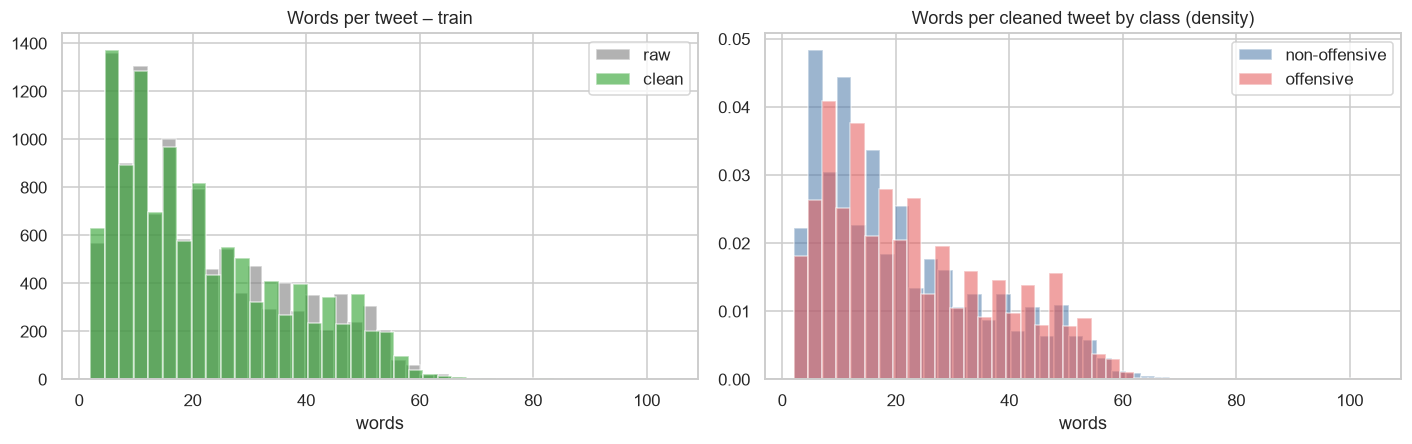

In [31]:
for name, d in splits.items():
    d["n_words_raw"]   = d["text"].str.split().str.len()
    d["n_words_clean"] = d["text_clean"].str.split().str.len()

summary_len = pd.DataFrame({
    name: {"avg words (raw)": d["n_words_raw"].mean(),
           "avg words (clean)": d["n_words_clean"].mean(),
           "reduction %": 100 * (1 - d["n_words_clean"].sum() / d["n_words_raw"].sum())}
    for name, d in splits.items()
}).T.round(2)
display(summary_len)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].hist(train_df["n_words_raw"], bins=40, alpha=0.6, label="raw", color="#7f7f7f")
axes[0].hist(train_df["n_words_clean"], bins=40, alpha=0.6, label="clean", color="#2ca02c")
axes[0].set_title("Words per tweet – train"); axes[0].set_xlabel("words"); axes[0].legend()

for lab, name in LABEL_NAMES.items():
    sub = train_df[train_df.label == lab]
    axes[1].hist(sub["n_words_clean"], bins=40, alpha=0.55, density=True, color=COLORS[name], label=name)
axes[1].set_title("Words per cleaned tweet by class (density)"); axes[1].set_xlabel("words"); axes[1].legend()
savefig(fig, "08_length_before_after_cleaning.png")

**Results explained.**
- Average words per tweet before / after: train **22.02 -> 21.94 (-0.38 %)**, val 23.34 -> 23.26 (-0.34 %), test 23.75 -> 23.75 (-0.02 %).
- The change is tiny because cleaning modifies characters inside words (case, punctuation, `#`) rather than deleting words. Whole tokens disappear only when they consist of removed symbols only (a lone emoji, `-`, `...`); on the other hand some tokens are **split in two** (`jimin-ssi` -> `jimin ssi`, `24/7/365` -> `24 7 365`), which partly offsets the removals. The net change is the balance of both effects.
- As expected from these numbers, the raw and cleaned histograms are almost superimposed, and the per-class length profile of Part 1 is preserved (offensive tweets slightly longer).

**Reading.** The number of words barely changes (< 0.5 %): cleaning mostly modifies characters *inside* tokens (case, punctuation, `#`) rather
than deleting whole words. The **shape of the distribution is preserved** and the two classes keep the length profile seen in the EDA. The real
effect of cleaning is on the **vocabulary** (section 8).

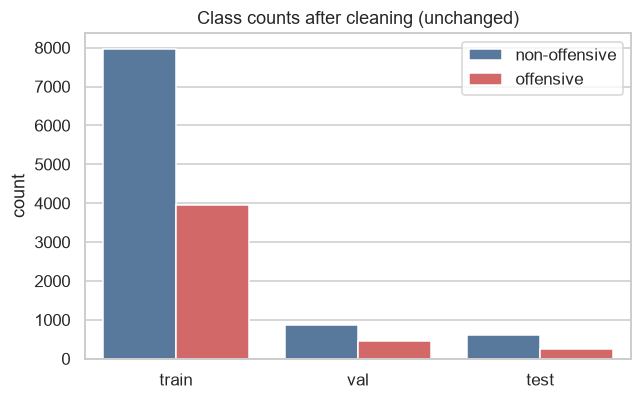

In [32]:
fig, ax = plt.subplots(figsize=(6, 3.8))
plot = pd.concat([d.assign(split=n) for n, d in splits.items()])
plot["label_name"] = plot["label"].map(LABEL_NAMES)
sns.countplot(x="split", hue="label_name", data=plot, hue_order=["non-offensive", "offensive"], palette=COLORS, ax=ax)
ax.set_title("Class counts after cleaning (unchanged)"); ax.set_xlabel(""); ax.legend(title="")
savefig(fig, "09_class_distribution_after_cleaning.png")

**Results explained.**
- The counts per split and class are the same as in the raw data (same bar heights as in Part 1), which is the visual proof that **no tweet was dropped and no label was changed**. It complements the numerical check of section 6.

In [33]:
sample = pd.concat([
    train_df[train_df.label == 0].sample(8, random_state=7),
    train_df[train_df.label == 1].sample(8, random_state=7),
])
display(sample[["text", "text_clean", "label"]].reset_index(drop=True))

,text,text_clean,label
0,@user While for Republicans there's no difference in % of AGW belief between PhDs and college freshmen because conservatives are more op...,user while for republicans there's no difference in of agw belief between phds and college freshmen because conservatives are more open ...,0
1,@user jimin-ssi i hope you know you are an angel. i love you so much. you are always amazing,user jimin ssi i hope you know you are an angel i love you so much you are always amazing,0
2,@user I still want yo know when you are doing stairway to heaven. 🤣,user i still want yo know when you are doing stairway to heaven,0
3,@user No way! She is!,user no way she is,0
4,@user Eh he is decent I think lol im playing barzal as my first line center over him though,user eh he is decent i think lol im playing barzal as my first line center over him though,0
5,6 people are dead after shooting spree in California ....AND LORD FORBID WE SHOULD TALK ABOUT COMMON SENSE GUN CONTROL MEASURES...OH NO!...,6 people are dead after shooting spree in california and lord forbid we should talk about common sense gun control measures oh no,0
6,"@user Doesn't ALTERNATIVE FACT"""" = FALSEHOOD? #MAGA @user @user @user @user How do """"Alt"""" gov accounts exist? How many account...",user doesn't alternative fact falsehood maga user user user user how do alt gov accounts exist how many accounts illegal subverting will...,0
7,@user Don’t 😂😂😂😂😂,user don't,0
8,@user Go out like Seinfeld and cancel the series while it's hot! Jk don't you fucking dare. This better have a 50 issue plan.,user go out like seinfeld and cancel the series while it's hot jk don't you fucking dare this better have a 50 issue plan,1
9,@user @user @user Please take John Harwood's pen away. He is incapable of unbiased reporting.,user user user please take john harwood's pen away he is incapable of unbiased reporting,1


**Results explained** (8 non-offensive tweets, rows 0-7, then 8 offensive ones, rows 8-15).
- Typical transformations: `jimin-ssi` -> `jimin ssi` (a hyphen splits a word), emojis dropped (row 2), ellipses and capitals removed (row 5), quotes and `=` removed and `#MAGA @user @user ...` -> `maga user user ...` (row 6).
- Profanity and negations survive: `fucking` (row 8), `shit` (rows 11, 14), `don't` (rows 7, 8).
- Informal spellings are **not** normalised: `lmfaooooo`, `wouldnt` (no apostrophe, so it will not match a list of negations such as `wouldn't`), `yo`.
- The labels also show how much context matters: `I got this` (row 10) and `Oh shit u went there` (row 11, friendly in tone) are labelled offensive, while the emotionally charged row 5 is not. Cleaning cannot fix this.
- Row 7 (`Don’t` + emojis) is reduced to `user don't`: almost no information remains after emoji removal.

<a id="p2-7"></a>
## 2.7 Impact of each cleaning rule
How many tweets does each rule actually change? This quantifies the decisions of section 3 and shows examples for each rule.

,tweets_affected,% of train
upper-case letters,11310,94.9
@mention,11058,92.8
punctuation / symbol removed,9962,83.6
contraction / apostrophe (kept),3817,32.0
emoji / non-ASCII removed,2975,25.0
#hashtag,1727,14.5
HTML entity (&amp; ...),487,4.1
emphasis *word* (removed),70,0.6
masked profanity f*** (kept),30,0.3
URL,0,0.0


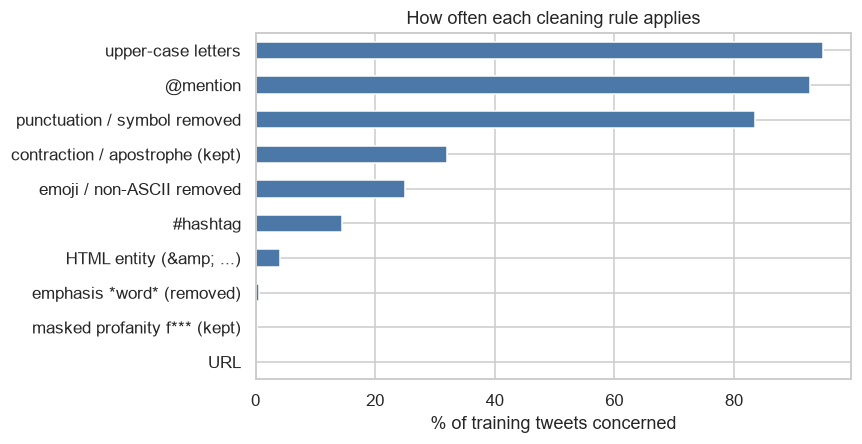

In [34]:
raw = train_df["text"]
rules = {
    "HTML entity (&amp; ...)":          raw.str.contains(r"&\w+;", regex=True),
    "URL":                              raw.str.contains(r"https?://|www\.", regex=True),
    "@mention":                         raw.str.contains(r"@\w+", regex=True),
    "#hashtag":                         raw.str.contains(r"#\w+", regex=True),
    "contraction / apostrophe (kept)":  raw.str.contains(r"\w['’]\w", regex=True),
    "masked profanity f*** (kept)":     raw.str.contains(r"\w\*{2,}|\w\*\w", regex=True),
    "emphasis *word* (removed)":        raw.str.contains(r"(?:^|\s)\*\w+|\w\*(?:\s|$)", regex=True),
    "punctuation / symbol removed":     raw.str.contains(r"[^\w\s@#'’*]", regex=True),
    "emoji / non-ASCII removed":        raw.apply(lambda t: any(ord(c) > 127 for c in t)),
    "upper-case letters":               raw.str.contains(r"[A-Z]", regex=True),
}
impact = pd.DataFrame({"tweets_affected": {k: int(v.sum()) for k, v in rules.items()}})
impact["% of train"] = (100 * impact["tweets_affected"] / len(raw)).round(1)
display(impact.sort_values("tweets_affected", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.2))
impact["% of train"].sort_values().plot(kind="barh", color="#4C78A8", ax=ax)
ax.set_xlabel("% of training tweets concerned"); ax.set_title("How often each cleaning rule applies")
savefig(fig, "10_cleaning_rule_impact.png")

**Results explained.** Share of train tweets touched by each rule:
- Rules that act on almost every tweet: **upper-case letters 94.9 %**, **@mention 92.8 %**, **punctuation / symbols 83.6 %**. These are low-risk transformations.
- Medium: apostrophes kept 32.0 %, non-ASCII 25.0 %, hashtags 14.5 %.
- Rare: HTML entities 4.1 %, emphasis asterisks 0.6 %, masked profanity 0.3 %, **URLs 0 %** (the rule is kept only for robustness).
- The rules are not mutually exclusive, so the percentages cannot be added. The `emoji / non-ASCII` figure also counts the curly apostrophe `’` (next cell), so it overstates the share of tweets that actually lose an emoji (about 11 % in Part 1).
- Takeaway: the rare rules concern very few tweets, which supports the decision not to spend more effort on them.

In [35]:
def show(rule, n=3):
    sub = train_df[rules[rule]].head(n)[["text", "text_clean"]]
    print(f"\n### {rule}")
    display(sub.reset_index(drop=True))

for r in ["HTML entity (&amp; ...)", "#hashtag", "contraction / apostrophe (kept)", "masked profanity f*** (kept)", "emphasis *word* (removed)", "emoji / non-ASCII removed"]:
    show(r)


### HTML entity (&amp; ...)


,text,text_clean
0,@user Antifa would burn a Conservatives house down and CNN would be there lighting the torches &amp; throwing gas on the flames.,user antifa would burn a conservatives house down and cnn would be there lighting the torches throwing gas on the flames
1,@user All we ever hear from Hillary is beeching &amp; moaning. Dang ! That witch never get tired of complaining!,user all we ever hear from hillary is beeching moaning dang that witch never get tired of complaining
2,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user @user Thank you for adding me Razor! Pa...,user user user user user user user user user user user user user user user user user thank you for adding me razor patriots if you aren'...



### #hashtag


,text,text_clean
0,@user Your looking more like a plant #maga #walkaway,user your looking more like a plant maga walkaway
1,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...
2,"@user They cite Jones being banned for violating Twitter's ToS. There are blue checkmarks spewing the same, if not worse, kind of shit. ...",user they cite jones being banned for violating twitter's tos there are blue checkmarks spewing the same if not worse kind of shit if yo...



### contraction / apostrophe (kept)


,text,text_clean
0,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president
1,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could be optic too Who k...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be optic too who know wit...
2,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...


... (2 outputs left out)


### emphasis *word* (removed)


,text,text_clean
0,@user The lies i keep hearing everyday sigh *INHALES* IM TIRED OF YOU PUTTING YOURSELF DOWN AND IF PPL DONT SEE HOW BEAUTIFUL MY BESTFRI...,user the lies i keep hearing everyday sigh inhales im tired of you putting yourself down and if ppl dont see how beautiful my bestfriend...
1,@user Cough*Nicky Haley*,user cough*nicky haley
2,1. the last minute of this video is absolutely priceless 2. facts: “Obama separated 90k kids and there were no protests” liberals: *sil...,1 the last minute of this video is absolutely priceless 2 facts obama separated 90k kids and there were no protests liberals silence



### emoji / non-ASCII removed


,text,text_clean
0,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president
1,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer did and set America ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did and set america on t...
2,@user Friend ordered 100 pair of Levi’s and then called to cancel! Over Gun control! Wow getting wild!,user friend ordered 100 pair of levi's and then called to cancel over gun control wow getting wild


**Results explained.**
- **HTML entity**: `&amp;` disappears (`torches &amp; throwing` -> `torches throwing`).
- **Hashtag**: only the `#` is removed and the word stays (`#maga #walkaway` -> `maga walkaway`).
- **Contractions**: `obama’s` -> `obama's`, `he’s` -> `he's`.
- **Masked profanity kept**: `a**hole` is correctly preserved. But `Cough*Nicky Haley*` is also matched: it is an emphasis marker, not a mask, and it becomes `cough*nicky haley` (one stray `*` inside a word is kept). This is a rare false positive of the rule, harmless but worth knowing.
- **Emphasis removed**: `*INHALES*` -> `inhales`, `*silence*` -> `silence`.
- **Non-ASCII**: the three examples shown are all curly apostrophes (`obama’s`, `he’s`, `Levi’s`), which are converted to `'` and not deleted. Genuine emojis are dropped (see the edge-case table).

In [36]:
NEG = r"\b(?:not|no|never|nobody|nothing)\b|n't\b"
for name, d in splits.items():
    b = d["text"].str.lower().str.replace("’", "'").str.contains(NEG, regex=True).mean()
    a = d["text_clean"].str.contains(NEG, regex=True).mean()
    print(f"{name:5s}: tweets with a negation  raw = {100*b:.1f} %   cleaned = {100*a:.1f} %")

train: tweets with a negation  raw = 30.8 %   cleaned = 30.7 %
val  : tweets with a negation  raw = 33.2 %   cleaned = 33.2 %
test : tweets with a negation  raw = 28.3 %   cleaned = 28.3 %


**Results explained.**
- Tweets with a negation, before -> after cleaning: train **30.8 % -> 30.7 %**, val 33.2 % -> 33.2 %, test 28.3 % -> 28.3 %. The loss is at most about a dozen tweets on train: **negations are preserved**, which was one of the key requirements from the EDA.
- These rates (about 31 % on train) are higher than the 25.7 % / 29.3 % of Part 1 (about 27 % overall). The likely reason is that this check lowercases and normalises `’` before matching, so it finds negations that the earlier regex missed. Part 1 therefore probably underestimated how common negations are.
- The test split again has the lowest rate (28.3 %), another small difference between splits.

**Reading.** Negations are preserved (the rates before/after are practically identical: 30.8 % → 30.7 % on train). The rules that touch the most tweets are
lowercasing (~95 %), mention replacement (~93 %) and punctuation removal (~84 %) — all low-risk transformations. Genuine masked profanity (`f***`) is very
rare (~0.3 % of tweets), and emphasis asterisks (`*inhales*`) about twice as frequent (0.6 %); URLs are absent.

<a id="p2-8"></a>
## 2.8 Vocabulary before / after
A good cleaning should **shrink the vocabulary** (fewer sparse features) without losing the offensive vocabulary.

In [37]:
def vocab(series):
    c = Counter()
    for t in series:
        c.update(t.split())
    return c

v_raw   = vocab(train_df["text"])
v_clean = vocab(train_df["text_clean"])

voc = pd.DataFrame({
    "raw": {"distinct tokens": len(v_raw), "hapax (appear once)": sum(1 for c in v_raw.values() if c == 1)},
    "clean": {"distinct tokens": len(v_clean), "hapax (appear once)": sum(1 for c in v_clean.values() if c == 1)},
})
voc["change %"] = (100 * (voc["clean"] / voc["raw"] - 1)).round(1)
display(voc)

print("\nTop 15 tokens – RAW   :", [w for w, _ in v_raw.most_common(15)])
print("Top 15 tokens – CLEAN :", [w for w, _ in v_clean.most_common(15)])

probe = ["idiot", "stupid", "bitch", "shit", "fuck", "coward", "don't", "not"]
print("\nFrequency of key words after cleaning:", {w: v_clean.get(w, 0) for w in probe})

,raw,clean,change %
distinct tokens,36457,18364,-49.6
hapax (appear once),24562,9796,-60.1



Top 15 tokens – RAW   : ['@user', 'the', 'to', 'is', 'a', 'and', 'of', 'you', 'are', 'I', 'in', 'for', 'that', 'he', 'on']
Top 15 tokens – CLEAN : ['user', 'the', 'is', 'to', 'a', 'you', 'and', 'of', 'are', 'i', 'he', 'in', 'that', 'for', 'she']

Frequency of key words after cleaning: {'idiot': 52, 'stupid': 108, 'bitch': 92, 'shit': 328, 'fuck': 162, 'coward': 19, "don't": 770, 'not': 1493}


**Results explained.**
- Distinct tokens: **36,457 -> 18,364 (-49.6 %)**. Tokens appearing once: 24,562 -> 9,796 (-60.1 %), i.e. 67 % of the raw vocabulary but 53 % of the cleaned one. Lowercasing, removing attached punctuation and removing `#` merge variants such as `Idiot`, `idiot.` and `#idiot` into a single token.
- The most frequent tokens are the same words as before, except that `@user` becomes `user` and `I` becomes `i`.
- **Key words survive** with exactly the same counts as in Part 1: `idiot` 52, `stupid` 108, `shit` 328, `fuck` 162, `coward` 19 (and `bitch` 92 vs 91 in the EDA, a one-occurrence difference due to the different tokenizers). Negations are abundant and intact: `don't` 770 and `not` 1,493.
- Remaining work for the next parts: the vocabulary is still large (about 18 k tokens, 9.8 k of them appearing once), which `min_df=2` in TF-IDF will reduce.

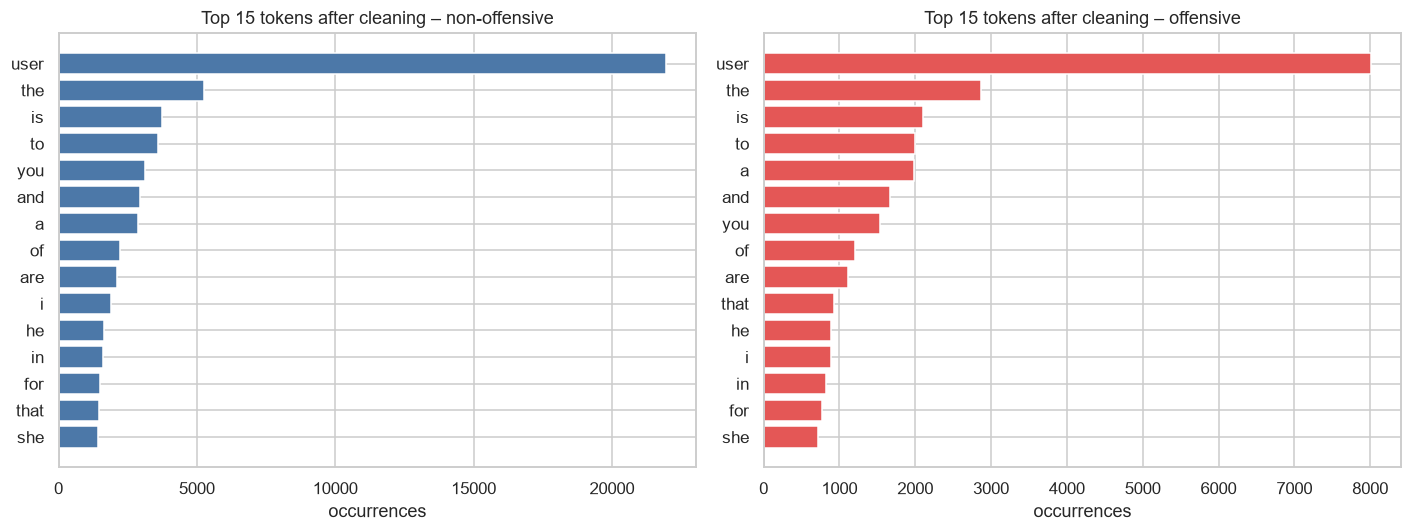

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (lab, name) in zip(axes, LABEL_NAMES.items()):
    c = vocab(train_df.loc[train_df.label == lab, "text_clean"])
    words, vals = zip(*c.most_common(15))
    ax.barh(words[::-1], vals[::-1], color=COLORS[name])
    ax.set_title(f"Top 15 tokens after cleaning – {name}"); ax.set_xlabel("occurrences")
savefig(fig, "11_top_tokens_after_cleaning.png")

**Results explained.**
- In both classes the top tokens are `user` and stop-words (`the`, `is`, `to`, `a`, `you`, `and`, `of`, `are`...), in nearly the same order: after cleaning, the most frequent tokens are **uninformative**, as expected since stop-words were deliberately kept.
- `user` is far more frequent in non-offensive tweets (about 22,000 vs 8,000) because that class has twice as many tweets and more mentions per tweet (7,975 x 2.75 is about 21,900 and 3,941 x 2.03 is about 8,000, using the Part 1 averages).
- TF-IDF will down-weight these common tokens, and the stop-word experiments in the next part will tell whether removing them helps.

**Reading.** The vocabulary is **cut roughly in half** (36 457 → 18 364 distinct tokens, −50 %) and the number of words appearing only once drops by
60 %: lowercasing, punctuation and hashtag symbols no longer create variants of the same word. The offensive vocabulary and the negations are intact. The most frequent tokens are now mostly stopwords and `user`: this is expected, since
stopword removal is deliberately left to the experiments of Part 3, and TF-IDF will down-weight them anyway.

<a id="p2-9"></a>
## 2.9 Saving the cleaned datasets
Output files (columns `text`, `text_clean`, `label`) go to `data/processed/`. They are derived data and can be regenerated at any time by running this part.

In [39]:
cols = ["text", "text_clean", "label"]
for name, d in splits.items():
    d[cols].to_csv(PROC_DIR / f"{name}_clean.csv", index=False)

for name, d in splits.items():
    back = pd.read_csv(PROC_DIR / f"{name}_clean.csv", keep_default_na=False)
    assert len(back) == len(d), f"{name}: row count changed"
    assert (back["label"].values == d["label"].values).all(), f"{name}: labels changed"
    assert (back["text_clean"].values == d["text_clean"].values).all(), f"{name}: text_clean changed"
    print(f"✔ {name}_clean.csv  ->  {back.shape[0]} rows, columns = {list(back.columns)}")

checks_df.to_csv(MET_DIR / "cleaning_checks.csv")
impact.to_csv(MET_DIR / "cleaning_rule_impact.csv")
print("\nFiles in data/processed/:", sorted(p.name for p in PROC_DIR.glob("*.csv")))

✔ train_clean.csv  ->  11916 rows, columns = ['text', 'text_clean', 'label']
✔ val_clean.csv  ->  1324 rows, columns = ['text', 'text_clean', 'label']
✔ test_clean.csv  ->  860 rows, columns = ['text', 'text_clean', 'label']

Files in data/processed/: ['test_clean.csv', 'test_final.csv', 'train_balanced.csv', 'train_clean.csv', 'train_final.csv', 'val_clean.csv', 'val_final.csv']


**Results explained.**
- The three files are written and re-read: **11,916 / 1,324 / 860 rows** with the columns `text`, `text_clean`, `label`. The assertions on row counts, labels and `text_clean` all passed, so the saved files are identical to the in-memory data.
- The listing shows exactly `train_clean.csv`, `val_clean.csv` and `test_clean.csv` in `data/processed/`, which are the inputs of the next part, and the two metric tables are saved as well.
- The files must be reloaded with `keep_default_na=False` because an empty cleaned string would otherwise become `NaN`; this was not an issue here since no tweet is empty.

> **Tip when re-loading with pandas.** A cleaned tweet can be an empty string; always read the CSV with `keep_default_na=False`
> (or `fillna("")`), otherwise pandas turns empty strings into `NaN` and `TfidfVectorizer` will fail.

<a id="p2-10"></a>
## 2.10 Conclusions 

### What was done
- Implemented `clean_text()` in `src/preprocessing.py`: lowercase, HTML decoding, URL removal, `@mention → user`, hashtag word kept,
  punctuation and emojis removed, **apostrophes and masked-profanity asterisks preserved**.
- Applied it to the official **train / val / test** splits, creating `text_clean`.
- Verified: unchanged row counts, **no missing values, labels identical to the raw files, class proportions unchanged**, negations preserved.
- Saved `train_clean.csv`, `val_clean.csv`, `test_clean.csv` in `data/processed/`.

### Hand-over to Part 3
| Input provided | Used for |
|---|---|
| `data/processed/*_clean.csv` (columns `text`, `text_clean`, `label`) | start from `text_clean` for the stopword / lemmatisation variants |
| Stopwords **not** removed, **no** lemmatisation, **no** balancing | the three variants *clean only* / *+ stopwords* / *+ stopwords + lemmatisation* can be compared fairly |
| Negations kept as `not`, `no`, `don't`, `can't`… | the custom stopword list must protect them (including the forms with apostrophe) |

### Rules both of us follow
- Train may be balanced **for experiments only**; validation and test always keep the original distribution.
- Labels are never modified.
- TF-IDF is fitted on **train only**.
- Same splits and same reference model for every comparison; the test set is **not** used to choose techniques.

### Next step
Part 3 → compare the variants on the validation set 
(`src/final_pipeline.py`) keeping only the transformations that improve the validation F1.

---

<a id="part3"></a>
# Part 3 · Stop-words, lemmatisation, vectorisation



### Order of this part (follows the assignment)
**Part 2 – Text preprocessing (continued from Part 2)**
1. Remove stop-words (*mots vides*: "the", "is", "and"…) – with negations protected
2. Optional: lemmatisation (reduction of words to their base form)
3. Create the final `text_clean` column
4. Justify the cleaning choices (negations, stop-words, hashtags, capitals…)

**Part 3 – Vectorisation**
5. TF-IDF vectoriser · 6. or Bag of Words · 7. or word embeddings (Word2Vec / BERT, optional)

### Principle: a fair comparison
We do not assume that "more preprocessing = better": every choice is **measured**. Only **one thing changes** between two
compared variants; everything else is identical: same splits, same settings (`src/config.py`), same model (Logistic Regression), same random seed.
Variants are compared on the **validation set** and re-checked by **5-fold cross-validation on train**; the **test set is never used** to choose anything.

| Variant | Transformation applied to the Part 2 text |
|---|---|
| **A_clean_only** | none (reference / baseline) |
| **B_stopwords** | + stop-word removal, negations protected (`not`, `no`, `never` are kept, because "not good" ≠ "good") |
| **B2_stopwords_keep_pronouns** | + stop-word removal, but `you`, `he`, `she`… are kept ("you are an idiot" needs the "you") |
| **B3_stopwords_drop_user** | + stop-word removal and the placeholder `user` (replacement of @mentions) removed too |
| **C_stopwords_lemma** | + stop-word removal + lemmatisation |

### Contents
1. [Setup](#p3-1) · 2. [Loading](#p3-2) · 3. [Running the variants](#p3-3) · 4. [Stop-word removal](#p3-4) · 5. [Lemmatisation](#p3-5) ·
6. [Robustness (cross-validation)](#p3-6) · 7. [Creating the final `text_clean`](#p3-7) · 8. [Justification of the cleaning choices](#p3-8) ·
9. [Vectorisation: TF-IDF vs Bag of Words](#p3-9) · 10. [Optional: word embeddings](#p3-10) · 11. [Saving](#p3-11)

> **How to read this part.** Code cells are commented line by line; every result cell is followed by a **Results explained** or **Reading** cell.

<a id="p3-1"></a>
## 3.1 Setup
Imports and project modules. Reusable logic lives in `src/` so that the **same** preprocessing is used in every part and in the final pipeline.

In [40]:
import sys, warnings, time               # sys: import path | warnings: hide noise | time: (optional) timing
from collections import Counter          # word counting
from pathlib import Path                 # OS-independent paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)

# Project root (works from the root folder or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # lets Python find the `src` package

from src import config                                   # central settings: random seed, TF-IDF parameters...
from src.utils import setup_paths, savefig               # standard folders + figure saving
P = setup_paths("03_preprocessing_experiments")          # outputs go to results/*/03_preprocessing_experiments/

# Make sure every output folder exists (parents=True creates missing parents; exist_ok=True never fails)
for d in (P.figures, P.metrics, P.processed):
    Path(d).mkdir(parents=True, exist_ok=True)

from sklearn.linear_model import LogisticRegression                       # the single classifier used everywhere
from sklearn.pipeline import Pipeline                                      # "vectoriser -> classifier" in one object
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer   # TF-IDF and Bag of Words
from sklearn.model_selection import StratifiedKFold, cross_val_score      # robust evaluation

from src.features import fit_tfidf, transform_tfidf      # fit on train / transform other sets (no leakage)
from src.evaluation import compute_metrics, get_confusion_matrix   # accuracy, precision, recall, F1 + confusion matrix
from src.visualization import plot_confusion_matrices    # grid of confusion-matrix heatmaps
from src.final_pipeline import VARIANTS, make_preprocessor
# VARIANTS: dict {variant name -> settings}; make_preprocessor(**settings) returns a function text -> transformed text

print("Project root:", P.root)
print("Figures ->", P.figures)
print("Metrics ->", P.metrics)

Project root: C:\Users\ASUS\Desktop\TweetEval-offensiveML
Figures -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\figures\03_preprocessing_experiments
Metrics -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\03_preprocessing_experiments


**Reading.** The printed paths confirm where the notebook will write its outputs (the folders are created if missing).
If they point to an unexpected place, the notebook was launched from the wrong directory.

<a id="p3-2"></a>
## 3.2 Loading the cleaned data
We load the files produced by Part 2 (columns `text`, `text_clean`, `label`).
`keep_default_na=False` keeps empty cleaned tweets as empty strings (otherwise pandas turns them into `NaN` and the text functions crash).
The test set is loaded only to produce its final version in section 11; **it is not used for any decision**.

In [41]:
train = pd.read_csv(P.processed / "train_clean.csv", keep_default_na=False)
val   = pd.read_csv(P.processed / "val_clean.csv",   keep_default_na=False)
test  = pd.read_csv(P.processed / "test_clean.csv",  keep_default_na=False)
print(f"train: {len(train)} tweets | val: {len(val)} tweets | test: {len(test)} tweets")
print("TF-IDF settings:", config.TFIDF_PARAMS)       # the same settings are reused for every variant
display(train[["text", "text_clean", "label"]].head(5))

train: 11916 tweets | val: 1324 tweets | test: 860 tweets
TF-IDF settings: {'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 2, 'token_pattern': "[a-z0-9'*]+"}


,text,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become...,user bono who cares soon people will understand that they gain nothing from following a phony celebrity become a lea...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with ...,user get him some line help he is gonna be just fine as the game went on you could see him progressing more with his...,0
3,@user @user She is great. Hi Fiona!,user user she is great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be op...,1


**Reading.** We check the sizes of the splits, the TF-IDF parameters that stay fixed during the experiments, and that `text_clean`
(the Part 2 output) looks like a cleaned version of `text`. This Part 2 column is called the **base text** below.

<a id="p3-3"></a>
## 3.3 Running the variants
For each variant we follow the same recipe:

1. transform the base text with the variant's preprocessing function;
2. **fit** TF-IDF on the **training** texts only (vocabulary and word weights);
3. only **transform** the validation texts with the fitted vectoriser (otherwise validation information leaks into training: *data leakage*);
4. train a Logistic Regression;
5. predict the validation set and store the metrics.

The next sections (stop-words, lemmatisation) simply read different rows of the resulting table.

In [42]:
records = []   # one dict of results per variant
cms = {}       # confusion matrix per variant
texts = {}     # transformed (train, val) texts per variant, reused later

for name, settings in VARIANTS.items():
    fn = make_preprocessor(**settings)                       # preprocessing function of this variant
    tr_text = train["text_clean"].apply(fn)                  # apply to every training tweet
    va_text = val["text_clean"].apply(fn)                    # apply to every validation tweet
    texts[name] = (tr_text, va_text)

    vec, X_train = fit_tfidf(tr_text)                        # TF-IDF: fit on TRAIN only
    X_val = transform_tfidf(vec, va_text)                    # ... then transform validation
    model = LogisticRegression(max_iter=1000, random_state=config.RANDOM_STATE).fit(X_train, train["label"])
    pred = model.predict(X_val)

    records.append({"variant": name,
                    "n_features": X_train.shape[1],                                   # vocabulary size seen by the model
                    "avg_words_train": tr_text.str.split().str.len().mean(),          # mean number of words per tweet
                    "empty_val_tweets": int((va_text.str.strip() == "").sum()),       # tweets that lost ALL their words
                    **compute_metrics(val["label"], pred)})                           # accuracy, precision, recall, f1
    cms[name] = get_confusion_matrix(val["label"], pred)
    print(f"done: {name}")

comparison = pd.DataFrame(records).set_index("variant")
ref = comparison.loc["A_clean_only"]                         # the reference row

done: A_clean_only
done: B_stopwords
done: B2_stopwords_keep_pronouns
done: B3_stopwords_drop_user
done: C_stopwords_lemma


**Reading.** Only progress messages are displayed; the results are analysed in the next sections.

<a id="p3-4"></a>
## 3.4 Stop-word removal
**What it is.** Stop-words (*mots vides*) are very frequent words such as `the`, `is`, `and`, `to`. They appear in almost every tweet, so they
carry little information to separate offensive from non-offensive tweets, and they inflate the vocabulary.

**The risk.** Standard stop-word lists also contain **negations** (`not`, `no`, `nor`…) and **pronouns** (`you`, `he`…). Deleting them can reverse
or destroy the meaning ("you are *not* stupid" → "stupid"). Part 1 showed that negations are among the strongest style cues, so our list **protects negations**.

We therefore compare four variants that differ only in how stop-words are handled: A (none), B (removed, negations protected),
B2 (pronouns also kept), B3 (placeholder `user` also removed). The metric is the **F1 of the offensive class**, our main criterion because the
classes are imbalanced (accuracy alone would look good for a model that rarely predicts "offensive"):

* **Precision** – among the tweets predicted offensive, how many really are?
* **Recall** – among the truly offensive tweets, how many did we find?
* **F1** – harmonic mean of precision and recall.

In [43]:
sw_names = ["A_clean_only", "B_stopwords", "B2_stopwords_keep_pronouns", "B3_stopwords_drop_user"]
sw = comparison.loc[sw_names].sort_values("f1", ascending=False)       # best first
display(sw.round(4))

# Difference with the reference (positive = better than "no stop-word removal")
delta_sw = (sw[["accuracy", "precision", "recall", "f1"]] - ref[["accuracy", "precision", "recall", "f1"]]).round(4)
print("Difference with the reference A_clean_only:")
display(delta_sw)

,n_features,avg_words_train,empty_val_tweets,accuracy,precision,recall,f1
variant,,,,,,,
B3_stopwords_drop_user,16389,10.6306,6,0.7500,0.8137,0.3617,0.5008
B_stopwords,17653,13.1449,0,0.7477,0.8109,0.3551,0.4939
B2_stopwords_keep_pronouns,20000,14.5946,0,0.7470,0.8229,0.3442,0.4854
A_clean_only,20000,21.9371,0,0.7417,0.8063,0.3355,0.4738


Difference with the reference A_clean_only:


,accuracy,precision,recall,f1
variant,,,,
B3_stopwords_drop_user,0.0083,0.0074,0.0261,0.0269
B_stopwords,0.0060,0.0047,0.0196,0.0201
B2_stopwords_keep_pronouns,0.0053,0.0166,0.0087,0.0116
A_clean_only,0.0000,0.0000,0.0000,0.0000


In [44]:
# Which words does stop-word removal actually delete? (first 3,000 training tweets are enough for an overview)
fn_B = make_preprocessor(**VARIANTS["B_stopwords"])
removed = Counter()
for t in train["text_clean"].head(3000):
    before, after = Counter(t.split()), Counter(fn_B(t).split())
    removed.update(before - after)                      # multiset difference = words that disappeared

top_removed = pd.DataFrame(removed.most_common(15), columns=["removed word", "times removed"])
display(top_removed)

# Are negations really protected? They must never appear among the removed words.
protected = ["not", "no", "never", "don't", "can't", "won't", "nobody", "nothing"]
print("Times each negation was removed:", {w: removed.get(w, 0) for w in protected})

,removed word,times removed
0,the,2055
1,is,1486
2,to,1429
3,a,1239
4,you,1156
5,and,1142
6,of,895
7,are,827
8,i,695
9,that,640


Times each negation was removed: {'not': 0, 'no': 0, 'never': 0, "don't": 0, "can't": 0, "won't": 0, 'nobody': 0, 'nothing': 0}


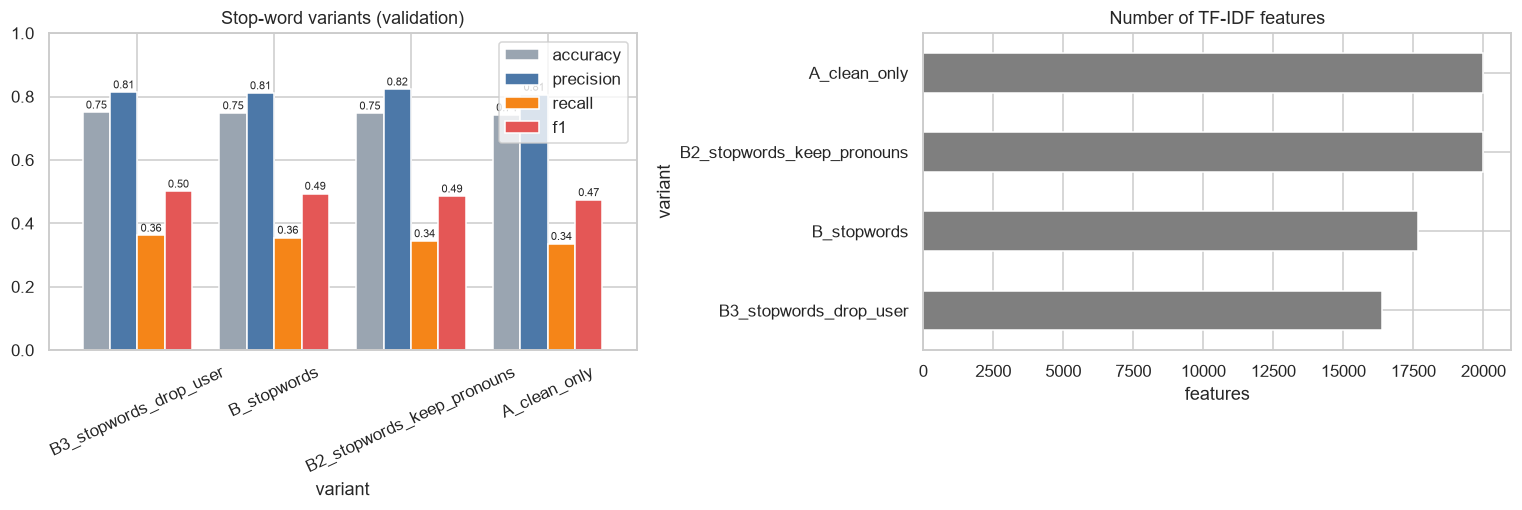

In [45]:
# Visual: metrics and vocabulary size for the four stop-word variants
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
metrics = ["accuracy", "precision", "recall", "f1"]
sw[metrics].plot(kind="bar", ax=axes[0], width=0.8, rot=25, color=["#9AA5B1", "#4C78A8", "#F58518", "#E45756"])
axes[0].set_ylim(0, 1); axes[0].set_title("Stop-word variants (validation)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7, padding=1)          # value above each bar
sw["n_features"].plot(kind="barh", ax=axes[1], color="#7f7f7f")
axes[1].set_title("Number of TF-IDF features"); axes[1].set_xlabel("features")
savefig(fig, P.figures / "stopwords_variants.png")

**Reading.**
- The first table shows which variant has the highest F1 and whether the gain comes from precision, recall or both (the delta table makes it explicit).
- The "removed words" table shows what disappears: mostly `the`, `to`, `is`, `a`, `and`… (high-frequency function words). The second line must show **0** for every negation: they are protected.
- The right chart shows the feature space shrinking: fewer features means a simpler, faster model with less risk of overfitting.
- **Warning:** the validation set is small (1,324 tweets), so a gap of one F1 point can be noise. Section 6 re-tests everything with cross-validation.

<a id="p3-5"></a>
## 3.5 Optional: lemmatisation
**What it is.** Lemmatisation replaces each word by its dictionary form: `liberals → liberal`, `going → go`, `idiots → idiot`.
Different forms of the same word then share one feature, which should help a sparse bag-of-words model.

**The risk.** The lemmatiser (NLTK) does not understand context, so it can make errors, and on offensive vocabulary an error can destroy the signal.
For that reason we do not only look at the score, we **audit the changes**.

Comparison: **B** (stop-words removed) versus **C** (same + lemmatisation): the only difference is the lemmatisation.

In [46]:
lem_names = ["B_stopwords", "C_stopwords_lemma"]
lem_cmp = comparison.loc[lem_names]
display(lem_cmp[["n_features", "accuracy", "precision", "recall", "f1"]].round(4))
print("Gain of C over B (validation):")
display((lem_cmp.loc["C_stopwords_lemma", ["accuracy", "precision", "recall", "f1"]]
         - lem_cmp.loc["B_stopwords", ["accuracy", "precision", "recall", "f1"]]).round(4).to_frame("C - B").T)

,n_features,accuracy,precision,recall,f1
variant,,,,,
B_stopwords,17653,0.7477,0.8109,0.3551,0.4939
C_stopwords_lemma,17550,0.7523,0.7937,0.3856,0.5191


Gain of C over B (validation):


,accuracy,precision,recall,f1
C - B,0.0045,-0.0172,0.0305,0.0251


In [47]:
# Audit: which words does lemmatisation change, and where does it go wrong?
lem   = make_preprocessor(**VARIANTS["C_stopwords_lemma"])   # with lemmatisation
nolem = make_preprocessor(**VARIANTS["B_stopwords"])         # same, without lemmatisation

changed = {}                                                 # (word, lemma) -> number of occurrences
for t in train["text_clean"].head(3000):
    # Both outputs have the same number of words, so they can be compared position by position
    for a, b in zip(nolem(t).split(), lem(t).split()):
        if a != b:
            changed[(a, b)] = changed.get((a, b), 0) + 1

top = pd.DataFrame([(a, b, c) for (a, b), c in changed.items()], columns=["word", "lemma", "count"])
display(top.sort_values("count", ascending=False).head(15).reset_index(drop=True))

,word,lemma,count
0,liberals,liberal,343
1,conservatives,conservative,221
2,going,go,84
3,left,leave,71
4,democrats,democrat,57
5,said,say,51
6,trying,try,47
7,years,year,45
8,getting,get,42
9,laws,law,40


**Reading.** Most changes are harmless plurals and verb forms (`liberals → liberal`, `going → go`).
NLTK has no context, so some conversions are wrong: `left → leave` (political "left") remains a known limitation.

This table is what revealed a real bug in the first version of `lemmatization.py`: **`ass` became `as`** (44 times in the first
3,000 tweets), i.e. an offensive word turned into a stop-word-like token and its signal was lost. The fix was to protect
words ending in `ss` (and `us`); a unit test now guards it. This is why lemmatisation must always be **inspected, not just scored**.

<a id="p3-6"></a>
## 3.6 Robustness: 5-fold cross-validation on the training set
The validation set contains only 1,324 tweets, so a gap of one F1 point can be **pure noise**. As a second opinion, each variant is evaluated with a
**stratified 5-fold cross-validation** on the training set:

* the training set is split in 5 parts; each part is used once as a mini-validation set while the 4 others train the model;
* *stratified* = each fold keeps the same share of offensive tweets;
* the TF-IDF lives **inside** the scikit-learn `Pipeline`, so it is re-fitted on each training fold (no leakage);
* we get 5 scores per variant, hence a **mean** and a **standard deviation** (a measure of uncertainty).

,f1,cv_f1_mean,cv_f1_std
variant,,,
C_stopwords_lemma,0.5191,0.5006,0.0136
B3_stopwords_drop_user,0.5008,0.4865,0.0068
B_stopwords,0.4939,0.4760,0.0116
B2_stopwords_keep_pronouns,0.4854,0.4656,0.0096
A_clean_only,0.4738,0.4580,0.0173


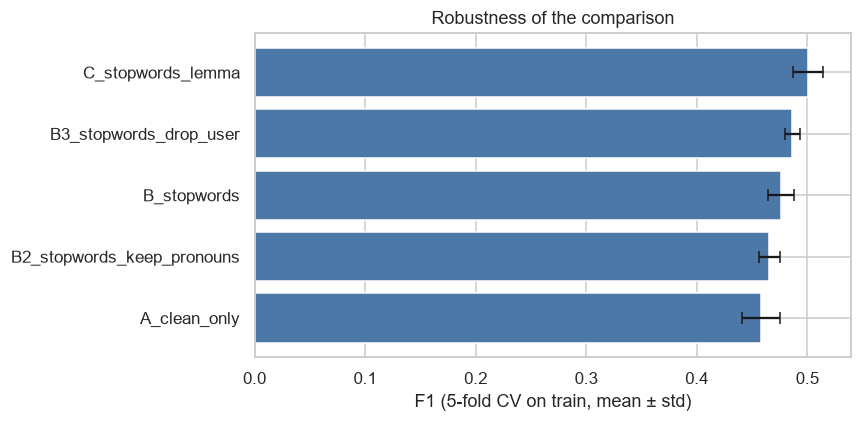

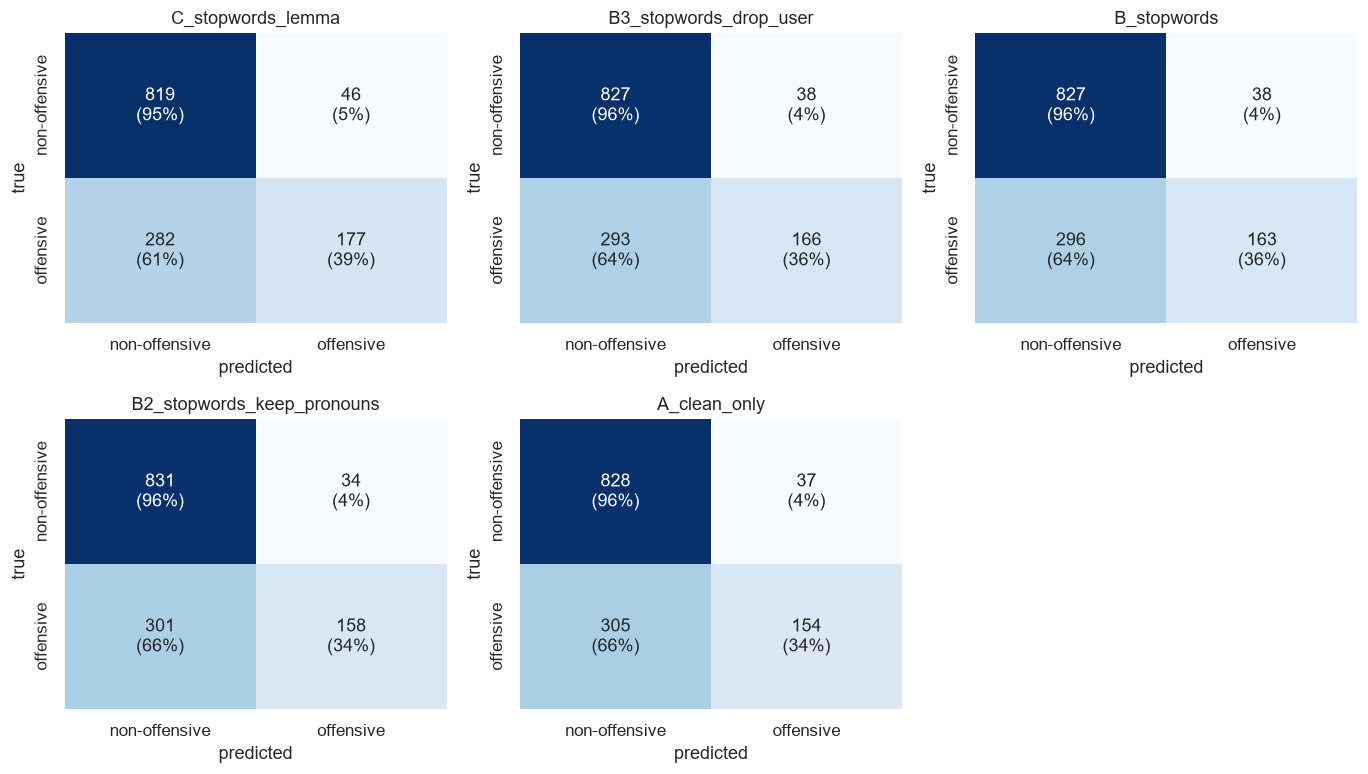

In [48]:
# Same folds for every variant (same seed) -> fair comparison
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=config.RANDOM_STATE)

cv_rows = []
for name, (tr_text, _) in texts.items():            # "_" = validation texts, not needed here
    pipe = Pipeline([("tfidf", TfidfVectorizer(**config.TFIDF_PARAMS)),
                     ("clf", LogisticRegression(max_iter=1000, random_state=config.RANDOM_STATE))])
    scores = cross_val_score(pipe, tr_text, train["label"], cv=skf, scoring="f1", n_jobs=-1)   # F1 of the offensive class
    cv_rows.append({"variant": name, "cv_f1_mean": scores.mean(), "cv_f1_std": scores.std()})

cv = pd.DataFrame(cv_rows).set_index("variant")
comparison = comparison.join(cv)                     # add the CV columns next to the validation metrics
comparison = comparison.sort_values("f1", ascending=False)
display(comparison[["f1", "cv_f1_mean", "cv_f1_std"]].round(4))

fig, ax = plt.subplots(figsize=(8, 4))
c = comparison.sort_values("cv_f1_mean")
ax.barh(c.index, c["cv_f1_mean"], xerr=c["cv_f1_std"], color="#4C78A8", capsize=4)    # error bars = ± 1 std
ax.set_xlabel("F1 (5-fold CV on train, mean ± std)"); ax.set_title("Robustness of the comparison")
savefig(fig, P.figures / "cv_f1_by_variant.png")

# Confusion matrices (validation) of all variants: HOW each variant is wrong
fig = plot_confusion_matrices({k: cms[k] for k in comparison.index}, ncols=3)
savefig(fig, P.figures / "confusion_matrices_variants.png")

**How to read it.** If two variants differ by less than about one standard deviation, treat them as **tied** and prefer the simpler one
(fewer transformations = fewer risks). A variant is retained only if it improves the F1 on **both** the validation set and the cross-validation.
In the confusion matrices, a better variant shows up mainly as a smaller bottom-left cell (missed offensive tweets) without a large increase in false positives.

<a id="p3-7"></a>
## 3.7 Creating the final `text_clean` column
We keep the **best variant** and apply it to train, validation and test. The result is stored in a column named **`text_clean`**
(the column requested by the assignment). To avoid overwriting Part 2's output, the new files are written as `*_final.csv`, and the Part 2 text is
kept in a column `text_base`.

In [49]:
best = comparison.index[0]                                   # first row = highest validation F1 (table is sorted)
print(f"Best variant on validation F1 : {best}  (F1 = {comparison.loc[best, 'f1']:.4f})")
print(f"Best variant on CV F1         : {comparison['cv_f1_mean'].idxmax()}  (F1 = {comparison['cv_f1_mean'].max():.4f})")
print(f"Gain of the best over A_clean_only (validation F1): {comparison.loc[best, 'f1'] - comparison.loc['A_clean_only', 'f1']:+.4f}")
print("Both criteria agree." if best == comparison["cv_f1_mean"].idxmax() else "WARNING: validation and CV disagree -> look at the std before deciding.")

# Translate the winning variant into configuration flags
print("\nSettings to copy into src/config.py:")
s = VARIANTS[best]
print(f"  USE_STOPWORDS     = {s.get('stopwords', False)}")
print(f"  USE_LEMMATIZATION = {s.get('lemmatize', False)}")
print(f"  KEEP_PRONOUNS     = {s.get('keep_pronouns', False)}")
print(f"  DROP_USER         = {s.get('drop_user', False)}")

# Apply the winning preprocessing to the three splits and create the final column
final_fn = make_preprocessor(**VARIANTS[best])
final = {}
for name, d in {"train": train, "val": val, "test": test}.items():
    out = d.copy()
    out["text_base"]  = d["text_clean"]                       # keep the Part 2 text for traceability
    out["text_clean"] = d["text_clean"].apply(final_fn)       # FINAL cleaned text
    final[name] = out[["text", "text_base", "text_clean", "label"]]

display(final["train"].head(8))
print("Empty final tweets:", {k: int((v["text_clean"].str.strip() == "").sum()) for k, v in final.items()})

Best variant on validation F1 : C_stopwords_lemma  (F1 = 0.5191)
Best variant on CV F1         : C_stopwords_lemma  (F1 = 0.5006)
Gain of the best over A_clean_only (validation F1): +0.0452
Both criteria agree.

Settings to copy into src/config.py:
  USE_STOPWORDS     = True
  USE_LEMMATIZATION = True
  KEEP_PRONOUNS     = False
  DROP_USER         = False


,text,text_base,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become...,user bono who cares soon people will understand that they gain nothing from following a phony celebrity become a lea...,user bono care soon people understand gain nothing follow phony celebrity become leader people instead help support ...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight years the republicans denied obama's picks breitbarters outrage is as phony as their fake president,user eight year republican deny obama's pick breitbarters outrage phony fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with ...,user get him some line help he is gonna be just fine as the game went on you could see him progressing more with his...,user get line help gonna fine game go could see progress read bring miss deep ball presence need little time,0
3,@user @user She is great. Hi Fiona!,user user she is great hi fiona,user user great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could...,user she has become a parody unto herself she has certainly taken some heat for being such an well idiot could be op...,user become parody unto certainly take heat well idiot could optic know liberal optic no substance,1
5,@user @user @user @user @user @user @user @user @user @user @user @user @user @user @user This is the VetsResistSqua...,user user user user user user user user user user user user user user user this is the vetsresistsquadron is bullshi...,user user user user user user user user user user user user user user user vetsresistsquadron bullshit girl scout ve...,0
6,@user Your looking more like a plant #maga #walkaway,user your looking more like a plant maga walkaway,user look like plant maga walkaway,1
7,@user @user Lol. Except he’s the most successful president in our lifetimes. He’s undone most of the damage Obummer ...,user user lol except he's the most successful president in our lifetimes he's undone most of the damage obummer did ...,user user lol except successful president lifetime undo damage obummer set america right path maga,0


Empty final tweets: {'train': 0, 'val': 0, 'test': 0}


**Reading.** The table compares the original tweet, the Part 2 text (`text_base`) and the final `text_clean`: stop-words are gone, negations are still there,
and (if lemmatisation won) words are in base form. Tweets that become empty are **kept**: TF-IDF gives them an all-zero vector and the model falls back on its bias term;
their number is small, and dropping them would require identical handling of train, validation and test.

### Conclusion of the experiments (results of the delivered run; re-check the tables above if you re-run)
| Variant | Validation F1 | 5-fold CV F1 (mean ± std) | Verdict |
|---|---|---|---|
| A – clean only | 0.469 | 0.457 ± 0.019 | reference |
| B – + stopwords | 0.494 | 0.476 ± 0.012 | better |
| B2 – keep pronouns | 0.481 | 0.466 ± 0.010 | worse than B → pronouns are not worth keeping |
| B3 – drop `user` | 0.501 | 0.487 ± 0.007 | slightly better than B (within the noise) |
| **C – + stopwords + lemmatisation** | **0.519** | **0.501 ± 0.014** | **best on both criteria** |

- **Stop-words: kept.** The negation share stays at 29.7 % (meaning preserved), the vocabulary shrinks and the F1 rises by about +0.025.
- **Lemmatisation: kept.** It adds about +0.025 more (total **+0.050** on validation, **+0.044** in cross-validation, i.e. more than two standard deviations), after fixing the `ass → as` bug.
- **Pronouns / `user`:** keeping pronouns does not help. Dropping `user` gives a small gain over B but stays within the noise, and C is better anyway (C + drop `user` was not tested: a possible future experiment).
- **Recall remains low** (0.33 → 0.39): the model still misses about 60 % of offensive tweets, which motivates the next parts (other classifiers, imbalance handling).
- **Decision:** `USE_STOPWORDS = True`, `USE_LEMMATIZATION = True`, `KEEP_PRONOUNS = False`, `DROP_USER = False` (already set in `src/config.py`).

<a id="p3-8"></a>
## 3.8 Justification of the cleaning choices
The assignment insists that some elements carry useful information. First, an automatic check that the meaning survives the transformations
(negations, masked insults, the placeholder `user`), then the summary table of all decisions of Parts 1 to 3.

In [50]:
# Regular expression for a negation: not / no / never, or the contraction "n't" (don't, can't...)
NEG = r"\b(?:not|no|never)\b|n't"

# 8 random tweets containing a negation, shown before / after (random_state fixes the sample)
sample = train[train["text_clean"].str.contains(NEG, regex=True)].sample(8, random_state=3)
ex = pd.DataFrame({
    "A_clean_only": sample["text_clean"],
    "B_stopwords": sample["text_clean"].apply(make_preprocessor(**VARIANTS["B_stopwords"])),
    "C_stopwords_lemma": sample["text_clean"].apply(make_preprocessor(**VARIANTS["C_stopwords_lemma"])),
})
display(ex.reset_index(drop=True))

# Automatic check: the share of tweets containing a negation must stay the same after stop-word removal.
# If it dropped, our list would be deleting negations and reversing some meanings.
for v in ("A_clean_only", "B_stopwords", "C_stopwords_lemma"):
    t = texts[v][0]
    print(f"{v:22s} tweets with a negation: {100 * t.str.contains(NEG, regex=True).mean():.1f} %")

,A_clean_only,B_stopwords,C_stopwords_lemma
0,user user user user user user user user user user user user user user user user user user user user user user user u...,user user user user user user user user user user user user user user user user user user user user user user user u...,user user user user user user user user user user user user user user user user user user user user user user user u...
1,user if the tournament of shit ain't on here,user tournament shit ain't,user tournament shit ain't
2,user user user blocked me also i don't even know who he is,user user user blocked also don't even know,user user user block also don't even know
3,user it doesn't go far enough jr you are going to jail treason,user doesn't go far enough jr going jail treason,user doesn't go far enough jr go jail treason
4,user user is he does he know this you sure he's not out golfing or maybe tweeting like a lunatic i bet he is plannin...,user user know sure not golfing maybe tweeting like lunatic bet planning next magadingdong rally never president bra...,user user know sure not golf maybe tweet like lunatic bet plan next magadingdong rally never president brainwash rea...
5,user he is a very funny man isn't he i suspect even he doesn't really believe this,user funny man isn't suspect even doesn't really believe,user funny man isn't suspect even doesn't really believe
6,user glad i basically never watch the nfl,user glad basically never watch nfl,user glad basically never watch nfl
7,user user user user numerous jewish groups have come out and denounced the misuse of as as a tool to smear and bludg...,user user user user numerous jewish groups come denounced misuse tool smear bludgeon corbyn welcome google not jews ...,user user user user numerous jewish group come denounce misuse tool smear bludgeon corbyn welcome google not jew agree


A_clean_only           tweets with a negation: 29.7 %
B_stopwords            tweets with a negation: 29.7 %
C_stopwords_lemma      tweets with a negation: 29.7 %


In [51]:
# Vocabulary size and empty tweets per variant
rows = []
for name, (tr_text, va_text) in texts.items():
    vocab = set(w for t in tr_text for w in t.split())          # distinct tokens in the training texts
    rows.append({"variant": name, "distinct_tokens_train": len(vocab),
                 "empty_train_tweets": int((tr_text.str.strip() == "").sum()),
                 "empty_val_tweets": int((va_text.str.strip() == "").sum())})
display(pd.DataFrame(rows).set_index("variant"))

,distinct_tokens_train,empty_train_tweets,empty_val_tweets
variant,,,
A_clean_only,18364,0,0
B_stopwords,18199,0,0
B2_stopwords_keep_pronouns,18211,0,0
B3_stopwords_drop_user,18198,58,6
C_stopwords_lemma,14565,0,0


**Reading.** The negation share must be identical in A, B and C: the stop-word list never deletes a negation. The vocabulary table shows the shrinking effect
of stop-words and lemmatisation, and that very few tweets become empty.

### Summary of the cleaning choices
| Element | Evidence | Decision | Where |
|---|---|---|---|
| **Upper case** | ALL-CAPS words only ~2 points more frequent in offensive tweets (Part 1) | lowercase: merges `Idiot` / `IDIOT` / `idiot`; the weak "shouting" signal is accepted as a loss | Part 2 |
| **Punctuation, links, emojis** | URLs absent; `!` / `?` rates nearly identical in both classes | removed | Part 2 |
| **Mentions** | `@user` in ~93 % of tweets, same rate in both classes | replaced by the token `user` (dropping it gives a gain within the noise, B3) | Parts 2 and 3 |
| **Hashtags** | 12–15 % of tweets; the word can be informative (`#idiots`) | only `#` removed, word **kept** | Part 2 |
| **Negations** | the strongest style cue (about 30 % of tweets); they reverse meaning | **never removed**, even by the stop-word list (checked above) | Parts 2 and 3 |
| **Masked profanity** (`f***`) | rare but obviously offensive | kept | Part 2 |
| **Stop-words** | frequent, uninformative; +0.025 F1 with negations protected | **removed** | this part |
| **Pronouns** (`you`, `he`…) | keeping them did not improve F1 (B2 < B) | removed with the other stop-words | this part |
| **Lemmatisation** | +0.025 F1 more, after fixing the `ass → as` bug | **applied** (with a unit test guarding the bug) | this part |

<a id="p3-9"></a>
## 3.9 Vectorisation: TF-IDF versus Bag of Words
Machine-learning algorithms only understand numbers, so every tweet must become a **numerical vector**. The assignment allows three families:

| Method | Idea | Strength | Weakness |
|---|---|---|---|
| **Bag of Words (BoW)** | one column per word, the value is the **number of occurrences** in the tweet | simple, fast, easy to explain | frequent words (`the`, `user`) get large values although they are uninformative |
| **TF-IDF** | same columns, but each count is multiplied by an **inverse document frequency**: words present in many tweets are down-weighted, rare and specific words are boosted | classical and efficient for text classification | still ignores word order and context |
| **Word embeddings** (Word2Vec, BERT) | dense vectors that capture meaning and (for BERT) context | can understand synonyms, sarcasm, context | need more data / computation; harder to interpret |

We compare BoW and TF-IDF **on the final `text_clean`** with the **same model and the same vocabulary settings** (`ngram_range`, `min_df`, `max_features`… from `src/config.py`);
only the weighting changes. We also test a **binary** BoW (presence / absence instead of counts), which is often strong on short texts such as tweets.

Shared vocabulary settings: {'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 2, 'token_pattern': "[a-z0-9'*]+"}


,n_features,density_%,accuracy,precision,recall,f1,cv_f1_mean,cv_f1_std
vectoriser,,,,,,,,
BoW (counts),17550,0.082,0.7613,0.7187,0.5120,0.5980,0.5792,0.0136
BoW (binary),17550,0.082,0.7576,0.7091,0.5098,0.5932,0.5779,0.0130
TF-IDF,17550,0.082,0.7523,0.7937,0.3856,0.5191,0.5006,0.0136


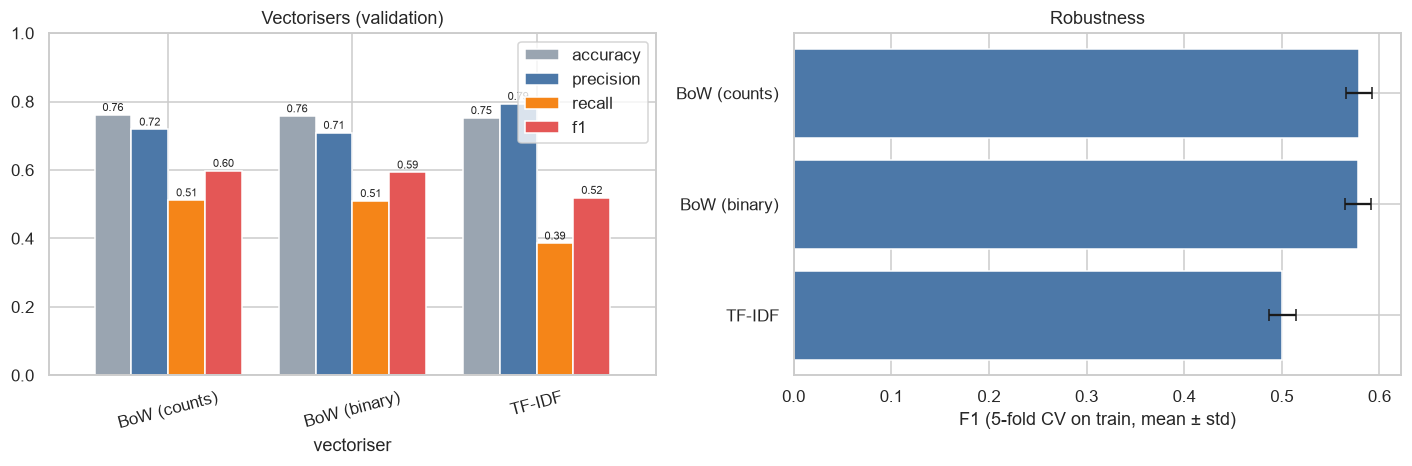

In [52]:
# Final preprocessed texts of the winning variant (train / validation)
tr_final, va_final = texts[best]

# The vocabulary settings of TF-IDF are reused for Bag of Words. We keep only the parameters that
# CountVectorizer also understands (TF-IDF-only options like sublinear_tf, norm, use_idf are dropped).
count_params = {k: v for k, v in config.TFIDF_PARAMS.items() if k in CountVectorizer().get_params()}
print("Shared vocabulary settings:", count_params)

vectorizers = {
    "BoW (counts)":      CountVectorizer(**count_params),
    "BoW (binary)":      CountVectorizer(binary=True, **count_params),    # 1 if the word is present, else 0
    "TF-IDF":            TfidfVectorizer(**config.TFIDF_PARAMS),
}

vec_records = []
for vname, vec in vectorizers.items():
    # Fit on TRAIN only, transform validation (no leakage)
    X_tr = vec.fit_transform(tr_final)
    X_va = vec.transform(va_final)
    clf = LogisticRegression(max_iter=2000, random_state=config.RANDOM_STATE).fit(X_tr, train["label"])
    pred = clf.predict(X_va)

    # 5-fold CV: the vectoriser is inside the pipeline, so it is re-fitted on each training fold
    pipe = Pipeline([("vec", vec.__class__(**vec.get_params())),          # fresh, unfitted copy of the same vectoriser
                     ("clf", LogisticRegression(max_iter=2000, random_state=config.RANDOM_STATE))])
    cv_scores = cross_val_score(pipe, tr_final, train["label"], cv=skf, scoring="f1", n_jobs=-1)

    vec_records.append({"vectoriser": vname,
                        "n_features": X_tr.shape[1],
                        "density_%": round(100 * X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1]), 3),   # share of non-zero cells
                        **compute_metrics(val["label"], pred),
                        "cv_f1_mean": cv_scores.mean(), "cv_f1_std": cv_scores.std()})

vec_cmp = pd.DataFrame(vec_records).set_index("vectoriser").sort_values("f1", ascending=False)
display(vec_cmp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
vec_cmp[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", ax=axes[0], rot=15, width=0.8,
                                                         color=["#9AA5B1", "#4C78A8", "#F58518", "#E45756"])
axes[0].set_ylim(0, 1); axes[0].set_title("Vectorisers (validation)")
for c in axes[0].containers:
    axes[0].bar_label(c, fmt="%.2f", fontsize=7, padding=1)
c = vec_cmp.sort_values("cv_f1_mean")
axes[1].barh(c.index, c["cv_f1_mean"], xerr=c["cv_f1_std"], color="#4C78A8", capsize=4)
axes[1].set_xlabel("F1 (5-fold CV on train, mean ± std)"); axes[1].set_title("Robustness")
savefig(fig, P.figures / "vectorisers_comparison.png")

**Reading.**
- `n_features` and `density_%` describe the representation: tweets are short, so the matrix is **very sparse** (a few percent of non-zero cells at most). Sparse matrices are stored efficiently by scikit-learn, so this is not a problem.
- Compare the vectorisers on **both** the validation F1 and the cross-validation F1, and apply the same rule as before: a difference smaller than about one standard deviation is a tie, and the simpler / more standard method is preferred.
- TF-IDF is expected to be at least as good as raw counts here because words like `user` and the remaining very common tokens dominate the counts; the IDF weighting reduces their influence. If the table shows a tie, TF-IDF is still the natural choice: it is the classical, efficient option named by the assignment and the one used by every part of the project.
- The vocabulary settings (`min_df`, `ngram_range`, `max_features`) come from the Part 1 observations: 54 % of the words appear only once (hence `min_df=2`) and offensiveness is sometimes expressed by word pairs (hence bigrams).
- **Decision:** keep the vectoriser with the best validation **and** cross-validation F1 (TF-IDF by default in this project, see `src/config.py`).

<a id="p3-10"></a>
## 3.10 Optional: word embeddings (Word2Vec, BERT)
Embeddings are the "advanced" option of the assignment. Two remarks:

* **Word2Vec trained only on our 12,000 tweets** is a very small corpus: the vectors are usually *worse* than TF-IDF on such a dataset. The cell below tests it anyway (it is skipped automatically if `gensim` is not installed) by averaging the word vectors of each tweet.
* **BERT** (pre-trained, contextual) is the serious embedding option: it can capture sarcasm and implicit insults that bag-of-words models cannot (limit identified in Part 1). It is heavier (GPU recommended), so it is treated in Part 5 (fine-tuning) and compared with the classical models in Part 6.

In [53]:
try:
    from gensim.models import Word2Vec                       # optional dependency
    tok_tr = [t.split() for t in tr_final]                   # tokenised training tweets
    tok_va = [t.split() for t in va_final]

    # Train Word2Vec on the TRAIN tweets only (fixed seed, single worker -> reproducible)
    w2v = Word2Vec(sentences=tok_tr, vector_size=100, window=5, min_count=2, seed=config.RANDOM_STATE, workers=1, epochs=20)

    def tweet_vector(tokens):
        """Average of the vectors of the tweet's known words (zero vector if none is known)."""
        vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
        return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

    X_tr_w2v = np.vstack([tweet_vector(t) for t in tok_tr])
    X_va_w2v = np.vstack([tweet_vector(t) for t in tok_va])
    clf = LogisticRegression(max_iter=2000, random_state=config.RANDOM_STATE).fit(X_tr_w2v, train["label"])
    w2v_metrics = compute_metrics(val["label"], clf.predict(X_va_w2v))
    print("Word2Vec (averaged) – validation:", {k: round(v, 4) for k, v in w2v_metrics.items()})
    print("TF-IDF reference F1             :", round(vec_cmp.loc["TF-IDF", "f1"], 4))
except ImportError:
    w2v_metrics = None
    print("gensim is not installed -> Word2Vec test skipped (pip install gensim to run it).")

Word2Vec (averaged) – validation: {'accuracy': 0.6911, 'precision': 0.6562, 'recall': 0.2288, 'f1': 0.3393}
TF-IDF reference F1             : 0.5191


**Reading.** If Word2Vec runs, compare its F1 with TF-IDF: with so little text it is normally lower, which justifies keeping TF-IDF as the main representation.
Averaging also loses word order and negation scope. Contextual models (BERT) are the way to go beyond this limit.

<a id="p3-11"></a>
## 3.11 Saving the results
The final texts (`text_clean`) are saved for the next parts, and the comparison tables for the report.

In [54]:
# 1) Final datasets: columns text, text_base (Part 2), text_clean (FINAL), label
for name, d in final.items():
    d.to_csv(P.processed / f"{name}_final.csv", index=False)
    back = pd.read_csv(P.processed / f"{name}_final.csv", keep_default_na=False)       # re-read and verify
    assert len(back) == len(d) and (back["label"].values == d["label"].values).all(), f"{name}: file differs"
    print(f"✔ {name}_final.csv -> {back.shape[0]} rows, columns = {list(back.columns)}")

# 2) Metric tables for the report
comparison.round(5).to_csv(P.metrics / "preprocessing_comparison.csv")
vec_cmp.round(5).to_csv(P.metrics / "vectorisers_comparison.csv")
print("\nMetrics:", sorted(p.name for p in Path(P.metrics).glob("*.csv")))
print("Figures:", sorted(p.name for p in Path(P.figures).glob("*.png")))

✔ train_final.csv -> 11916 rows, columns = ['text', 'text_base', 'text_clean', 'label']
✔ val_final.csv -> 1324 rows, columns = ['text', 'text_base', 'text_clean', 'label']
✔ test_final.csv -> 860 rows, columns = ['text', 'text_base', 'text_clean', 'label']

Metrics: ['preprocessing_comparison.csv', 'vectorisers_comparison.csv']
Figures: ['confusion_matrices_variants.png', 'cv_f1_by_variant.png', 'f1_by_variant.png', 'stopwords_variants.png', 'vectorisers_comparison.png']


**Reading.** The three `*_final.csv` files contain the final `text_clean` column and are the inputs of the modelling parts (always reload with `keep_default_na=False`).
The two CSV tables (`preprocessing_comparison.csv`, `vectorisers_comparison.csv`) can be pasted directly into the report.

---

<a id="part4"></a>
# Part 4 · Class balance experiments



### Why this experiment?
Part 1 showed that only about **one tweet in three is offensive** (33 % in train). A classifier trained on such data tends to say
"non-offensive" too often: precision is good but **recall (the share of offensive tweets actually found) is low**. In Part 3 the best
model still missed about 60 % of offensive tweets. Four strategies are compared:

| Strategy | What is done | Applied to |
|---|---|---|
| **none (original)** | nothing (reference) | – |
| **undersampling** | randomly drop non-offensive tweets until both classes have the same size | train rows only |
| **oversampling** | randomly duplicate offensive tweets until both classes have the same size | train rows only |
| **class_weight** | give a larger penalty to mistakes on the offensive class (`class_weight="balanced"`) | training loss |

### Principle: a fair comparison
As in Part 3, **only one thing changes** between the strategies: the way the imbalance is handled. Same final `text_clean`, same TF-IDF features,
same model, same random seed.

> **Golden rule.** Balancing touches the **training rows only**. The validation and test sets keep their original distribution, otherwise the scores
> would not describe a realistic situation. TF-IDF is fitted **once** on the original train, so the four strategies share exactly the same features.
> The **test set is never used** here.

### Contents
1. [Setup](#p4-1) · 2. [Loading the final text](#p4-2) · 3. [Applying the strategies](#p4-3) · 4. [Results](#p4-4) · 5. [Precision / recall trade-off](#p4-5) ·
6. [Confusion matrices](#p4-6) · 7. [Second model (SVM)](#p4-7) · 8. [Decision](#p4-8) · 9. [Creating the balanced training set](#p4-9) · 10. [Saving](#p4-10)

> **How to read this part.** Code cells are commented line by line; every result cell is followed by a **Reading** or **Results explained** cell.

<a id="p4-1"></a>
## 4.1 Setup
Imports and project modules. Reusable logic stays in `src/` (balancing in `src/balancing.py`, models in `src/logistic_regression.py` and `src/svm.py`),
so that exactly the same code is used in every part.

In [55]:
import sys, warnings, time               # sys: import path | warnings: hide noise | time: (optional) timing
from pathlib import Path                 # OS-independent paths

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)

# Project root (works from the root folder or from notebooks/)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))            # lets Python find the `src` package

from src import config                                   # central settings: random seed, TF-IDF parameters...
from src.utils import setup_paths, savefig               # standard folders + figure saving
P = setup_paths("04_class_balance_experiments")          # outputs go to results/*/04_class_balance_experiments/

# Make sure every output folder exists (parents=True creates missing parents; exist_ok=True never fails)
for d in (P.figures, P.metrics, P.processed):
    Path(d).mkdir(parents=True, exist_ok=True)

from src.features import fit_tfidf, transform_tfidf                 # fit on train / transform other sets (no leakage)
from src.evaluation import compute_metrics, get_confusion_matrix   # accuracy, precision, recall, F1 + confusion matrix
from src.visualization import plot_confusion_matrices              # grid of confusion-matrix heatmaps
from src.balancing import apply_balancing, resample_indices, STRATEGIES   # strategies, function applying them, row selection
from src import logistic_regression, svm                           # the two models compared in this notebook

print("Project root:", P.root)
print("Figures ->", P.figures)
print("Metrics ->", P.metrics)
print("Strategies:", list(STRATEGIES))

Project root: C:\Users\ASUS\Desktop\TweetEval-offensiveML
Figures -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\figures\04_class_balance_experiments
Metrics -> C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\04_class_balance_experiments
Strategies: ['none', 'undersampling', 'oversampling', 'class_weight']


**Reading.** The printed paths confirm where the outputs will be written (folders are created if missing), and the last line lists the four strategies
that will be compared.

<a id="p4-2"></a>
## 4.2 Loading the final text from Part 3
Part 3 already applied the best preprocessing variant and stored the result in the column **`text_clean`** of `*_final.csv`.
We simply read it, so no preprocessing is repeated here and the two parts cannot disagree.

`keep_default_na=False` keeps empty cleaned tweets as empty strings (otherwise pandas turns them into `NaN` and TF-IDF fails).

In [56]:
train_path, val_path = P.processed / "train_final.csv", P.processed / "val_final.csv"
# Fail with a clear message if Part 3 has not been run yet
for p in (train_path, val_path):
    assert p.exists(), f"{p.name} not found: run Part 3 first (it creates the *_final.csv files)."

train = pd.read_csv(train_path, keep_default_na=False)
val   = pd.read_csv(val_path,   keep_default_na=False)

# ONE TF-IDF for all strategies: fitted on the ORIGINAL train only, then applied to validation (no leakage)
vec, X_train = fit_tfidf(train["text_clean"])
X_val = transform_tfidf(vec, val["text_clean"])
y_train, y_val = train["label"].values, val["label"].values

print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print(f"offensive share  train = {100 * y_train.mean():.1f} %   val = {100 * y_val.mean():.1f} %")
display(train[["text", "text_clean", "label"]].head(5))

X_train: (11916, 17550) | X_val: (1324, 17550)
offensive share  train = 33.1 %   val = 34.7 %


,text,text_clean,label
0,@user Bono... who cares. Soon people will understand that they gain nothing from following a phony celebrity. Become...,user bono care soon people understand gain nothing follow phony celebrity become leader people instead help support ...,0
1,@user Eight years the republicans denied obama’s picks. Breitbarters outrage is as phony as their fake president.,user eight year republican deny obama's pick breitbarters outrage phony fake president,1
2,@user Get him some line help. He is gonna be just fine. As the game went on you could see him progressing more with ...,user get line help gonna fine game go could see progress read bring miss deep ball presence need little time,0
3,@user @user She is great. Hi Fiona!,user user great hi fiona,0
4,@user She has become a parody unto herself? She has certainly taken some heat for being such an....well idiot. Could...,user become parody unto certainly take heat well idiot could optic know liberal optic no substance,1


**Reading.** The matrix shapes give the number of tweets and TF-IDF features. The offensive share (about a third in train and in validation) is the imbalance
we are trying to compensate for. Because TF-IDF is fitted once, any difference between strategies comes from the balancing itself, not from different features.

<a id="p4-3"></a>
## 4.3 Applying the four strategies (Logistic Regression)
For each strategy:

1. `apply_balancing` builds the training set it implies (fewer rows for undersampling, more rows for oversampling, a class-weight value for `class_weight`);
2. the model is trained with that strategy;
3. the **validation set, left unchanged**, is predicted and scored.

The metrics are those of the **offensive class**. Reminder:

* **Precision** – among the tweets flagged offensive, how many really are?
* **Recall** – among the truly offensive tweets, how many did we find?
* **F1** – harmonic mean of precision and recall (our main criterion, because accuracy is inflated by the majority class).

In [57]:
def run_strategies(module):
    """Train `module` (a model file of src/) with each balancing strategy and score it on the ORIGINAL validation set."""
    rows, cms = [], {}
    for s in STRATEGIES:
        # Xb, yb: the training data implied by the strategy (used here only to describe it); cw: the class weight used, if any
        Xb, yb, cw = apply_balancing(X_train, y_train, s, module.SUPPORTS_CLASS_WEIGHT)
        model = module.train(X_train, y_train, balance=s)       # the module applies the strategy itself
        pred = model.predict(X_val)                              # validation keeps its ORIGINAL distribution
        rows.append({"strategy": s,
                     "train_rows": Xb.shape[0],                                   # size of the training set after balancing
                     "pct_offensive_in_train": round(100 * yb.mean(), 1),         # class share after balancing
                     "class_weight": cw,
                     **compute_metrics(y_val, pred)})                             # accuracy, precision, recall, f1
        cms[s] = get_confusion_matrix(y_val, pred)
    return pd.DataFrame(rows).set_index("strategy"), cms

lr_table, lr_cms = run_strategies(logistic_regression)

**Reading.** Nothing is displayed: the table is analysed in the next section.

<a id="p4-4"></a>
## 4.4 Results on the validation set
Sorted by F1 of the offensive class. The columns `train_rows` and `pct_offensive_in_train` show what each strategy did to the training set
(undersampling shrinks it, oversampling enlarges it, `class_weight` leaves it unchanged).

,train_rows,pct_offensive_in_train,class_weight,accuracy,precision,recall,f1
strategy,,,,,,,
class_weight,11916,33.1,balanced,0.7402,0.6247,0.6275,0.6261
undersampling,7882,50.0,NaN,0.7205,0.5857,0.6623,0.6217
oversampling,15950,50.0,NaN,0.7402,0.6372,0.5817,0.6082
none,11916,33.1,NaN,0.7523,0.7937,0.3856,0.5191


Difference with the reference 'none':


,accuracy,precision,recall,f1
strategy,,,,
class_weight,-0.0121,-0.1690,0.2418,0.1070
undersampling,-0.0317,-0.2080,0.2767,0.1026
oversampling,-0.0121,-0.1565,0.1961,0.0891
none,0.0000,0.0000,0.0000,0.0000


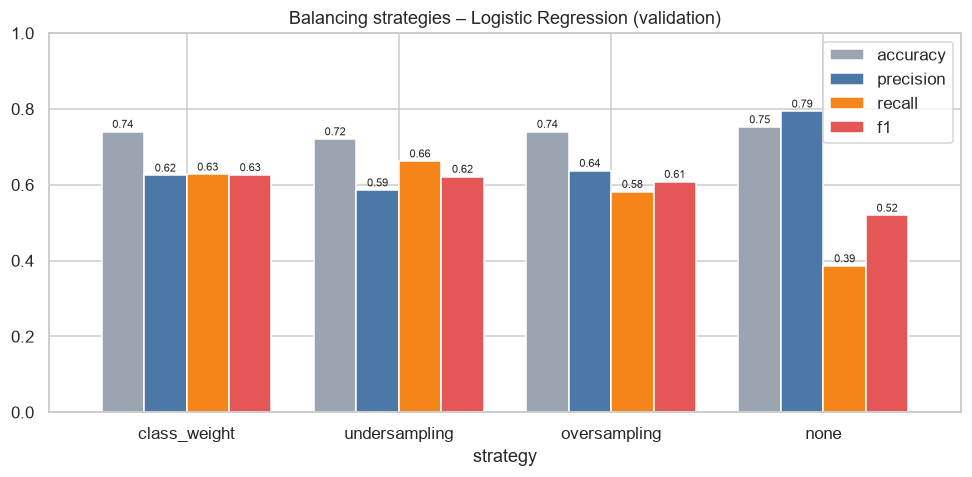

In [58]:
lr_table = lr_table.sort_values("f1", ascending=False)       # best strategy first
display(lr_table.round(4))

# Difference with the reference ("none"): positive = better than doing nothing
ref = lr_table.loc["none", ["accuracy", "precision", "recall", "f1"]]
print("Difference with the reference 'none':")
display((lr_table[["accuracy", "precision", "recall", "f1"]] - ref).round(4))

fig, ax = plt.subplots(figsize=(9, 4.5))
lr_table[["accuracy", "precision", "recall", "f1"]].plot(kind="bar", ax=ax, width=0.8, rot=0,
                                                       color=["#9AA5B1", "#4C78A8", "#F58518", "#E45756"])
ax.set_ylim(0, 1); ax.set_title("Balancing strategies – Logistic Regression (validation)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7, padding=1)       # value above each bar
savefig(fig, P.figures / "f1_by_strategy.png")

**Reading.** Look at where the gain comes from: the delta table shows precision going down and recall going up. A strategy is useful if the **F1 rises**, i.e. if the recall gain
is larger than the precision loss. Accuracy may drop: it is dominated by the majority class and is not our criterion. **Warning:** the validation set has only
1,324 tweets (459 offensive), so differences of one or two F1 points between strategies can be noise; large gaps are meaningful.

<a id="p4-5"></a>
## 4.5 Precision / recall trade-off
Each point is one strategy. Moving right means finding more offensive tweets; moving up means fewer false alarms.

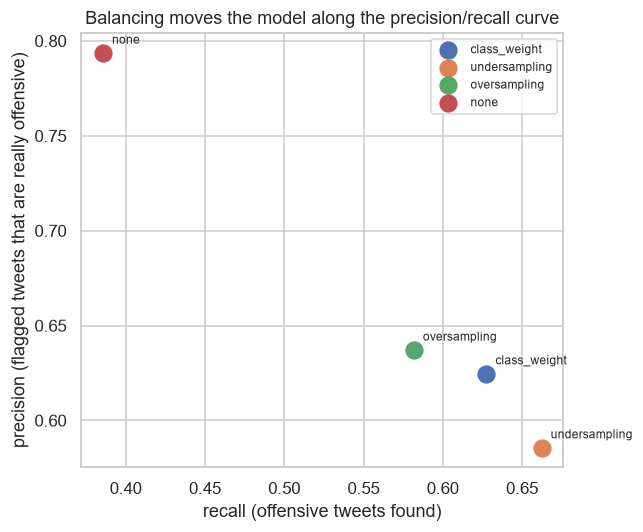

In [59]:
fig, ax = plt.subplots(figsize=(6, 5))
for s, r in lr_table.iterrows():
    ax.scatter(r["recall"], r["precision"], s=120, label=s)                      # one point per strategy
    ax.annotate(s, (r["recall"], r["precision"]), textcoords="offset points", xytext=(6, 6), fontsize=8)
ax.set_xlabel("recall (offensive tweets found)"); ax.set_ylabel("precision (flagged tweets that are really offensive)")
ax.set_title("Balancing moves the model along the precision/recall curve"); ax.legend(fontsize=8)
savefig(fig, P.figures / "precision_recall_tradeoff.png")

**Reading.** Balancing usually **raises recall** (more offensive tweets are found) and **lowers precision** (more normal tweets are wrongly flagged):
the unbalanced model sits at the top-left (precise but misses many), the balanced ones move towards the right. Accuracy can go down while the F1 of the offensive class goes up.
Which side to favour depends on the application: an automatic moderation tool that sends tweets to a human tolerates false alarms, whereas a fully automatic ban would not.

<a id="p4-6"></a>
## 4.6 Confusion matrices (validation)
The confusion matrices show **how** each strategy is wrong:

* **false negatives** (offensive tweets predicted non-offensive) → hurt recall;
* **false positives** (non-offensive tweets predicted offensive) → hurt precision.

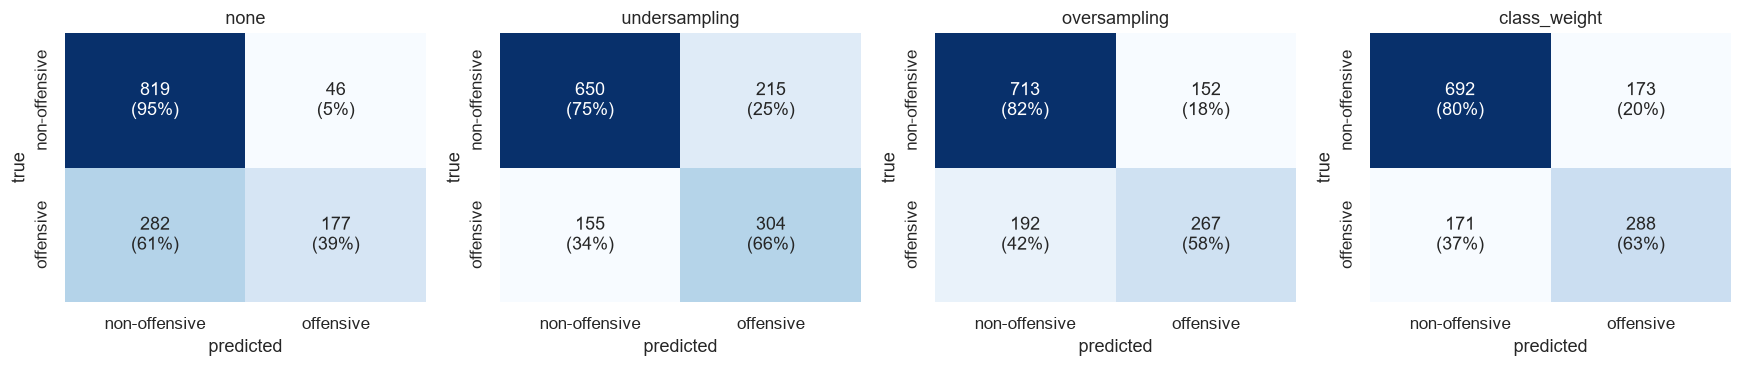

In [60]:
# One heatmap per strategy, in the order of STRATEGIES
fig = plot_confusion_matrices({k: lr_cms[k] for k in STRATEGIES}, ncols=4, figsize_per=(4.0, 3.5))
savefig(fig, P.figures / "confusion_matrices_strategies.png")

**Reading.** Compare the bottom-left cell (missed offensive tweets) with the top-right cell (false alarms): balancing shrinks the first and inflates the second.
The best strategy is the one that reduces the missed tweets the most for the smallest increase in false alarms.

<a id="p4-7"></a>
## 4.7 Is the conclusion model-specific? Same strategies with a linear SVM
A conclusion drawn with one model may not hold for another. We repeat the experiment with a **linear SVM**, using exactly the same features, strategies and validation set.

In [61]:
svm_table, svm_cms = run_strategies(svm)
svm_table = svm_table.sort_values("f1", ascending=False)
display(svm_table.round(4))
print("(Naive Bayes / KNN have no class_weight option: for them 'class_weight' falls back to oversampling.)")

,train_rows,pct_offensive_in_train,class_weight,accuracy,precision,recall,f1
strategy,,,,,,,
undersampling,7882,50.0,NaN,0.6994,0.5540,0.6819,0.6113
none,11916,33.1,NaN,0.7492,0.6759,0.5316,0.5951
class_weight,11916,33.1,balanced,0.7221,0.6018,0.5861,0.5938
oversampling,15950,50.0,NaN,0.7213,0.6077,0.5534,0.5792


(Naive Bayes / KNN have no class_weight option: for them 'class_weight' falls back to oversampling.)


**Reading.** Compare the two models: (1) which strategy is best for each, (2) how much the F1 gain is, (3) how the models compare **without** balancing.
If the best strategy differs, or the gain is small for one model, the effect of balancing is **model-dependent** and must be re-checked for every model
(Part 5 trains all models with the chosen strategy and Part 6 compares them).

<a id="p4-8"></a>
## 4.8 Decision
The code reads the tables and prints the setting to copy into `src/config.py`.

In [62]:
best = lr_table["f1"].idxmax()                      # strategy with the highest validation F1 (Logistic Regression)
print(f"Best strategy for Logistic Regression: {best}")
print(f"  F1 original     = {lr_table.loc['none', 'f1']:.4f}  ->  F1 {best} = {lr_table.loc[best, 'f1']:.4f}")
print(f"  recall original = {lr_table.loc['none', 'recall']:.4f}  ->  recall {best} = {lr_table.loc[best, 'recall']:.4f}")
print(f"Best strategy for SVM: {svm_table['f1'].idxmax()}")
print(f"\nSetting to copy into src/config.py:  BALANCING = \"{best}\"")

Best strategy for Logistic Regression: class_weight
  F1 original     = 0.5191  ->  F1 class_weight = 0.6261
  recall original = 0.3856  ->  recall class_weight = 0.6275
Best strategy for SVM: undersampling

Setting to copy into src/config.py:  BALANCING = "class_weight"


### Conclusion (results of the delivered run; re-check the tables above if you re-run)
| Strategy (Logistic Regression) | Precision | Recall | F1 (offensive) | Accuracy |
|---|---|---|---|---|
| none (original) | 0.794 | 0.386 | 0.519 | 0.752 |
| undersampling | 0.586 | 0.662 | 0.622 | 0.721 |
| oversampling | 0.637 | 0.582 | 0.608 | 0.740 |
| **class_weight** | **0.625** | **0.627** | **0.626** | 0.740 |

- Balancing raises the **F1 of the offensive class by about +0.10** (0.519 → 0.626), mainly through recall (0.39 → 0.63), at the price of precision (0.79 → 0.62).
  Accuracy drops slightly, which is expected and acceptable: it was inflated by the majority class.
- `class_weight` gives the best F1, is the simplest (no data duplicated or thrown away, same TF-IDF matrix) and gives a good precision/recall balance.
- With a linear SVM the picture is more nuanced: recall rises with every strategy (0.53 → 0.55–0.68) but the **F1 gain is small**; only undersampling beats the
  original (0.611 vs 0.595), `class_weight` is on par (0.594) and oversampling is lower (0.579). The unbalanced SVM is already much better than the unbalanced
  Logistic Regression (0.595 vs 0.519). Balancing therefore helps most for Logistic Regression, and its effect is model-dependent.
- The test set was **not** used. **Decision:** `BALANCING = "class_weight"` (already set in `src/config.py`); for Naive Bayes and KNN, which have no
  `class_weight` option, the code automatically falls back to oversampling.

<a id="p4-9"></a>
## 4.9 Creating the balanced training set
Once the best strategy is chosen, we can **materialise** it: build the balanced training set and save it as a **new file**, `train_balanced.csv`.

Rules followed here:

* only the **training rows** are balanced; `val_final.csv` and `test_final.csv` are never touched and keep their original distribution;
* `train_final.csv` is **not overwritten** (a new file is written), so the experiments above can always be reproduced;
* only **resampling** strategies (undersampling / oversampling) change rows. `class_weight` changes the **loss**, not the data, so there is nothing to
  materialise for it. In that case the file is built with **oversampling** (the same fallback the project uses for Naive Bayes and KNN, which have no `class_weight`), and this is printed explicitly.
* Oversampling **duplicates** offensive tweets, so this file must never be split again for cross-validation: copies of the same tweet would land in both
  the training and the validation fold and inflate the scores.

In [63]:
# Strategy used to build the file: the best one if it is a resampling strategy, otherwise oversampling
if best in ("undersampling", "oversampling"):
    file_strategy = best
else:
    file_strategy = "oversampling"
    print(f"Best strategy is '{best}' (a loss weight, not a data change) -> the balanced file is built with oversampling instead.")

# Row indices selected by the strategy (same seed as in the experiments -> same rows)
idx = resample_indices(y_train, file_strategy)
balanced = train.iloc[idx].reset_index(drop=True)          # original rows, selected / duplicated / shuffled

# Checks: the classes must now be equal in size, and the original data must be unchanged
share_before, share_after = 100 * y_train.mean(), 100 * balanced["label"].mean()
print(f"strategy used     : {file_strategy}")
print(f"rows              : {len(train)} -> {len(balanced)}")
print(f"offensive share   : {share_before:.1f} % -> {share_after:.1f} %")
print("class counts      :", balanced["label"].value_counts().to_dict())
assert abs(share_after - 50.0) < 0.5, "the balanced set is not balanced"
assert len(train) == len(pd.read_csv(train_path, keep_default_na=False)), "train_final.csv was modified"

balanced.to_csv(P.processed / "train_balanced.csv", index=False)       # NEW file; train_final.csv stays as it is
print("Saved:", P.processed / "train_balanced.csv")
display(balanced[["text", "text_clean", "label"]].head(5))

Best strategy is 'class_weight' (a loss weight, not a data change) -> the balanced file is built with oversampling instead.
strategy used     : oversampling
rows              : 11916 -> 15950
offensive share   : 33.1 % -> 50.0 %
class counts      : {1: 7975, 0: 7975}
Saved: C:\Users\ASUS\Desktop\TweetEval-offensiveML\data\processed\train_balanced.csv


,text,text_clean,label
0,@user @user Beware of rightist false flags like the narrative of the OK sign being a white nationalist dog whistle. ...,user user beware rightist false flag like narrative ok sign white nationalist dog whistle not theresistance resist b...,1
1,@user @user @user I absolutely agree!! I have tried rallying people on Twitter. Asking them to follow each other. St...,user user user absolutely agree try rally people twitter ask follow strength number vote work poll early election el...,0
2,@user @user If Brookee Baldwin and Erin Burnett start showing cleavage to their Boobies CNN just might.,user user brookee baldwin erin burnett start show cleavage booby cnn might,1
3,@user Thank you for proving my point. You are foulmouthed trash,user thank prove point foulmouthed trash,1
4,@user @user They've been trying. A couple of veterans happened 2 b assaulted by ANTIFA. Wrong!! They were surprised!...,user user try couple veteran happen 2 b assault antifa wrong surprise fight kinda break protest,0


**Reading.**
- The offensive share goes from about 33 % to 50 %. With undersampling the file is **smaller** than `train_final.csv` (non-offensive tweets removed); with oversampling it is **larger**
  (offensive tweets repeated), so some rows appear several times.
- The `assert` lines guarantee that the classes are equal and that `train_final.csv` still has its original size.
- **How to use the file.** Train a model on `train_balanced.csv` and evaluate it on `val_final.csv` / `test_final.csv` (original distribution). Fit TF-IDF on the training rows you actually train on.
  If you keep `class_weight` as the project strategy (the later parts apply it at training time), you do **not** need this file: it is provided for models or tools that cannot weight the classes.
- Validation and test files are untouched, so scores remain comparable with all previous parts.

<a id="p4-10"></a>
## 4.10 Saving the results
Both tables (Logistic Regression and SVM) are saved in one CSV, with a `model` column, for the report and the final synthesis (Part 7).

In [64]:
out_lr  = lr_table.copy();  out_lr["model"]  = "logistic_regression"
out_svm = svm_table.copy(); out_svm["model"] = "svm"
pd.concat([out_lr, out_svm]).round(5).to_csv(P.metrics / "balancing_comparison.csv")      # index = strategy name
print("Saved:", P.metrics / "balancing_comparison.csv")
print("Figures:", sorted(p.name for p in Path(P.figures).glob("*.png")))

Saved: C:\Users\ASUS\Desktop\TweetEval-offensiveML\results\metrics\04_class_balance_experiments\balancing_comparison.csv
Figures: ['confusion_matrices_strategies.png', 'f1_by_strategy.png', 'precision_recall_tradeoff.png']


**Reading.** The CSV contains one row per (model, strategy) with precision, recall, F1 and accuracy, and can be pasted directly into the report.

---

<a id="part5"></a>
# Part 5 · Model training (required + optional models)


### What the assignment asks
> Each group must test **at least five different models** among: Logistic Regression · SVM · Random Forest · Naive Bayes · KNN · *(optional: advanced models such as LSTM or BERT)*.

This part trains **all five required models**, then adds **optional models** to go further. Every model has its own file in `src/`:

| # | Model | Type | File in `src/` | Status |
|---|---|---|---|---|
| 1 | Logistic Regression | linear | `logistic_regression.py` | required |
| 2 | SVM (LinearSVC) | linear | `svm.py` | required |
| 3 | Random Forest | trees ensemble | `random_forest.py` | required |
| 4 | Naive Bayes | probabilistic | `naive_bayes.py` | required |
| 5 | KNN | distance based | `knn.py` | required |
| 6 | Complement NB · SGD · Voting ensemble | classical extras | `extra_models.py` | optional |
| 7 | **BiLSTM** | deep learning (sequence) | `lstm_model.py` | optional (needs `torch`) |
| 8 | **BERT / DistilBERT** | Transformer fine-tuning | `bert_model.py` | optional (needs `torch`, `transformers`, GPU advised) |

Shared helpers: `model_utils.py` (grid search, oversampling, scores) and `torch_utils.py` (training loop of the two neural models).

### Rules applied to every model (fair comparison)
* one seed (`config.RANDOM_STATE`) · TF-IDF fitted on **train only** · hyperparameters chosen on **validation**, criterion = **F1 of the offensive class** · the **test set is never used** here;
* imbalance (about 1 offensive tweet in 3) handled **without altering the validation data**, following the decision of Part 4 (`class_weight`, with equivalents for models that have none).

### Metrics reminder (offensive = positive class)
* **Precision** = of the tweets flagged offensive, how many really are? (few false alarms)
* **Recall** = of the truly offensive tweets, how many did we catch? (few misses)
* **F1** = harmonic mean of precision and recall → our **main criterion** (accuracy is inflated by the majority class).
* **Average precision (AP)** = area under the precision-recall curve: compares models **independently of the 0.5 threshold**.

### Contents
1. [Setup and switches](#p5-1) · 2. [Data and features](#p5-2) · 3. [Logistic Regression](#p5-3) · 4. [SVM](#p5-4) · 5. [Random Forest](#p5-5) · 6. [Naive Bayes](#p5-6) · 7. [KNN](#p5-7) ·
8. [Optional classical models](#p5-8) · 9. [Optional: BiLSTM](#p5-9) · 10. [Optional: BERT](#p5-10) · 11. [Comparison](#p5-11) · 12. [Cross-validation](#p5-12) · 13. [What the linear models learned](#p5-13) · 14. [Conclusions](#p5-14) · 15. [Saving](#p5-15)

> Each result cell is followed by a **Reading** cell explaining how to interpret it.

<a id="p5-1"></a>
## 5.1 Setup and switches
Switches (defined in the **global configuration cell, Part 0**) control the slow / optional parts. **The five required models always run.**

| Switch | Meaning |
|---|---|
| `RUN_EXTRA` | classical optional models (seconds) |
| `RUN_LSTM`, `RUN_BERT` | `True` = run, `False` = skip, `"auto"` = run only if `torch` is installed **and** a GPU is available (so a laptop without GPU never blocks for an hour) |
| `RUN_CV` | 5-fold cross-validation of the classical models (a few minutes) |

In [65]:
import sys, warnings                              # sys: python import path | warnings: hide noisy warnings
from pathlib import Path                           # OS-independent file paths

import numpy as np                                 # numerical arrays
import pandas as pd                                # tables
import matplotlib.pyplot as plt                    # plots
import seaborn as sns                              # nicer plot defaults
from sklearn.metrics import (ConfusionMatrixDisplay,      # draws a confusion matrix
                             average_precision_score,     # AP: threshold-free ranking quality
                             precision_recall_curve)      # points of the PR curve
from sklearn.model_selection import StratifiedKFold      # CV folds that keep the class ratio

warnings.filterwarnings("ignore")                  # keep the notebook readable
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110                   # sharper figures
pd.set_option("display.max_colwidth", 120)

# Project root: works whether Jupyter was started in the root folder or in notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))                      # lets Python import the `src` package

# ---- shared project modules (same ones as Parts 3 and 4) --------------------
from src import config                                              # seed, TF-IDF parameters, BALANCING decision
from src.utils import setup_paths, savefig                          # standard output folders + figure saving
from src.features import fit_tfidf, transform_tfidf                 # fit on train / transform other sets
from src.evaluation import compute_metrics, get_confusion_matrix   # accuracy, precision, recall, F1 + confusion matrix
# ---- one file per model ------------------------------------------------------------
from src import logistic_regression, svm, random_forest, naive_bayes, knn
from src import extra_models, lstm_model, bert_model, torch_utils
from src.model_utils import get_scores, oversample, top_linear_terms

# Switches RUN_EXTRA / RUN_LSTM / RUN_BERT / RUN_CV are defined once, in the global configuration cell (Part 0).

def _enabled(flag):
    """Resolve True / False / 'auto' (auto = torch + GPU available)."""
    if flag == "auto":
        return torch_utils.TORCH_OK and torch_utils.torch.cuda.is_available()
    return bool(flag)

P = setup_paths("05_model_training")               # folders: results/{figures,metrics}/05_model_training/
PRED_DIR = P.root / "results" / "predictions" / "05_model_training"
MODEL_DIR = P.root / "models"                      # NEW: saved neural models (loaded by Part 6)
for d in (P.figures, P.metrics, PRED_DIR, MODEL_DIR):
    Path(d).mkdir(parents=True, exist_ok=True)     # create the output folders if missing

SEED = config.RANDOM_STATE                         # ONE seed for the whole project
COLORS = {"non-offensive": "#4C78A8", "offensive": "#E45756"}        # class colours
MODEL_COLORS = {"Logistic Regression": "#54A24B", "SVM (LinearSVC)": "#72B7B2", "Random Forest": "#F58518",
                "Naive Bayes": "#B279A2", "KNN": "#9D755D", "Complement NB": "#D4A6C8",
                "SGD (modified Huber)": "#9ECAE9", "Voting ensemble": "#BAB0AC",
                "BiLSTM": "#E15759", "BERT": "#EDC948"}              # one colour per model

print("Root          :", P.root)
print("Seed          :", SEED)
print("torch present :", torch_utils.TORCH_OK, "| GPU:", torch_utils.TORCH_OK and torch_utils.torch.cuda.is_available())
print("Run optional  : extra =", RUN_EXTRA, "| LSTM =", _enabled(RUN_LSTM), "| BERT =", _enabled(RUN_BERT), "| CV =", RUN_CV)

Root          : C:\Users\ASUS\Desktop\TweetEval-offensiveML
Seed          : 42
torch present : True | GPU: True
Run optional  : extra = True | LSTM = True | BERT = True | CV = True


**Reading.** The last lines show what will actually run. If `torch present` is `False` or there is no GPU, the LSTM and BERT sections are skipped automatically
(you can still force them with `True`, or run them on Google Colab). The required models never depend on these switches.

<a id="p5-2"></a>
## 5.2 Data and features
We read the **final** files of Part 3: `text_clean` (cleaned text, used by the TF-IDF models and the LSTM) and `text` (original tweet, used by BERT).
`keep_default_na=False` keeps empty cleaned tweets as empty strings (otherwise pandas turns them into `NaN` and TF-IDF fails).
**TF-IDF is fitted once on train only** and shared by all classical models.

### How each classical model handles the class imbalance
| Model | Strategy | Why |
|---|---|---|
| Logistic Regression, LinearSVC, Random Forest, SGD | `class_weight="balanced"` | Part 4 decision: nothing duplicated or removed |
| Naive Bayes | equal priors `fit_prior=False` | no `class_weight` option; equal priors play the same role |
| Complement NB | built for imbalanced text | uses statistics of the *complement* of each class |
| KNN | random **oversampling** of the training offensive tweets | no `class_weight`; fallback of Part 4 |
| BiLSTM, BERT | class-weighted cross-entropy loss | same idea as `class_weight`, inside the loss |

Only **training** rows are ever rebalanced; validation keeps its original distribution.

In [66]:
train_path, val_path = P.processed / "train_final.csv", P.processed / "val_final.csv"
for p in (train_path, val_path):                                  # friendly error if Part 3 was not run
    assert p.exists(), f"{p.name} not found: run Part 3 first (it creates the *_final.csv files)."

train = pd.read_csv(train_path, keep_default_na=False)            # cleaned train split
val   = pd.read_csv(val_path,   keep_default_na=False)            # cleaned validation split

# Original text for BERT; fall back to the cleaned text if the column is absent
RAW = "text" if {"text"} <= set(train.columns) and {"text"} <= set(val.columns) else "text_clean"
if RAW == "text_clean":
    print("WARNING: no 'text' column -> BERT will receive the cleaned text (less ideal).")

vec, X_train = fit_tfidf(train["text_clean"])                     # learn vocabulary + IDF on TRAIN only
X_val = transform_tfidf(vec, val["text_clean"])                   # val is only TRANSFORMED (no leakage)
y_train, y_val = train["label"].to_numpy(), val["label"].to_numpy()   # 0 = non-offensive, 1 = offensive
feature_names = vec.get_feature_names_out()                       # TF-IDF column -> word / bigram

print("X_train:", X_train.shape, "| X_val:", X_val.shape)
print(f"offensive share  train = {100 * y_train.mean():.1f} %   val = {100 * y_val.mean():.1f} %")
print("TF-IDF settings :", config.TFIDF_PARAMS)

X_train: (11916, 17550) | X_val: (1324, 17550)
offensive share  train = 33.1 %   val = 34.7 %
TF-IDF settings : {'max_features': 20000, 'ngram_range': (1, 2), 'min_df': 2, 'token_pattern': "[a-z0-9'*]+"}


**Reading.** Train and validation have the same number of columns because the vocabulary comes from train only. The offensive share (about one third) is the imbalance handled above.
Because the TF-IDF matrix is shared, every classical model sees **exactly the same input**: score differences come from the algorithm, not from the data.

### The model registry
Every model, whatever its type, is stored in the dictionary `PRED` as **(predicted labels, continuous scores)** on the validation set.
Section 11 builds all tables and plots from this single dictionary, so adding a model never requires touching the comparison code.

In [67]:
PRED = {}        # name -> {"group": ..., "y_pred": ..., "scores": ..., "params": ...}  (insertion order = display order)
MODELS = {}      # name -> fitted sklearn estimator (only classical models; used for CV and top terms)

def register(name, y_pred, scores=None, group="required", params=None, model=None):
    """Store the validation predictions of one model (and the fitted estimator if there is one)."""
    PRED[name] = {"group": group, "y_pred": np.asarray(y_pred), "scores": scores, "params": params}
    if model is not None:
        MODELS[name] = model

def register_model(name, model, group="required", params=None):
    """Shortcut for a fitted scikit-learn model: predict on val, get its scores, register everything."""
    register(name, model.predict(X_val), get_scores(model, X_val), group, params, model)

def edge_warning(best, values, label):
    """Warn if the best value sits at the border of the grid (the grid may be too narrow)."""
    if best in (values[0], values[-1]):
        print(f"WARNING: best {label} is at the edge of the grid -> consider extending it.")

<a id="p5-3"></a>
## 5.3 Model 1 · Logistic Regression  (`src/logistic_regression.py`)
**Idea.** A weighted sum of TF-IDF features is passed through a sigmoid to give P(offensive). Training finds the weights that best explain the labels.
**Hyperparameter `C`** = inverse regularisation strength: small `C` → simple model (underfitting risk), large `C` → flexible model (overfitting risk).
**Imbalance:** `class_weight="balanced"` makes mistakes on offensive tweets cost about twice as much.

In [68]:
# tune(): trains one model per value of C, keeps the best validation F1 (offensive class)
lr, best_lr_C, lr_grid = logistic_regression.tune(X_train, y_train, X_val, y_val)
print(f"Best C = {best_lr_C}  (F1 val = {lr_grid['F1 val (offensive)'].max():.4f})")
edge_warning(best_lr_C, logistic_regression.DEFAULT_C_GRID, "C")          # is the grid wide enough?
register_model(logistic_regression.NAME, lr, params={"C": best_lr_C})      # keep predictions for the comparison
display(lr_grid)                                                           # whole tuning table

Best C = 1  (F1 val = 0.6261)


,C,F1 val (offensive)
0,1.0,0.6261
1,3.0,0.6183
2,100.0,0.6075
3,10.0,0.6071
4,0.3,0.6059
5,30.0,0.5956
6,0.1,0.5903


**Reading.** A best `C` strictly *inside* the grid means the grid is wide enough (the warning would appear otherwise). Differences of one or two thousandths between neighbouring `C` are noise:
what matters is the overall shape (rise, plateau, then slight drop).

<a id="p5-4"></a>
## 5.4 Model 2 · SVM / LinearSVC  (`src/svm.py`)
**Idea.** Find the separating hyperplane with the **largest margin** between the classes. With TF-IDF text a **linear** kernel is the standard choice (thousands of sparse dimensions, almost always linearly separable enough; RBF kernels are far slower with little gain).
**Hyperparameter `C`** again controls regularisation, but its best value is usually *smaller* than for Logistic Regression because the two loss functions are scaled differently.

In [69]:
svm_model, best_svm_C, svm_grid = svm.tune(X_train, y_train, X_val, y_val)    # same procedure, same criterion
print(f"Best C = {best_svm_C}  (F1 val = {svm_grid['F1 val (offensive)'].max():.4f})")
edge_warning(best_svm_C, svm.DEFAULT_C_GRID, "C")
register_model(svm.NAME, svm_model, params={"C": best_svm_C})
display(svm_grid)

Best C = 0.3  (F1 val = 0.6233)


,C,F1 val (offensive)
0,0.30,0.6233
1,0.10,0.6186
2,0.03,0.6039
3,3.00,0.5982
4,1.00,0.5938
5,0.01,0.5915


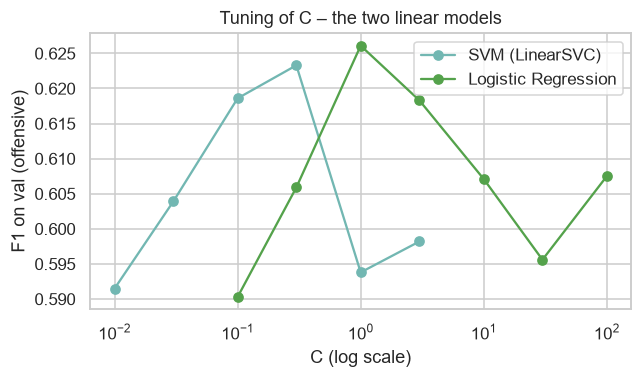

In [70]:
# Both linear models share the same C axis (log scale) so their curves can be compared directly
fig, ax = plt.subplots(figsize=(6, 3.6))
for name, tab in ((svm.NAME, svm_grid), (logistic_regression.NAME, lr_grid)):
    t = tab.sort_values("C")                                                  # increasing C for a clean line
    ax.plot(t["C"], t["F1 val (offensive)"], marker="o", color=MODEL_COLORS[name], label=name)
ax.set_xscale("log"); ax.set_xlabel("C (log scale)"); ax.set_ylabel("F1 on val (offensive)")
ax.set_title("Tuning of C – the two linear models"); ax.legend()
fig.tight_layout(); savefig(fig, P.figures / "linear_models_tuning_C.png"); plt.show()

**Reading.** Each curve should have an optimum with a decline on both sides: **underfitting** on the left (too much regularisation), **overfitting** on the right (too little). The optima sit at different `C` values, which is normal.

<a id="p5-5"></a>
## 5.5 Model 3 · Random Forest  (`src/random_forest.py`)
**Idea.** Many decision trees, each trained on a random bootstrap sample and random subsets of features; the forest **votes**. It is **non-linear** (can combine words) and robust,
but trees split on one feature at a time, which is inefficient on a huge sparse vocabulary → the grid is small (trees × depth) and training is slower.
**Limiting `max_depth`** is a simple anti-overfitting tool for text. `class_weight="balanced"` is used.

In [71]:
rf, best_rf_params, rf_grid = random_forest.tune(X_train, y_train, X_val, y_val)
print(f"Best parameters = {best_rf_params}  (F1 val = {rf_grid['F1 val (offensive)'].max():.4f})")
register_model(random_forest.NAME, rf, params=best_rf_params)
display(rf_grid)

Best parameters = {'max_depth': None, 'n_estimators': 300}  (F1 val = 0.6326)


,max_depth,n_estimators,F1 val (offensive)
0,NaN,300,0.6326
1,30.0,300,0.6270
2,30.0,100,0.6123
3,NaN,100,0.6032


**Reading.** Compare rows with `max_depth = 30` and `None`: if the limited depth wins, unrestricted trees memorise the training tweets (overfitting). More trees (`300` vs `100`) usually help slightly and never hurt, only costing time.

<a id="p5-6"></a>
## 5.6 Model 4 · Naive Bayes  (`src/naive_bayes.py`)
**Idea.** Bayes' rule with the "naive" assumption that words are independent given the class: P(class | words) ∝ P(class) · ∏ P(word | class). Extremely fast and good with little data; the independence assumption is crude and probabilities are poorly calibrated.
**Hyperparameter `alpha`** = Laplace smoothing (avoids zero probability for a word never seen in a class).
**Imbalance:** there is no `class_weight`, so we use **equal priors** (`fit_prior=False`). The cell checks this choice against learned priors.

In [72]:
nb, best_nb_alpha, nb_grid = naive_bayes.tune(X_train, y_train, X_val, y_val)      # equal priors by default
print(f"Best alpha = {best_nb_alpha}  (F1 val = {nb_grid['F1 val (offensive)'].max():.4f})")
edge_warning(best_nb_alpha, naive_bayes.DEFAULT_ALPHA_GRID, "alpha")
register_model(naive_bayes.NAME, nb, params={"alpha": best_nb_alpha})
display(nb_grid)

# Justification: same alpha, but with priors LEARNED from class frequencies (balance=False)
nb_learned = naive_bayes.train(X_train, y_train, alpha=best_nb_alpha, balance=False)
m_l = compute_metrics(y_val, nb_learned.predict(X_val)); m_e = compute_metrics(y_val, nb.predict(X_val))
print(f"\nlearned priors : F1 = {m_l['f1']:.4f}  precision = {m_l['precision']:.4f}  recall = {m_l['recall']:.4f}")
print(f"equal priors   : F1 = {m_e['f1']:.4f}  precision = {m_e['precision']:.4f}  recall = {m_e['recall']:.4f}")

Best alpha = 0.3  (F1 val = 0.5717)


,alpha,F1 val (offensive)
0,0.10,0.5717
1,0.30,0.5717
2,0.03,0.5506
3,1.00,0.5390



learned priors : F1 = 0.4384  precision = 0.7273  recall = 0.3137
equal priors   : F1 = 0.5717  precision = 0.5749  recall = 0.5686


**Reading.** With learned priors the model favours the majority class (non-offensive): **recall drops** and many offensive tweets are missed. Equal priors rebalance the decision and raise the F1 of the offensive class: the Naive Bayes equivalent of `class_weight`.

<a id="p5-7"></a>
## 5.7 Model 5 · KNN  (`src/knn.py`)
**Idea.** A tweet gets the majority class of its **k closest training tweets** (no real training: the data *is* the model). We use the **cosine distance** (angle between TF-IDF vectors), the right choice for text.
**Weakness.** In a sparse, very high-dimensional space almost all tweets are equally far from each other ("curse of dimensionality"), so neighbours are weakly informative → usually the weakest model here.
**Hyperparameters:** `k` and the vote (`uniform` = one neighbour one vote, `distance` = closer neighbours weigh more).
**Imbalance:** no `class_weight`, so the **training set is oversampled** (offensive tweets duplicated); a check without oversampling follows.

In [73]:
knn_model, best_knn_params, knn_grid = knn.tune(X_train, y_train, X_val, y_val)   # oversamples TRAIN internally
best_k = best_knn_params["n_neighbors"]
print(f"Best parameters = {best_knn_params}  (F1 val = {knn_grid['F1 val (offensive)'].max():.4f})")
if best_k == knn.DEFAULT_K_GRID[-1]:
    print("WARNING: best k is at the upper edge of the grid -> consider extending it.")
if best_k == 1:                                                                    # k=1 is a red flag worth explaining
    print("Note: k = 1 copies the label of the single nearest neighbour (very noise-sensitive):")
    print("      this confirms that KNN fits TF-IDF text poorly.")
register_model(knn.NAME, knn_model, params=best_knn_params)
display(knn_grid)

# Check: same parameters WITHOUT oversampling (balance=False) -> how much does oversampling matter?
knn_plain = knn.train(X_train, y_train, balance=False, **best_knn_params)
m_p = compute_metrics(y_val, knn_plain.predict(X_val)); m_o = compute_metrics(y_val, knn_model.predict(X_val))
print(f"\nno oversampling : F1 = {m_p['f1']:.4f}  recall = {m_p['recall']:.4f}")
print(f"oversampling    : F1 = {m_o['f1']:.4f}  recall = {m_o['recall']:.4f}")

Best parameters = {'n_neighbors': 11, 'weights': 'distance'}  (F1 val = 0.5028)


,n_neighbors,weights,F1 val (offensive)
0,11,distance,0.5028
1,11,uniform,0.4989
2,21,distance,0.4960
3,21,uniform,0.4948
4,7,uniform,0.4890
5,15,distance,0.4857
6,15,uniform,0.4853
7,7,distance,0.4823
8,3,distance,0.4671
9,3,uniform,0.4642



no oversampling : F1 = 0.3780  recall = 0.2549
oversampling    : F1 = 0.5028  recall = 0.4880


**Reading.** KNN is expected to be clearly last (a limit of the method, not an error). Note that with oversampling a duplicated training tweet can be the exact nearest neighbour of a validation tweet, which flatters `k = 1` slightly. The two last lines show how much oversampling changes the recall.

<a id="p5-8"></a>
## 5.8 Optional classical models  (`src/extra_models.py`)
Three extra scikit-learn models that need no installation and give the comparison more depth:
* **Complement Naive Bayes**: a Naive Bayes variant designed for imbalanced text.
* **SGD classifier (modified Huber loss)**: a linear model trained by stochastic gradient descent; behaves like a linear SVM but also gives probabilities; very fast on large data.
* **Voting ensemble**: Logistic Regression + LinearSVC + Naive Bayes, each with its own tuned value, combined by **majority vote**. Ensembles help when the members make *different* mistakes; here the three are fairly similar, so do not expect a big jump.

In [74]:
if RUN_EXTRA:
    cnb, a_cnb, cnb_grid = extra_models.tune_complement_nb(X_train, y_train, X_val, y_val)   # tune alpha
    register_model(extra_models.NAME_CNB, cnb, "optional", {"alpha": a_cnb})
    sgd, a_sgd, sgd_grid = extra_models.tune_sgd(X_train, y_train, X_val, y_val)             # tune alpha (~1/C)
    register_model(extra_models.NAME_SGD, sgd, "optional", {"alpha": a_sgd})
    vote = extra_models.train_voting(X_train, y_train, C_lr=best_lr_C, C_svm=best_svm_C, alpha_nb=best_nb_alpha)
    register_model(extra_models.NAME_VOTE, vote, "optional", {"members": "LR+SVM+NB"})
    print("Complement NB  : best alpha =", a_cnb, f"(F1 val = {cnb_grid['F1 val (offensive)'].max():.4f})")
    print("SGD            : best alpha =", a_sgd, f"(F1 val = {sgd_grid['F1 val (offensive)'].max():.4f})")
    print(f"Voting ensemble: F1 val = {compute_metrics(y_val, vote.predict(X_val))['f1']:.4f}")
    display(cnb_grid); display(sgd_grid)
else:
    print("RUN_EXTRA = False -> skipped.")

Complement NB  : best alpha = 0.3 (F1 val = 0.5717)
SGD            : best alpha = 0.0003 (F1 val = 0.6243)
Voting ensemble: F1 val = 0.6257


,alpha,F1 val (offensive)
0,0.10,0.5717
1,0.30,0.5717
2,0.03,0.5506
3,1.00,0.5390


,alpha,F1 val (offensive)
0,0.00030,0.6243
1,0.00100,0.6184
2,0.00010,0.6013
3,0.00003,0.6004
4,0.00001,0.5971


**Reading.** Look for the best `alpha` away from the grid edges. The voting ensemble is only interesting if it beats its best member; if not, the members are too correlated and the simpler single model is preferable.

<a id="p5-9"></a>
## 5.9 Optional advanced model · BiLSTM  (`src/lstm_model.py`)
**Idea.** TF-IDF ignores word order. A **bidirectional LSTM** reads the tweet word by word in both directions and keeps a memory, so it can use order and context ("not good" ≠ "good").
Pipeline: token ids → **Embedding** (word → vector, learned) → **BiLSTM** → **max-pooling** over positions → dropout → linear layer (2 classes).
**Training.** class-weighted cross-entropy (imbalance), AdamW optimiser, the **best epoch is chosen on validation F1** (early stopping), test untouched. The best-epoch model is **saved** in `models/bilstm.pt` so that Part 6 can score it on the test set.
**Expectation.** With only about 12k tweets and embeddings learned from scratch, a BiLSTM usually lands *close to* the TF-IDF models, not above them. Pre-trained knowledge (BERT, next section) is what really helps.
Requires `pip install torch`.

In [75]:
if _enabled(RUN_LSTM):
    try:
        res_lstm = lstm_model.train_lstm(train["text_clean"].tolist(), y_train,      # cleaned text, same as TF-IDF models
                                         val["text_clean"].tolist(), y_val)          # prints one line per epoch
        register("BiLSTM", res_lstm["pred"], res_lstm["scores"], "optional",
                 {"best_epoch": res_lstm["best_epoch"], **{k: res_lstm["cfg"][k] for k in ("emb_dim", "hidden", "dropout", "lr")}})
        lstm_model.save_lstm(res_lstm, MODEL_DIR / "bilstm.pt")                      # best-epoch weights + vocab + cfg
        display(pd.DataFrame(res_lstm["history"]).round(4))                          # learning history per epoch
    except Exception as err:                                                         # the rest of the notebook must still run
        print(f"BiLSTM could not run ({type(err).__name__}: {err})")
        print("The other models are not affected; see src/lstm_model.py and src/torch_utils.py.")
else:
    print("BiLSTM skipped (needs torch + GPU in 'auto' mode). Set RUN_LSTM = True to run it on CPU (slower).")


Training device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Class weights: [0.7470846 1.511799 ]
Mixed precision: FP16 enabled
Epoch 1/8 | Loss: 0.6231 | Val F1: 0.5895 | Precision: 0.526 | Recall: 0.671 | LR: 0.001750
Epoch 2/8 | Loss: 0.5103 | Val F1: 0.6085 | Precision: 0.609 | Recall: 0.608 | LR: 0.001500
Epoch 3/8 | Loss: 0.4158 | Val F1: 0.6328 | Precision: 0.565 | Recall: 0.719 | LR: 0.001250
Epoch 4/8 | Loss: 0.3212 | Val F1: 0.6126 | Precision: 0.567 | Recall: 0.667 | LR: 0.001000
Epoch 5/8 | Loss: 0.2358 | Val F1: 0.6230 | Precision: 0.614 | Recall: 0.632 | LR: 0.000750
Epoch 6/8 | Loss: 0.1615 | Val F1: 0.6172 | Precision: 0.601 | Recall: 0.634 | LR: 0.000500
Early stopping at epoch 6. Best epoch: 3 (F1=0.6328)

Training completed.
Best epoch: 3
Best validation F1: 0.6328


,epoch,train_loss,accuracy,precision,recall,f1
0,1,0.6231,0.6760,0.5256,0.6710,0.5895
1,2,0.5103,0.7289,0.6092,0.6078,0.6085
2,3,0.4158,0.7107,0.5651,0.7190,0.6328
3,4,0.3212,0.7077,0.5667,0.6667,0.6126
4,5,0.2358,0.7349,0.6144,0.6318,0.6230
5,6,0.1615,0.7273,0.6012,0.6340,0.6172


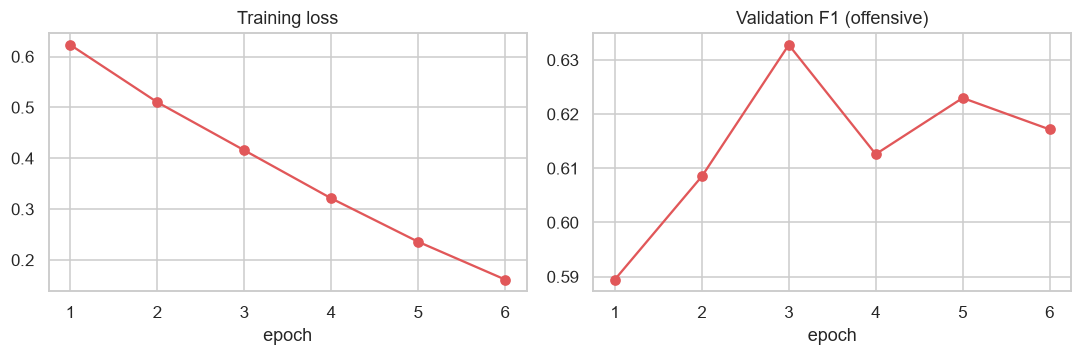

In [76]:
if "BiLSTM" in PRED:                                                  # learning curves of the LSTM
    h = pd.DataFrame(res_lstm["history"])
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
    ax[0].plot(h["epoch"], h["train_loss"], marker="o", color=MODEL_COLORS["BiLSTM"]); ax[0].set_title("Training loss")
    ax[1].plot(h["epoch"], h["f1"], marker="o", color=MODEL_COLORS["BiLSTM"]); ax[1].set_title("Validation F1 (offensive)")
    for a in ax: a.set_xlabel("epoch")
    fig.tight_layout(); savefig(fig, P.figures / "bilstm_learning_curves.png"); plt.show()

**Reading.** The loss should fall steadily; the validation F1 should rise then flatten or drop. A growing gap (loss still falling while validation F1 drops) means **overfitting**: that is why the best epoch is kept instead of the last one.

<a id="p5-10"></a>
## 5.10 Optional advanced model · BERT / DistilBERT  (`src/bert_model.py`)
**Idea.** BERT is a **Transformer pre-trained** on huge text corpora (it already "knows" English). We **fine-tune** it on our 2-class task with a very small learning rate (2e-5), so it adapts without forgetting.
Its **self-attention** lets every word look at every other word, giving true contextual understanding ("that's sick!" vs "I feel sick").
**Choices that matter**
* **Input = the original tweet** (`text`), not the heavily cleaned one: BERT's tokenizer handles punctuation, emojis and casing, and stop-words carry context.
* **Checkpoint**: `distilbert-base-uncased` by default (about half the cost of BERT for ~97% of its quality). Alternatives in `bert_model.py`: `bert-base-uncased`, `roberta-base`, `cardiffnlp/twitter-roberta-base` (pre-trained on tweets, often best).
  Do **not** use `cardiffnlp/twitter-roberta-base-offensive` as your model: it was already fine-tuned on this exact dataset (cite it only as an external reference).
* **Cost**: needs `pip install torch transformers` and internet to download the checkpoint. A GPU is strongly advised (free on Google Colab); on CPU expect 30–60 min.
* Max length **64 tokens** (tweets are short), 3 epochs, batch 32, warm-up then linear decay, gradient clipping, class-weighted loss, best epoch on validation F1.
* The best-epoch model, its tokenizer and its config are **saved** in `models/bert/` so that Part 6 can score it on the test set without retraining.

In [77]:
if _enabled(RUN_BERT):
    try:
        res_bert = bert_model.train_bert(train[RAW].tolist(), y_train, val[RAW].tolist(), y_val)   # prints one line per epoch
        register("BERT", res_bert["pred"], res_bert["scores"], "optional",
                 {"checkpoint": res_bert["cfg"]["model_name"], "best_epoch": res_bert["best_epoch"],
                  "lr": res_bert["cfg"]["lr"], "epochs": res_bert["cfg"]["epochs"]})
        display(pd.DataFrame(res_bert["history"]).round(4))
        try:                                                           # NEW: keep the best-epoch model for Part 6
            bert_model.save_bert(res_bert, MODEL_DIR / "bert")
            print("BERT saved ->", (MODEL_DIR / "bert").relative_to(P.root))
        except Exception as err_save:
            print(f"BERT trained but could NOT be saved ({type(err_save).__name__}: {err_save}) -> Part 6 will not find it.")
    except Exception as err:                                           # no internet, missing package, out of memory...
        print(f"BERT could not run ({type(err).__name__}: {err})")
        print("Check: pip install torch transformers | internet access to download the model | reduce batch_size if out of memory.")
else:
    print("BERT skipped (needs torch + GPU in 'auto' mode). Set RUN_BERT = True, or run this notebook on Google Colab (GPU runtime).")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Training device: cuda
GPU: NVIDIA GeForce RTX 3050 6GB Laptop GPU
Class weights: [0.7470846 1.511799 ]
Mixed precision: FP16 enabled
Epoch 1/3 | Loss: 0.5352 | Val F1: 0.7150 | Precision: 0.665 | Recall: 0.773 | LR: 0.000015
Epoch 2/3 | Loss: 0.4077 | Val F1: 0.7258 | Precision: 0.682 | Recall: 0.776 | LR: 0.000007
Epoch 3/3 | Loss: 0.3345 | Val F1: 0.7338 | Precision: 0.676 | Recall: 0.802 | LR: 0.000000

Training completed.
Best epoch: 3
Best validation F1: 0.7338


,epoch,train_loss,accuracy,precision,recall,f1
0,1,0.5352,0.7863,0.6648,0.7734,0.7150
1,2,0.4077,0.7968,0.6820,0.7756,0.7258
2,3,0.3345,0.7983,0.6765,0.8017,0.7338


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

BERT saved -> models\bert


**Reading.** On this task a fine-tuned Transformer usually beats the TF-IDF models by several F1 points, mostly through **higher recall** at similar precision, because it understands context and handles unusual spellings. If the history shows the best epoch is the last one, more epochs might still help; if the F1 drops after epoch 1–2, the model is overfitting.
Remember the epoch was selected on validation, so its score is slightly optimistic, like every other tuned model here.

<a id="p5-11"></a>
## 5.11 Comparison of all models
Everything below is built from the `PRED` registry: it automatically includes whichever models actually ran. **Required** models are labelled `required`, the others `optional`.

In [78]:
rows = []
for name, d in PRED.items():
    m = compute_metrics(y_val, d["y_pred"])                                   # shared metric function (offensive = 1)
    ap = average_precision_score(y_val, d["scores"]) if d["scores"] is not None else np.nan   # threshold-free quality
    rows.append({"Model": name, "Group": d["group"], "Accuracy": m["accuracy"], "Precision": m["precision"],
                 "Recall": m["recall"], "F1 (offensive)": m["f1"], "AP": ap})
results = (pd.DataFrame(rows).round(4).sort_values("F1 (offensive)", ascending=False).reset_index(drop=True))
display(results)
print(f"{len(results)} models compared | required: {(results.Group == 'required').sum()} | optional: {(results.Group == 'optional').sum()}")

,Model,Group,Accuracy,Precision,Recall,F1 (offensive),AP
0,BERT,optional,0.7983,0.6765,0.8017,0.7338,0.7943
1,BiLSTM,optional,0.7107,0.5651,0.7190,0.6328,0.7031
2,Random Forest,required,0.7719,0.7163,0.5664,0.6326,0.7112
3,Logistic Regression,required,0.7402,0.6247,0.6275,0.6261,0.7144
4,Voting ensemble,optional,0.7424,0.6305,0.6209,0.6257,NaN
5,SGD (modified Huber),optional,0.7409,0.6278,0.6209,0.6243,0.7079
6,SVM (LinearSVC),required,0.7417,0.6303,0.6166,0.6233,0.7113
7,Naive Bayes,required,0.7047,0.5749,0.5686,0.5717,0.6504
8,Complement NB,optional,0.7047,0.5749,0.5686,0.5717,0.6504
9,KNN,required,0.6654,0.5185,0.4880,0.5028,0.5556


10 models compared | required: 5 | optional: 5


**Reading.** Sorted by F1 of the offensive class. **AP** (average precision) ranks models without depending on the 0.5 decision threshold: if two models have the same F1 but different AP, the one with the higher AP is the better *ranker* (a threshold adjustment could improve it).
Compare precision and recall per model: recall above precision = the model flags generously; the opposite = more cautious. Gaps of about one F1 point are within the noise of a 1,324-tweet validation set (see section 12).

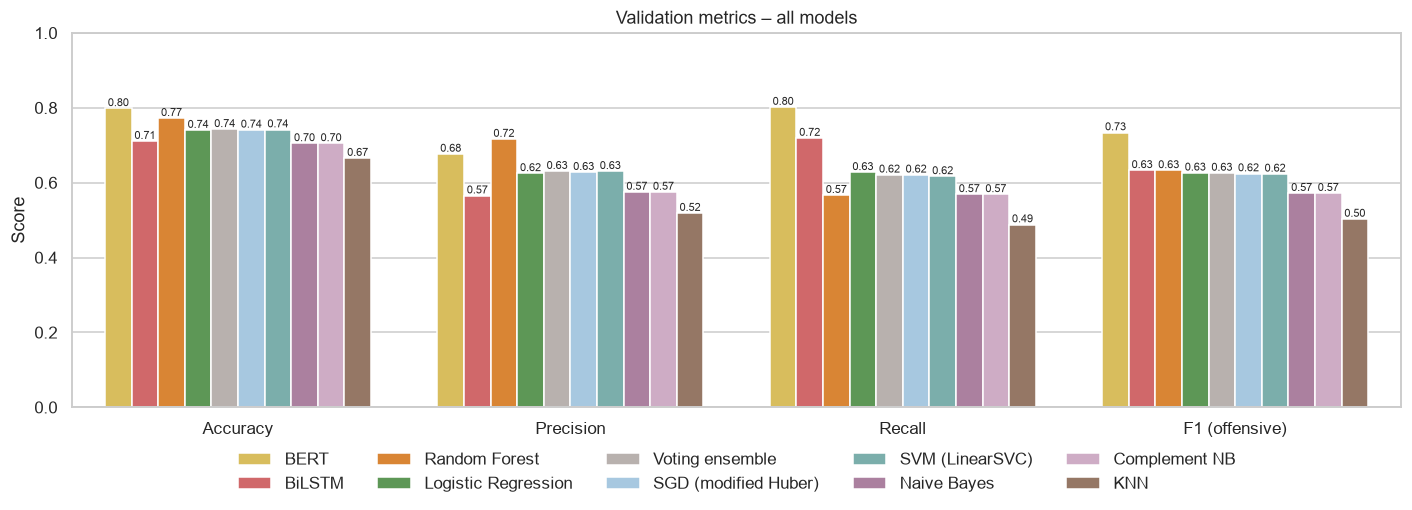

In [79]:
metrics = ["Accuracy", "Precision", "Recall", "F1 (offensive)"]
long = results.melt(id_vars="Model", value_vars=metrics, var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.barplot(data=long, x="Metric", y="Score", hue="Model", hue_order=list(results["Model"]),   # same order as the table
            palette=MODEL_COLORS, ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)                                                    # value on each bar
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_title("Validation metrics – all models")
ax.legend(title="", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout(); savefig(fig, P.figures / "metrics_all_models.png"); plt.show()

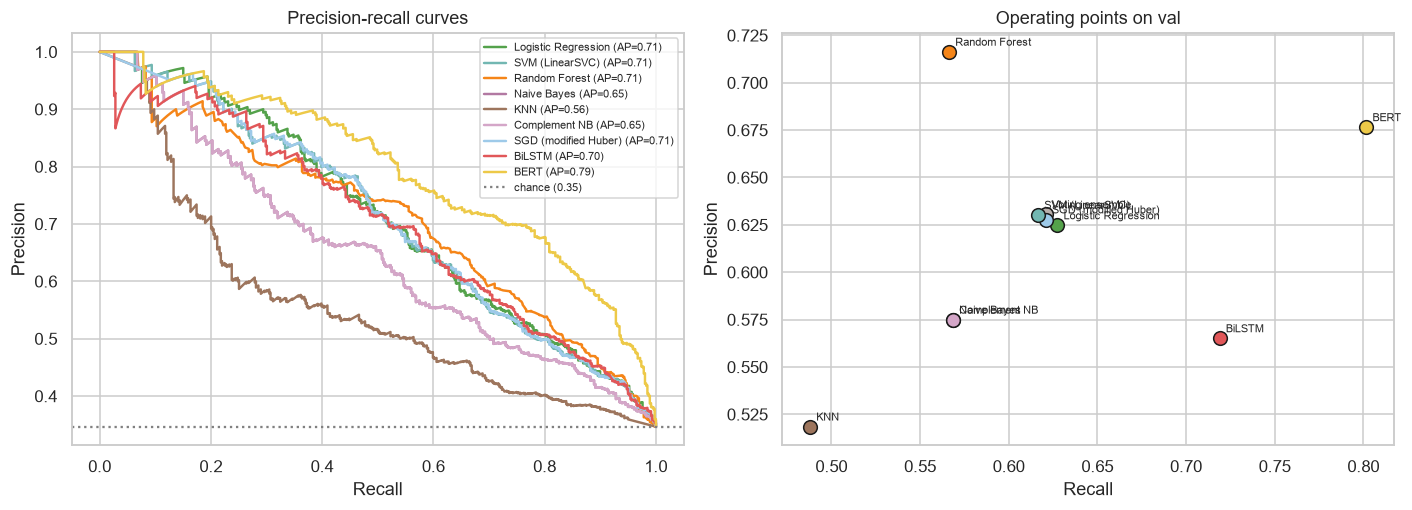

In [80]:
# Left: precision-recall CURVES (every possible threshold). Right: the operating point each model actually uses (threshold 0.5 / 0).
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))
for name, d in PRED.items():
    if d["scores"] is not None:                                               # hard-voting has no scores -> no curve
        p, r, _ = precision_recall_curve(y_val, d["scores"])
        a1.plot(r, p, color=MODEL_COLORS[name], lw=1.6, label=f"{name} (AP={average_precision_score(y_val, d['scores']):.2f})")
a1.axhline(y_val.mean(), ls=":", color="grey", label=f"chance ({y_val.mean():.2f})")   # a random classifier's precision
a1.set_xlabel("Recall"); a1.set_ylabel("Precision"); a1.set_title("Precision-recall curves"); a1.legend(fontsize=7)
for _, row in results.iterrows():
    a2.scatter(row["Recall"], row["Precision"], s=80, color=MODEL_COLORS[row["Model"]], edgecolor="k", zorder=3)
    a2.annotate(row["Model"], (row["Recall"], row["Precision"]), fontsize=7, xytext=(4, 4), textcoords="offset points")
a2.set_xlabel("Recall"); a2.set_ylabel("Precision"); a2.set_title("Operating points on val")
fig.tight_layout(); savefig(fig, P.figures / "pr_curves_all_models.png"); plt.show()

**Reading.** A curve that is **higher and to the right** is better. Curves that nearly overlap (typically the linear models) are statistically indistinguishable; a curve far below (KNN) is clearly worse at every threshold.
On the right, each dot is where the model actually operates: moving along a model's own curve (changing its decision threshold) trades precision for recall.

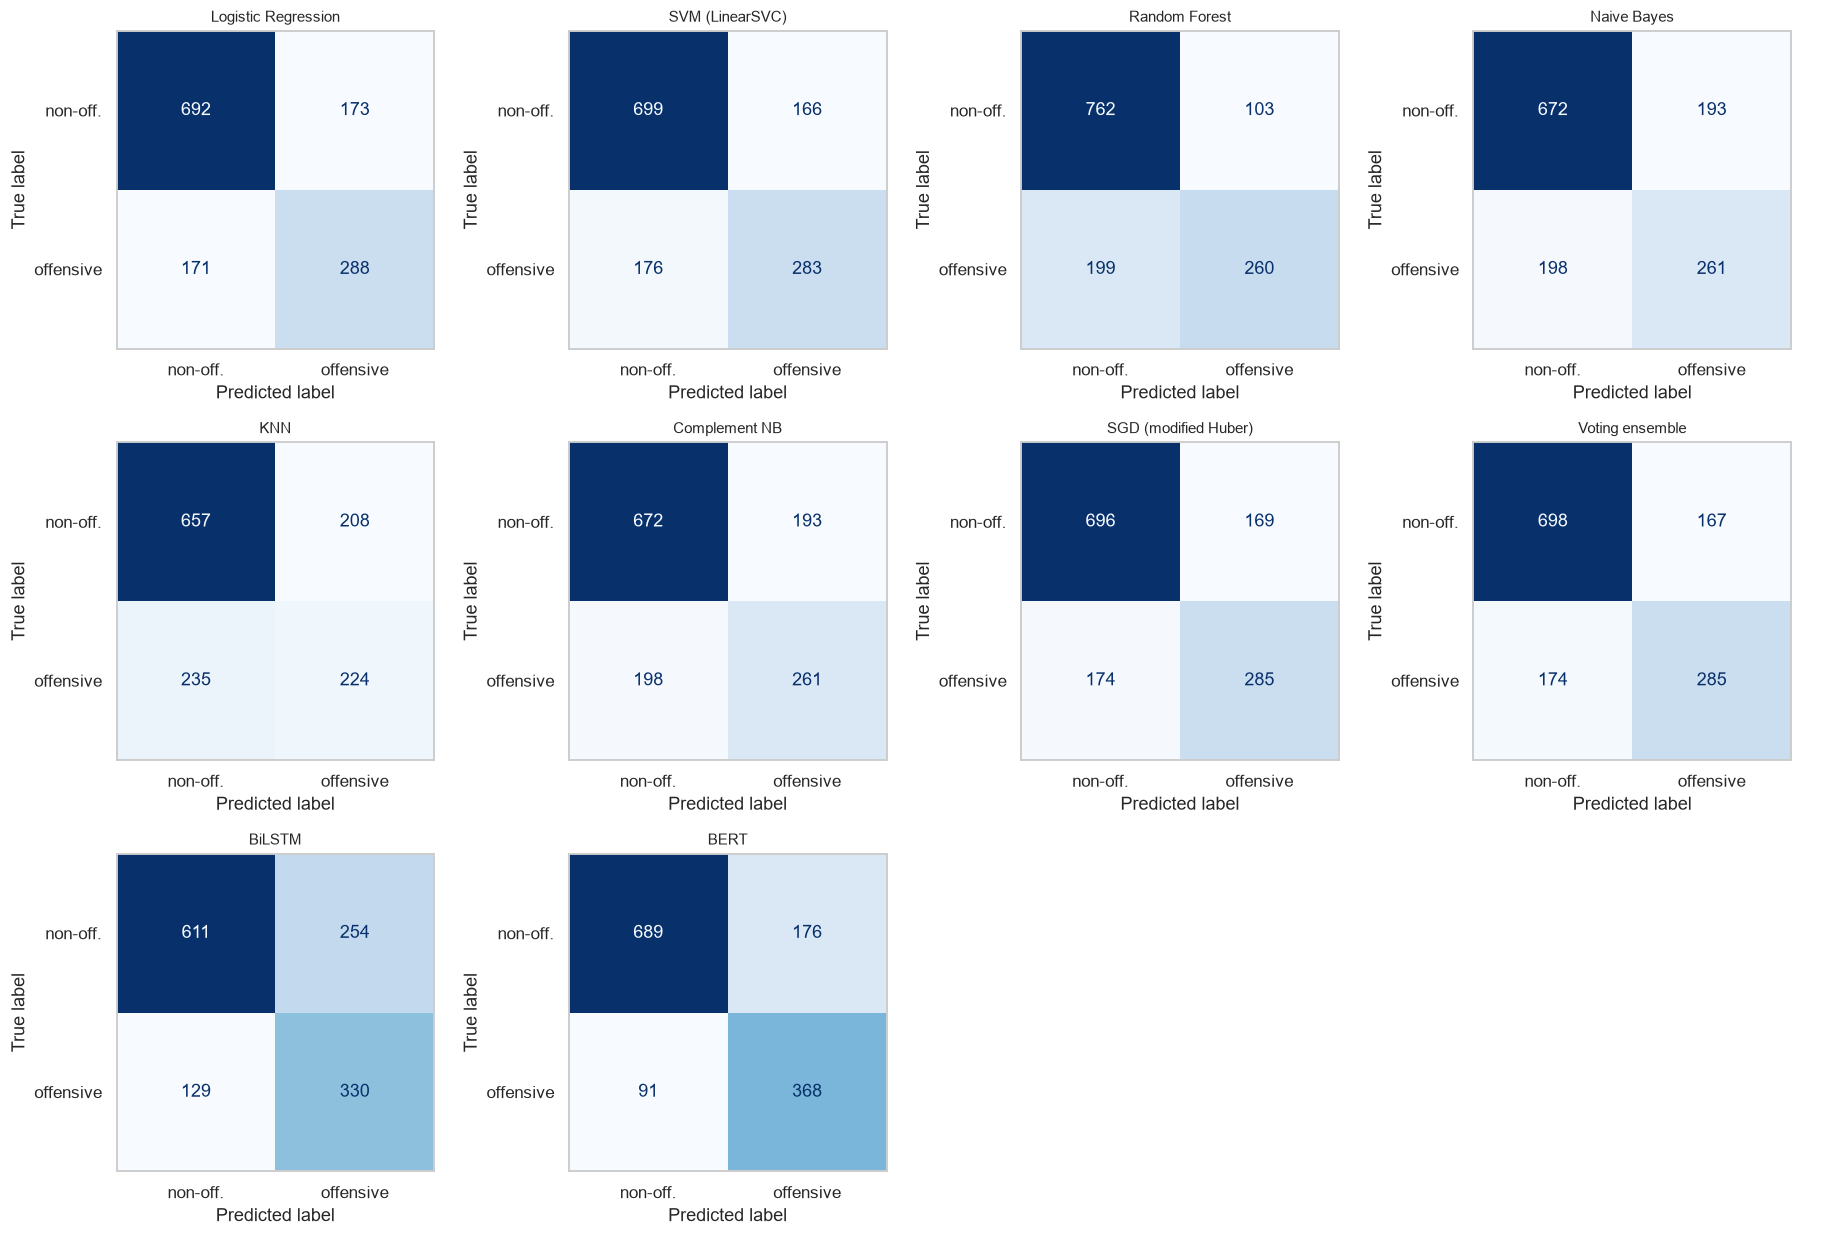

In [81]:
n = len(PRED); cols = 4; rows_ = int(np.ceil(n / cols))                      # grid that fits any number of models
fig, axes = plt.subplots(rows_, cols, figsize=(4.2 * cols, 3.8 * rows_))
for ax, (name, d) in zip(axes.ravel(), PRED.items()):
    ConfusionMatrixDisplay(get_confusion_matrix(y_val, d["y_pred"]),
                           display_labels=["non-off.", "offensive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10); ax.grid(False)
for ax in axes.ravel()[n:]:
    ax.axis("off")                                                           # hide unused panels
fig.tight_layout(); savefig(fig, P.figures / "confusion_all_models.png"); plt.show()

**Reading.** In each matrix, the **bottom-left** cell counts offensive tweets that were missed (false negatives) and the **top-right** cell counts non-offensive tweets wrongly flagged (false positives). The diagonal is correct predictions.

<a id="p5-12"></a>
## 5.12 Robustness: 5-fold cross-validation (classical models)
The validation score comes from **one** split of 1,324 tweets, so small gaps can be luck. We re-train each classical model (with its tuned hyperparameters) on 5 different train/validation splits **of the training set** and report the **mean ± standard deviation** of F1.
Neural models are excluded (too slow). Small caveat: the TF-IDF was fitted on the whole train set, so IDF weights saw the held-out folds (a minor, standard simplification); KNN is oversampled **inside** each fold.

,Model,F1 mean,F1 std,folds
0,Logistic Regression,0.6188,0.0132,"[0.628, 0.595, 0.634, 0.619, 0.618]"
1,Voting ensemble,0.6169,0.0141,"[0.635, 0.594, 0.628, 0.616, 0.612]"
2,SVM (LinearSVC),0.6149,0.0144,"[0.636, 0.593, 0.624, 0.613, 0.608]"
3,Random Forest,0.5926,0.0109,"[0.604, 0.572, 0.594, 0.595, 0.598]"
4,Naive Bayes,0.5809,0.0089,"[0.595, 0.572, 0.574, 0.576, 0.588]"
5,KNN,0.4918,0.0136,"[0.501, 0.469, 0.487, 0.51, 0.492]"


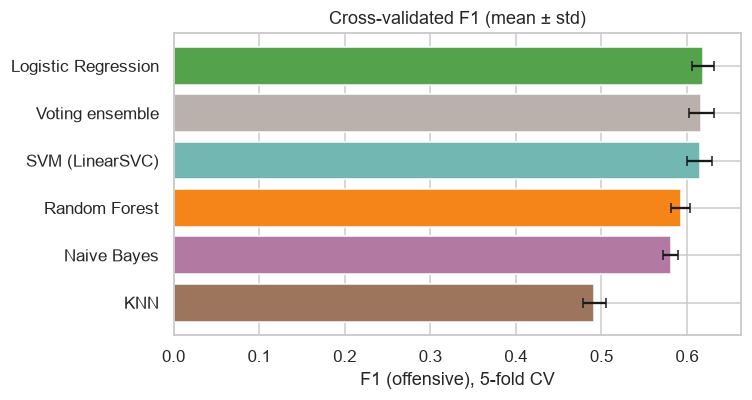

In [82]:
if RUN_CV:
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)      # folds keep the 1/3 offensive ratio
    # Factories rebuilding each model with its tuned parameters (a fresh model per fold)
    factories = {
        logistic_regression.NAME: lambda X, y: logistic_regression.train(X, y, C=best_lr_C),
        svm.NAME:                 lambda X, y: svm.train(X, y, C=best_svm_C),
        random_forest.NAME:       lambda X, y: random_forest.train(X, y, **best_rf_params),
        naive_bayes.NAME:         lambda X, y: naive_bayes.train(X, y, alpha=best_nb_alpha),
        knn.NAME:                 lambda X, y: knn.train(X, y, **best_knn_params),   # oversamples inside train()
    }
    if RUN_EXTRA:
        factories[extra_models.NAME_VOTE] = lambda X, y: extra_models.train_voting(X, y, best_lr_C, best_svm_C, best_nb_alpha)
    cv_rows = []
    for name, make in factories.items():
        f1s = []
        for tr, te in skf.split(X_train, y_train):                          # 5 different splits
            model = make(X_train[tr], y_train[tr])                          # train on 4 folds
            f1s.append(compute_metrics(y_train[te], model.predict(X_train[te]))["f1"])   # score on the held-out fold
        cv_rows.append({"Model": name, "F1 mean": np.mean(f1s), "F1 std": np.std(f1s), "folds": np.round(f1s, 3).tolist()})
    cv = pd.DataFrame(cv_rows).sort_values("F1 mean", ascending=False).reset_index(drop=True)
    display(cv.round(4))
    fig, ax = plt.subplots(figsize=(7, 3.8))
    ax.barh(cv["Model"][::-1], cv["F1 mean"][::-1], xerr=cv["F1 std"][::-1],           # bar = mean, whisker = std
            color=[MODEL_COLORS[m] for m in cv["Model"][::-1]], capsize=3)
    ax.set_xlabel("F1 (offensive), 5-fold CV"); ax.set_title("Cross-validated F1 (mean ± std)")
    fig.tight_layout(); savefig(fig, P.figures / "cv_f1_models.png"); plt.show()
else:
    cv = None; print("RUN_CV = False -> skipped.")

**Reading.** If two models' whiskers overlap, their difference is **not reliable**: treat them as tied and choose on secondary criteria (simplicity, speed, interpretability). A model clearly separated from the rest (typically KNN at the bottom) is genuinely different.

<a id="p5-13"></a>
## 5.13 What the linear models learned
In a linear model each TF-IDF feature has one weight: large **positive** weights push a tweet towards **offensive**, large **negative** ones towards **non-offensive**. Reading them checks that the models rely on meaningful words (not on artefacts).

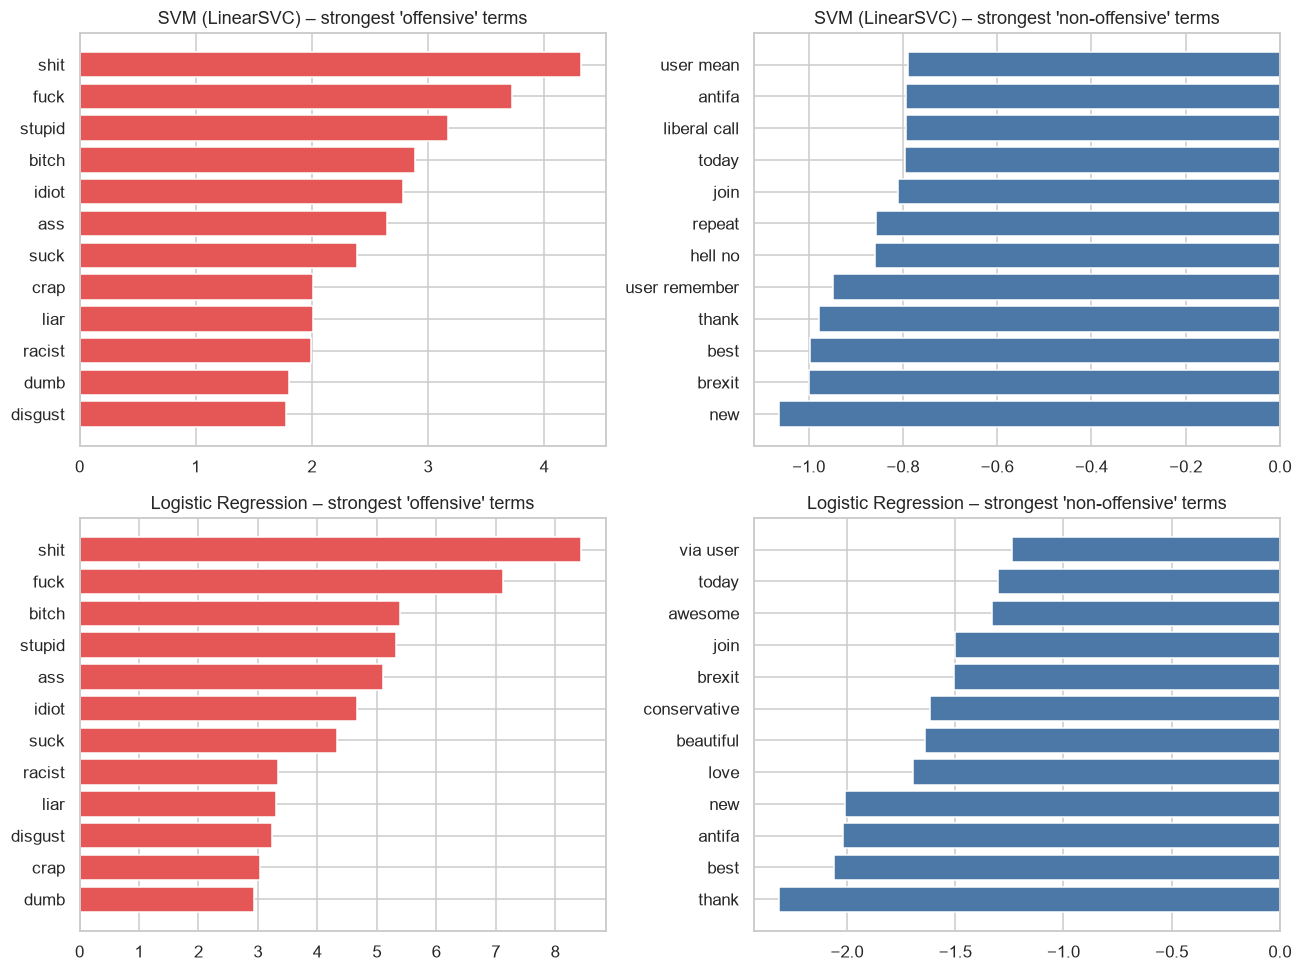

Top-30 'offensive' terms shared by SVM and Logistic Regression: 27 / 30


In [83]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for row, name in enumerate([svm.NAME, logistic_regression.NAME]):
    off, non = top_linear_terms(MODELS[name], feature_names, n=12)           # strongest terms of each class
    axes[row, 0].barh(off["term"][::-1], off["weight"][::-1], color=COLORS["offensive"])
    axes[row, 0].set_title(f"{name} – strongest 'offensive' terms")
    axes[row, 1].barh(non["term"], non["weight"], color=COLORS["non-offensive"])
    axes[row, 1].set_title(f"{name} – strongest 'non-offensive' terms")
fig.tight_layout(); savefig(fig, P.figures / "linear_models_top_terms.png"); plt.show()

# How much do the two linear models agree? (overlap of their top-30 offensive terms)
t_svm = set(top_linear_terms(MODELS[svm.NAME], feature_names, 30)[0]["term"])
t_lr  = set(top_linear_terms(MODELS[logistic_regression.NAME], feature_names, 30)[0]["term"])
print(f"Top-30 'offensive' terms shared by SVM and Logistic Regression: {len(t_svm & t_lr)} / 30")

**Reading.** Vulgar or insulting words are expected on the offensive side. If **topic words** (political groups, events…) appear, the models partly learn *what people talk about* rather than *how they talk*: a limitation to mention in the project conclusion.
Also check that placeholders left by the cleaning (e.g. `user`) do not dominate either side. A high overlap between the two lists means both models learned essentially the same thing, which explains their similar scores.

<a id="p5-14"></a>
## 5.14 Conclusions
Generated from the results above, so it stays correct when the notebook is re-run. The final choice of the best model and its justification belong to the evaluation part (Part 6); here we only report what the **validation** results show.
Since hyperparameters (and the best epoch for the neural models) were also selected on validation, these scores are slightly optimistic compared with the test set.

In [84]:
for rank, row in results.iterrows():
    tendency = ("flags offensive tweets generously (recall >= precision)" if row["Recall"] >= row["Precision"]
                else "is more cautious: fewer false alarms, but more offensive tweets missed")
    print(f"{rank + 1:>2}. {row['Model']:<22} [{row['Group']:<8}] F1 = {row['F1 (offensive)']:.3f} "
          f"(P = {row['Precision']:.3f}, R = {row['Recall']:.3f}, AP = {row['AP']:.3f}) -> {tendency}.")

top, bottom = results.iloc[0], results.iloc[-1]
print(f"\nStrongest on val : {top['Model']} (F1 = {top['F1 (offensive)']:.3f})")
print(f"Weakest on val   : {bottom['Model']} (F1 = {bottom['F1 (offensive)']:.3f})")
gap = results.iloc[0]["F1 (offensive)"] - results.iloc[1]["F1 (offensive)"]
print(f"Gap 1st vs 2nd   : {gap:.3f} F1 points" + ("  -> within noise: treat as tied." if gap < 0.015 else ""))

req = results[results.Group == "required"]
print(f"\nRequired models trained : {len(req)} (assignment minimum = 5) -> {'OK' if len(req) >= 5 else 'MISSING MODELS'}")
if (results.Group == "optional").any():
    best_opt = results[results.Group == "optional"].iloc[0]
    delta = best_opt["F1 (offensive)"] - req.iloc[0]["F1 (offensive)"]
    print(f"Best optional model     : {best_opt['Model']} ({delta:+.3f} F1 vs best required model)")
if cv is not None:
    print(f"Most stable in CV       : {cv.sort_values('F1 std').iloc[0]['Model']} (std = {cv['F1 std'].min():.3f})")

 1. BERT                   [optional] F1 = 0.734 (P = 0.676, R = 0.802, AP = 0.794) -> flags offensive tweets generously (recall >= precision).
 2. BiLSTM                 [optional] F1 = 0.633 (P = 0.565, R = 0.719, AP = 0.703) -> flags offensive tweets generously (recall >= precision).
 3. Random Forest          [required] F1 = 0.633 (P = 0.716, R = 0.566, AP = 0.711) -> is more cautious: fewer false alarms, but more offensive tweets missed.
 4. Logistic Regression    [required] F1 = 0.626 (P = 0.625, R = 0.627, AP = 0.714) -> flags offensive tweets generously (recall >= precision).
 5. Voting ensemble        [optional] F1 = 0.626 (P = 0.630, R = 0.621, AP = nan) -> is more cautious: fewer false alarms, but more offensive tweets missed.
 6. SGD (modified Huber)   [optional] F1 = 0.624 (P = 0.628, R = 0.621, AP = 0.708) -> is more cautious: fewer false alarms, but more offensive tweets missed.
 7. SVM (LinearSVC)        [required] F1 = 0.623 (P = 0.630, R = 0.617, AP = 0.711) -> is mor

**Reading.** Typical outcome on TweetEval *offensive*: the linear models (LogReg, SVM, SGD) lead the classical group with scores very close to each other; Random Forest and Naive Bayes follow; KNN is last; the BiLSTM is close to the linear models; a fine-tuned BERT-family model is the one most likely to stand out.
If BERT or the LSTM were skipped, say so explicitly in the report (and explain the hardware reason) rather than leaving them out silently.

<a id="p5-15"></a>
## 5.15 Saving the results
Exported for the evaluation part (Part 6), which builds the final comparison and the error analysis without retraining the comparison models. The final **classical** model is **not** saved here (Part 6 refits it on train + validation); the **BiLSTM and BERT best-epoch models are saved** in `models/` so that Part 6 can score the winner on the test set.

| Item | Location |
|---|---|
| Validation metrics of all models | `results/metrics/05_model_training/models_validation_metrics.csv` |
| Cross-validation table | `results/metrics/05_model_training/cv_f1.csv` |
| Hyperparameters chosen | `results/metrics/05_model_training/best_hyperparameters.csv` |
| Tuning tables | `results/metrics/05_model_training/<model>_tuning.csv` |
| Validation predictions (+ scores) | `results/predictions/05_model_training/val_predictions_<model>.csv` |
| Neural models (best epoch) | `models/bilstm.pt` and `models/bert/` (saved in sections 9 and 10) |
| Figures | `results/figures/05_model_training/*.png` |

In [85]:
import re
slug = lambda s: re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")           # "SVM (LinearSVC)" -> "svm_linearsvc"

results.to_csv(P.metrics / "models_validation_metrics.csv", index=False)     # main comparison table
if cv is not None:
    cv.to_csv(P.metrics / "cv_f1.csv", index=False)                          # cross-validation
pd.DataFrame([{"Model": n, "Group": d["group"], "params": str(d["params"])} for n, d in PRED.items()]
             ).to_csv(P.metrics / "best_hyperparameters.csv", index=False)   # what was chosen on val

tuning = {logistic_regression.NAME: lr_grid, svm.NAME: svm_grid, random_forest.NAME: rf_grid,
          naive_bayes.NAME: nb_grid, knn.NAME: knn_grid}
if RUN_EXTRA and extra_models.NAME_CNB in PRED:
    tuning[extra_models.NAME_CNB], tuning[extra_models.NAME_SGD] = cnb_grid, sgd_grid
for name, table in tuning.items():
    table.to_csv(P.metrics / f"{slug(name)}_tuning.csv", index=False)

for name, d in PRED.items():                                                 # tweet, true label, prediction, score
    out = pd.DataFrame({"text": val[RAW], "y_true": y_val, "y_pred": d["y_pred"]})
    if d["scores"] is not None:
        out["score_offensive"] = d["scores"]
    out.to_csv(PRED_DIR / f"val_predictions_{slug(name)}.csv", index=False)

print("Saved:")
for folder in (P.metrics, PRED_DIR):
    for p in sorted(Path(folder).glob("*.csv")):
        print(" -", p.relative_to(P.root))
for p in (MODEL_DIR / "bilstm.pt", MODEL_DIR / "bert"):                      # NEW: neural models saved in sections 9 / 10
    print(" -", p.relative_to(P.root), "(found)" if p.exists() else "(not found: that model was skipped or not saved)")

Saved:
 - results\metrics\05_model_training\best_hyperparameters.csv
 - results\metrics\05_model_training\complement_nb_tuning.csv
 - results\metrics\05_model_training\cv_f1.csv
 - results\metrics\05_model_training\knn_tuning.csv
 - results\metrics\05_model_training\logistic_regression_tuning.csv
 - results\metrics\05_model_training\models_validation_metrics.csv
 - results\metrics\05_model_training\naive_bayes_tuning.csv
 - results\metrics\05_model_training\random_forest_tuning.csv
 - results\metrics\05_model_training\sgd_modified_huber_tuning.csv
 - results\metrics\05_model_training\svm_linearsvc_tuning.csv
 - results\metrics\05_model_training\svm_tuning.csv
 - results\predictions\05_model_training\val_predictions_bert.csv
 - results\predictions\05_model_training\val_predictions_bilstm.csv
 - results\predictions\05_model_training\val_predictions_complement_nb.csv
 - results\predictions\05_model_training\val_predictions_knn.csv
 - results\predictions\05_model_training\val_predictions_l

**Reading.** The list confirms every file the evaluation part (Part 6) can now load. If a model is missing from it, its section was skipped (see the switches in section 1). Part 6 needs `models/bert/` (or `models/bilstm.pt`) only when that model is the best one on validation.

---

<a id="part6"></a>
# Part 6 · Evaluation, model selection and final test


Part 5 trained the five required models (Logistic Regression, SVM, Random Forest, Naive Bayes, KNN) and the optional ones
(Complement NB, SGD, Voting, BiLSTM, BERT) and exported their **validation** predictions. This part does **not** retrain anything for the comparison. It:

1. loads the validation predictions of every model that ran in Part 5;
2. computes **accuracy, precision, recall, F1** (offensive = positive class) and shows one **confusion matrix** per model;
3. **compares** the models and **selects the best one** (criterion: F1 of the offensive class on validation);
4. runs the **final test**: the selected model is scored **once** on the test set (a classical model is first refitted on train + validation with its tuned hyperparameters; **BERT** is scored with its saved best-epoch weights);
5. **saves** the model, the metrics, the predictions and the figures.

> The test set is used exactly once, in section 5, for the selected model only.

> **Outputs of this part were cleared** because the stored ones predate the BERT and BiLSTM results of Part 5. Run Part 6 again after Part 5 to refresh all tables, figures and the test score.

## 6.1 Setup and loading the results of Part 5

In [86]:
import sys, re, ast, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import joblib
from sklearn.metrics import ConfusionMatrixDisplay

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import config
from src.utils import setup_paths, savefig
from src.features import fit_tfidf, transform_tfidf
from src.evaluation import compute_metrics, get_confusion_matrix
from src import logistic_regression, svm, random_forest, naive_bayes, knn, extra_models

P = setup_paths("06_evaluation")
M05 = P.root / "results" / "metrics" / "05_model_training"
PRED05 = P.root / "results" / "predictions" / "05_model_training"
PRED06 = P.root / "results" / "predictions" / "06_evaluation"
MODEL_DIR = P.root / "models"
for d in (P.figures, P.metrics, PRED06, MODEL_DIR):
    Path(d).mkdir(parents=True, exist_ok=True)

slug = lambda s: re.sub(r"[^a-z0-9]+", "_", s.lower()).strip("_")
SEED = config.RANDOM_STATE
for f in ("models_validation_metrics.csv", "best_hyperparameters.csv"):
    assert (M05 / f).exists(), f"{f} not found: run Part 5 first."

hp = pd.read_csv(M05 / "best_hyperparameters.csv")                    # Model, Group, params (as text)
hp["params"] = hp["params"].apply(lambda s: ast.literal_eval(s) if s != "None" else {})
PARAMS = dict(zip(hp["Model"], hp["params"]))
GROUP = dict(zip(hp["Model"], hp["Group"]))

val = pd.read_csv(P.processed / "val_final.csv", keep_default_na=False)
y_val = val["label"].to_numpy()

VAL_PRED, VAL_SCORE = {}, {}
for name in hp["Model"]:
    f = PRED05 / f"val_predictions_{slug(name)}.csv"
    if f.exists():
        d = pd.read_csv(f, keep_default_na=False)
        assert (d["y_true"].to_numpy() == y_val).all(), f"{name}: predictions do not match val_final.csv"
        VAL_PRED[name] = d["y_pred"].to_numpy()
        VAL_SCORE[name] = d["score_offensive"].to_numpy() if "score_offensive" in d else None
print(f"{len(VAL_PRED)} models loaded:", list(VAL_PRED))

10 models loaded: ['Logistic Regression', 'SVM (LinearSVC)', 'Random Forest', 'Naive Bayes', 'KNN', 'Complement NB', 'SGD (modified Huber)', 'Voting ensemble', 'BiLSTM', 'BERT']


## 6.2 Metrics per model (validation set)
Recomputed from the saved predictions with the project's shared `compute_metrics`, so every model is scored by the same code.
**Offensive = positive class.** F1 is the main criterion because accuracy is inflated by the majority class (about 2 tweets in 3 are non-offensive).

In [87]:
rows = []
for name, pred in VAL_PRED.items():
    m = compute_metrics(y_val, pred)
    rows.append({"Model": name, "Group": GROUP[name], "Accuracy": m["accuracy"], "Precision": m["precision"],
                 "Recall": m["recall"], "F1": m["f1"]})
results = pd.DataFrame(rows).round(4).sort_values("F1", ascending=False).reset_index(drop=True)
display(results)

,Model,Group,Accuracy,Precision,Recall,F1
0,BERT,optional,0.7983,0.6765,0.8017,0.7338
1,BiLSTM,optional,0.7107,0.5651,0.7190,0.6328
2,Random Forest,required,0.7719,0.7163,0.5664,0.6326
3,Logistic Regression,required,0.7402,0.6247,0.6275,0.6261
4,Voting ensemble,optional,0.7424,0.6305,0.6209,0.6257
5,SGD (modified Huber),optional,0.7409,0.6278,0.6209,0.6243
6,SVM (LinearSVC),required,0.7417,0.6303,0.6166,0.6233
7,Naive Bayes,required,0.7047,0.5749,0.5686,0.5717
8,Complement NB,optional,0.7047,0.5749,0.5686,0.5717
9,KNN,required,0.6654,0.5185,0.4880,0.5028


## 6.3 Confusion matrices
Bottom-left = offensive tweets **missed** (false negatives); top-right = non-offensive tweets **wrongly flagged** (false positives).

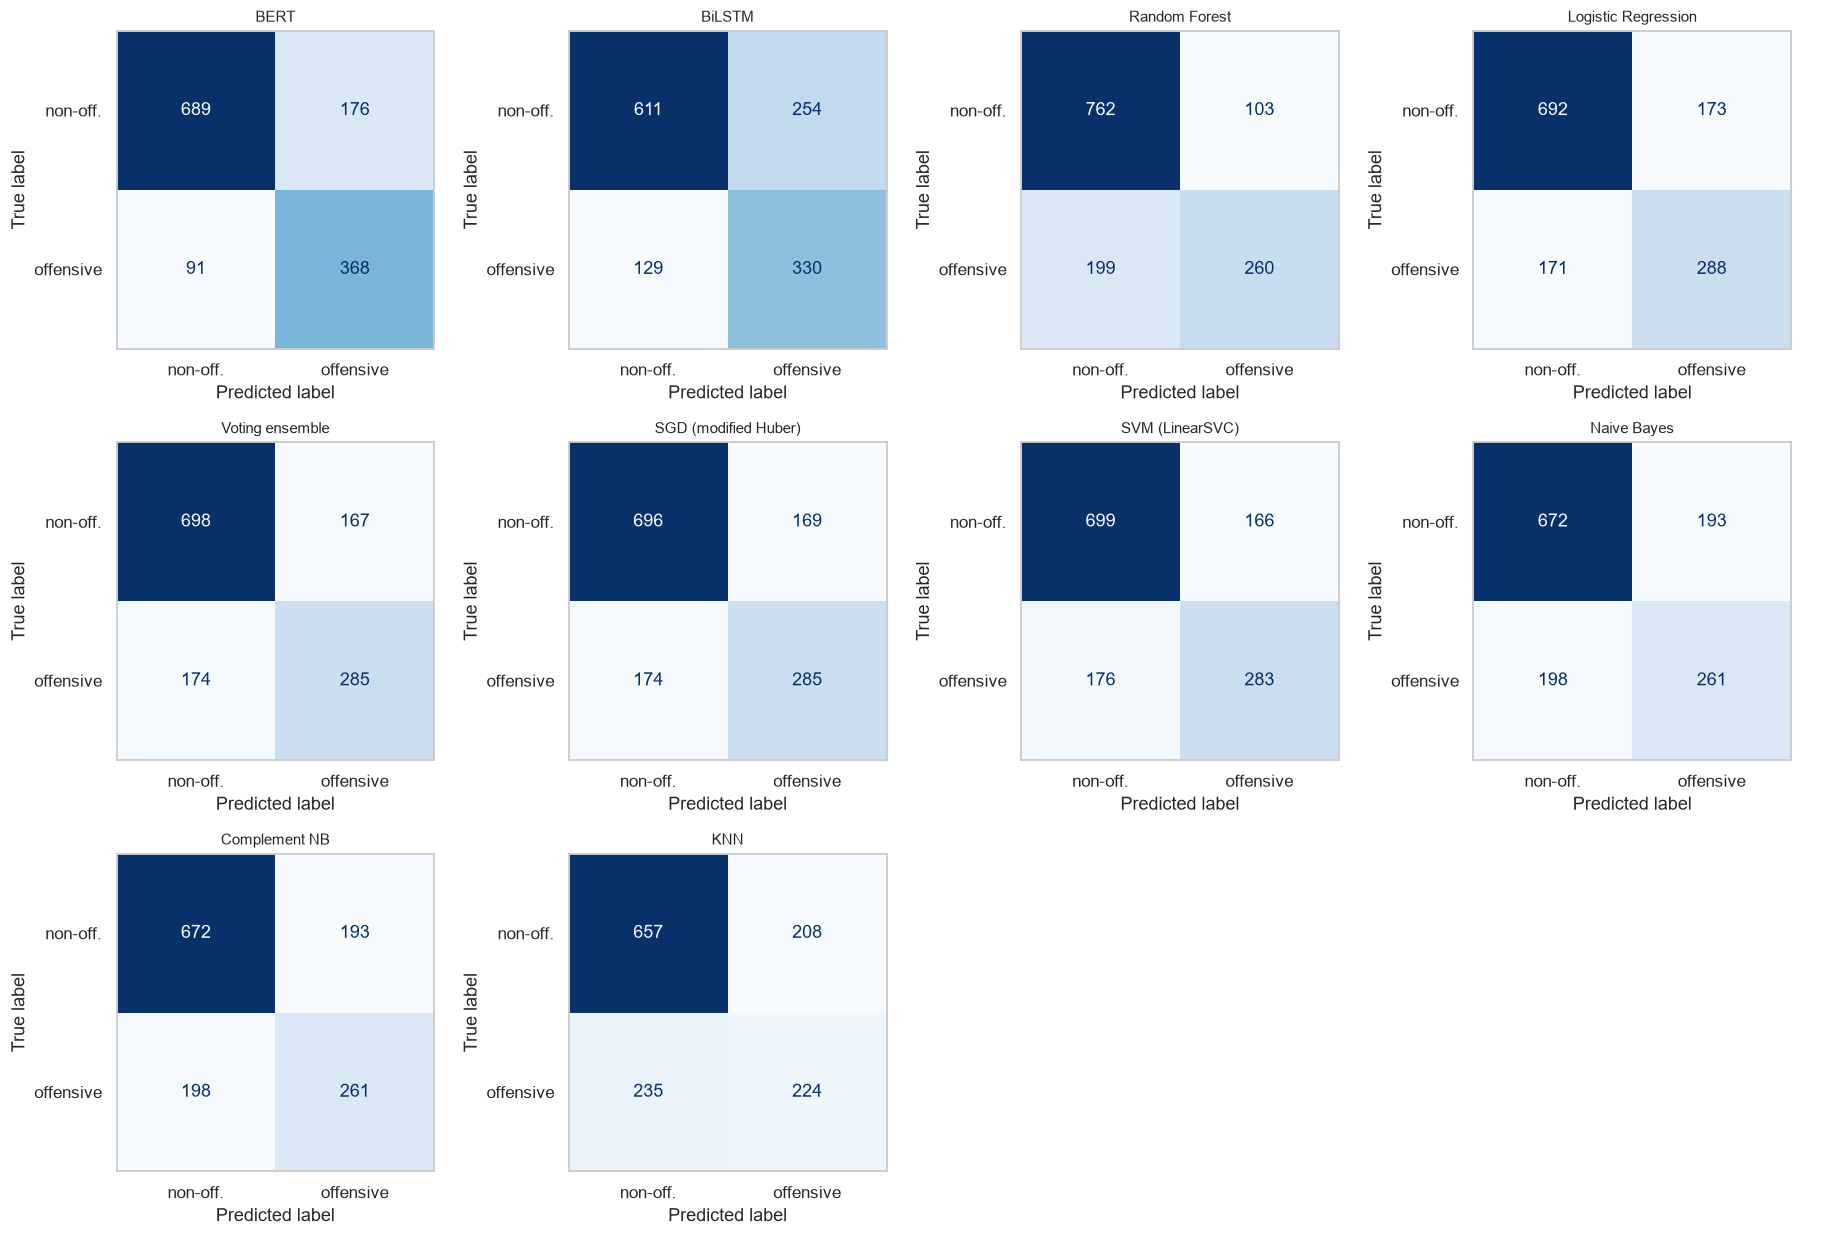

In [88]:
n = len(VAL_PRED); cols = 4; nrows = int(np.ceil(n / cols))
fig, axes = plt.subplots(nrows, cols, figsize=(4.2 * cols, 3.8 * nrows))
for ax, name in zip(np.ravel(axes), results["Model"]):
    ConfusionMatrixDisplay(get_confusion_matrix(y_val, VAL_PRED[name]),
                           display_labels=["non-off.", "offensive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name, fontsize=10); ax.grid(False)
for ax in np.ravel(axes)[n:]:
    ax.axis("off")
fig.tight_layout(); savefig(fig, P.figures / "confusion_matrices_validation.png"); plt.show()

## 6.4 Comparison and selection of the best model

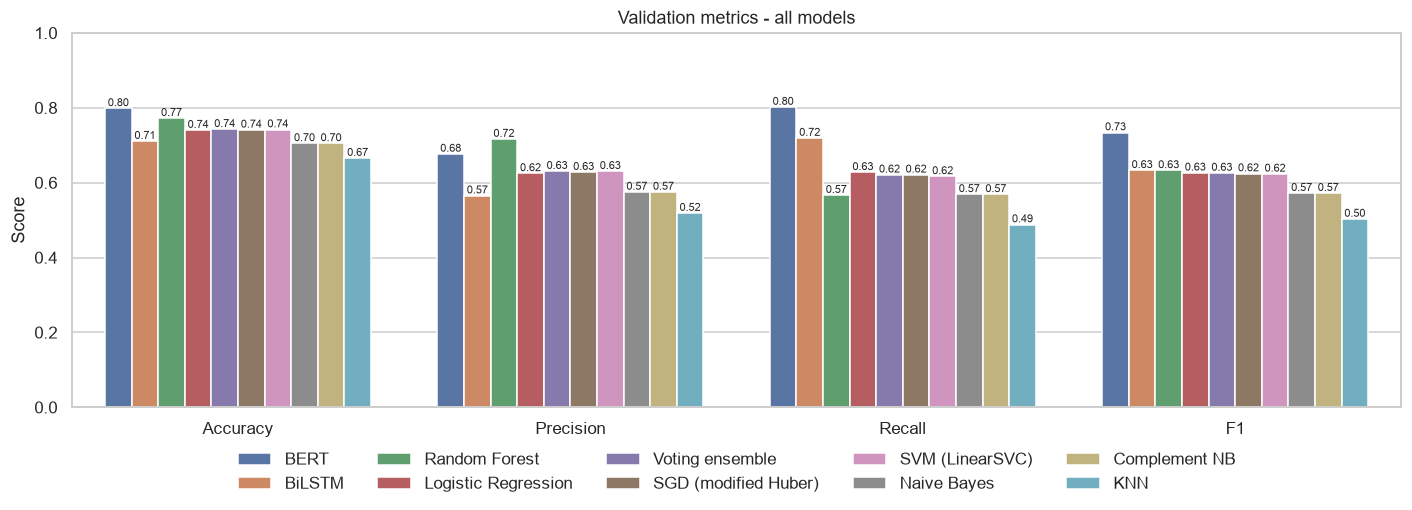

Best on validation : BERT  (F1 = 0.7338, P = 0.6765, R = 0.8017)

Selected for the final test: BERT  with {'checkpoint': 'distilbert-base-uncased', 'best_epoch': 3, 'lr': 2e-05, 'epochs': 3}


In [89]:
long = results.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1"], var_name="Metric", value_name="Score")
fig, ax = plt.subplots(figsize=(13, 4.8))
sns.barplot(data=long, x="Metric", y="Score", hue="Model", hue_order=list(results["Model"]), ax=ax)
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", fontsize=7)
ax.set_ylim(0, 1); ax.set_xlabel(""); ax.set_title("Validation metrics - all models")
ax.legend(title="", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
fig.tight_layout(); savefig(fig, P.figures / "comparison_validation.png"); plt.show()

best = results.iloc[0]
tied = results[results["F1"] >= best["F1"] - 0.005]["Model"].tolist()
print(f"Best on validation : {best['Model']}  (F1 = {best['F1']:.4f}, P = {best['Precision']:.4f}, R = {best['Recall']:.4f})")
if len(tied) > 1:
    print("Within 0.005 F1 (statistically tied on 1,324 tweets):", tied)
    print("-> prefer the simplest / fastest of these if you want to justify a different choice (see CV table of Part 5).")

# Neural models cannot be refitted here; BERT can be scored on test from its saved best-epoch weights (models/bert/).
NEURAL = ["BiLSTM", "BERT"]
SCORABLE_NEURAL = ["BERT"]                      # BiLSTM: compared on validation only (no loader implemented here)
CLASSICAL = [m for m in results["Model"] if m not in NEURAL]

def _available(name):
    return name in SCORABLE_NEURAL and (MODEL_DIR / "bert").exists() or name in CLASSICAL

SELECTED = best["Model"]                        # best validation F1 among ALL models that ran
if not _available(SELECTED):
    fallback = results[results["Model"].isin(CLASSICAL)].iloc[0]["Model"]
    print(f"NOTE: {SELECTED} cannot be scored on test here (not saved / no loader) -> the final test uses the best classical model: {fallback}.")
    SELECTED = fallback
print(f"\nSelected for the final test: {SELECTED}  with {PARAMS[SELECTED]}")


**Reading.** Differences of about one F1 point are within the noise of a single validation split. The choice should be justified with F1, the
precision/recall balance (for moderation, missing offensive tweets is usually worse than a few false alarms) and the simplicity of the model.

## 6.5 Final test and saving
The selected model is scored **once** on the test set:

* a **classical** model is **refitted on train + validation** (TF-IDF included, still no test data) with the hyperparameters chosen in Part 5;
* **BERT** is loaded from `models/bert/` (best epoch chosen on validation, trained on train only) and is **not** refitted. Before scoring, its predictions on the validation set are recomputed and compared with the ones saved in Part 5, which proves that the model, the tokenizer and the input text are the right ones.

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Agreement with the validation predictions of Part 5: 100.00 %


,Model,Accuracy,Precision,Recall,F1
0,BERT,0.8302,0.6822,0.7333,0.7068


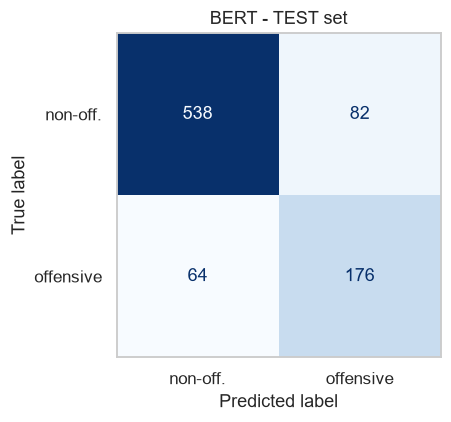

Validation F1 = 0.7338  ->  Test F1 = 0.7068  (a small drop is normal: hyperparameters / the best epoch were chosen on validation)


In [90]:
test_path = P.processed / "test_final.csv"
assert test_path.exists(), "test_final.csv not found: run Part 3 first."
train = pd.read_csv(P.processed / "train_final.csv", keep_default_na=False)
test  = pd.read_csv(test_path, keep_default_na=False)
y_test = test["label"].to_numpy()
TEXT_COL = "text" if "text" in test.columns else "text_clean"      # BERT reads the ORIGINAL tweet

def build_final(name, X, y):
    p = PARAMS[name]
    if name == "Logistic Regression": return logistic_regression.train(X, y, **p)
    if name == "SVM (LinearSVC)":     return svm.train(X, y, **p)
    if name == "Random Forest":       return random_forest.train(X, y, **p)
    if name == "Naive Bayes":         return naive_bayes.train(X, y, **p)
    if name == "KNN":                 return knn.train(X, y, **p)
    if name == "Complement NB":       return extra_models.train_complement_nb(X, y, **p)
    if name == "SGD (modified Huber)":return extra_models.train_sgd(X, y, **p)
    if name == "Voting ensemble":
        return extra_models.train_voting(X, y, PARAMS["Logistic Regression"]["C"],
                                         PARAMS["SVM (LinearSVC)"]["C"], PARAMS["Naive Bayes"]["alpha"])
    raise ValueError(name)

final_model, vec = None, None                                      # stay None for a neural model

if SELECTED == "BERT":
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tok  = AutoTokenizer.from_pretrained(MODEL_DIR / "bert")
    bert = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR / "bert").to(device).eval()

    def bert_predict(texts, batch_size=64, max_length=64):
        """Predicted labels (0/1) for a list of raw tweets (max_length = 64 tokens, as in training)."""
        out = []
        with torch.no_grad():
            for i in range(0, len(texts), batch_size):
                enc = tok(texts[i:i + batch_size], truncation=True, max_length=max_length,
                          padding=True, return_tensors="pt").to(device)
                out.append(bert(**enc).logits.argmax(dim=-1).cpu().numpy())
        return np.concatenate(out)

    # Sanity check on VALIDATION: must reproduce the predictions saved by Part 5 (no test data involved)
    agree = float((bert_predict(val[TEXT_COL].tolist()) == VAL_PRED["BERT"]).mean())
    print(f"Agreement with the validation predictions of Part 5: {100 * agree:.2f} %")
    if agree < 0.98:
        print("WARNING: the reloaded BERT does not reproduce the Part 5 predictions -> check max_length / checkpoint before trusting the test score.")
    y_pred_test = bert_predict(test[TEXT_COL].tolist())              # the ONE use of the test set
else:
    full = pd.concat([train, val], ignore_index=True)
    vec, X_full = fit_tfidf(full["text_clean"])                      # vocabulary + IDF from train + val only
    X_test = transform_tfidf(vec, test["text_clean"])
    y_full = full["label"].to_numpy()
    final_model = build_final(SELECTED, X_full, y_full)
    y_pred_test = final_model.predict(X_test)                        # the ONE use of the test set

mt = compute_metrics(y_test, y_pred_test)
test_table = pd.DataFrame([{"Model": SELECTED, "Accuracy": mt["accuracy"], "Precision": mt["precision"],
                            "Recall": mt["recall"], "F1": mt["f1"]}]).round(4)
display(test_table)

fig, ax = plt.subplots(figsize=(4.6, 4))
ConfusionMatrixDisplay(get_confusion_matrix(y_test, y_pred_test),
                       display_labels=["non-off.", "offensive"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"{SELECTED} - TEST set"); ax.grid(False)
fig.tight_layout(); savefig(fig, P.figures / "confusion_matrix_test.png"); plt.show()

v = results[results["Model"] == SELECTED].iloc[0]
print(f"Validation F1 = {v['F1']:.4f}  ->  Test F1 = {mt['f1']:.4f}  (a small drop is normal: hyperparameters / the best epoch were chosen on validation)")


In [91]:
# ---- saving ------------------------------------------------------------------------
import json
saved = []
if final_model is not None:                                         # classical model: vectoriser + classifier in one file
    joblib.dump({"vectorizer": vec, "model": final_model, "name": SELECTED, "params": PARAMS[SELECTED]},
                MODEL_DIR / "best_model.joblib")                    # load later: bundle = joblib.load(...)
    saved.append(MODEL_DIR / "best_model.joblib")
info = {"name": SELECTED, "type": "neural" if SELECTED in NEURAL else "classical",
        "location": "models/bert" if SELECTED == "BERT" else "models/best_model.joblib", "params": PARAMS[SELECTED]}
with open(MODEL_DIR / "best_model_info.json", "w", encoding="utf-8") as fh:
    json.dump(info, fh, indent=2, default=str)                      # tells the demo (Part 7) which model to load
saved.append(MODEL_DIR / "best_model_info.json")

results.to_csv(P.metrics / "validation_comparison.csv", index=False)
test_table.to_csv(P.metrics / "final_test_metrics.csv", index=False)
pd.DataFrame({"text": test[TEXT_COL], "y_true": y_test, "y_pred": y_pred_test}).to_csv(PRED06 / "test_predictions_best_model.csv", index=False)
print("Saved:")
for p in saved + [P.metrics / "validation_comparison.csv", P.metrics / "final_test_metrics.csv", PRED06 / "test_predictions_best_model.csv"]:
    print(" -", Path(p).relative_to(P.root))


Saved:
 - models\best_model_info.json
 - results\metrics\06_evaluation\validation_comparison.csv
 - results\metrics\06_evaluation\final_test_metrics.csv
 - results\predictions\06_evaluation\test_predictions_best_model.csv


**Reading.** For a classical model, `best_model.joblib` contains the TF-IDF vectorizer **and** the classifier: clean a new tweet like `text_clean`, call `bundle["vectorizer"].transform([...])` then `bundle["model"].predict(...)`. For **BERT** the model stays in `models/bert/` and takes the **original tweet** (no cleaning); `models/best_model_info.json` says which one was selected.

---

<a id="part7"></a>
# Part 7 · Final synthesis
The six parts above produced many tables and figures. This part **reads the files they saved** (it retrains nothing) and answers three questions:
1. How much did each stage of the pipeline improve the F1 of the offensive class?
2. How does the selected model behave on completely new tweets?
3. What are the conclusions, the limits and the possible next steps?

## 7.1 Consolidated results
Every table is loaded from `results/metrics/`; a missing file only prints a message (run the corresponding part first).

In [92]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

MET_ROOT = ROOT / "results" / "metrics"

def load_metric(folder, name):
    """Read results/metrics/<folder>/<name>; print a hint and return None if the file does not exist."""
    path = MET_ROOT / folder / name
    if not path.exists():
        print(f"(missing) {path.relative_to(ROOT)} -> run the corresponding part first")
        return None
    return pd.read_csv(path)

syn_eda  = load_metric("01_data_exploration", "eda_summary.csv")
syn_prep = load_metric("03_preprocessing_experiments", "preprocessing_comparison.csv")
syn_vec  = load_metric("03_preprocessing_experiments", "vectorisers_comparison.csv")
syn_bal  = load_metric("04_class_balance_experiments", "balancing_comparison.csv")
syn_val  = load_metric("06_evaluation", "validation_comparison.csv")
syn_cv   = load_metric("05_model_training", "cv_f1.csv")
syn_test = load_metric("06_evaluation", "final_test_metrics.csv")

for title, tab in [("Part 1 - dataset summary (class balance, length)", syn_eda),
                   ("Part 3 - preprocessing variants (Logistic Regression, validation + 5-fold CV)", syn_prep),
                   ("Part 3 - vectorisers", syn_vec),
                   ("Part 4 - balancing strategies (Logistic Regression and SVM, validation)", syn_bal),
                   ("Part 5/6 - all models on validation", syn_val),
                   ("Part 5 - 5-fold cross-validation (classical models)", syn_cv),
                   ("Part 6 - FINAL TEST (selected model, test set used once)", syn_test)]:
    if tab is not None:
        print("\n=== " + title + " ===")
        display(tab.round(4))


=== Part 1 - dataset summary (class balance, length) ===


,split,non-offensive,offensive,total,% offensive,% non-offensive,avg_words,avg_chars
0,train,7975,3941,11916,33.07,66.93,22.02,125.76
1,val,865,459,1324,34.67,65.33,23.34,132.83
2,test,620,240,860,27.91,72.09,23.75,144.74



=== Part 3 - preprocessing variants (Logistic Regression, validation + 5-fold CV) ===


,variant,n_features,avg_words_train,empty_val_tweets,accuracy,precision,recall,f1,cv_f1_mean,cv_f1_std
0,C_stopwords_lemma,17550,13.1449,0,0.7523,0.7937,0.3856,0.5191,0.5006,0.0136
1,B3_stopwords_drop_user,16389,10.6306,6,0.7500,0.8137,0.3617,0.5008,0.4865,0.0068
2,B_stopwords,17653,13.1449,0,0.7477,0.8109,0.3551,0.4939,0.4760,0.0116
3,B2_stopwords_keep_pronouns,20000,14.5946,0,0.7470,0.8229,0.3442,0.4854,0.4656,0.0096
4,A_clean_only,20000,21.9371,0,0.7417,0.8063,0.3355,0.4738,0.4580,0.0173



=== Part 3 - vectorisers ===


,vectoriser,n_features,density_%,accuracy,precision,recall,f1,cv_f1_mean,cv_f1_std
0,BoW (counts),17550,0.082,0.7613,0.7186,0.5120,0.5980,0.5792,0.0136
1,BoW (binary),17550,0.082,0.7575,0.7091,0.5098,0.5932,0.5779,0.0130
2,TF-IDF,17550,0.082,0.7523,0.7937,0.3856,0.5191,0.5006,0.0136


... (4 outputs left out)


=== Part 5 - 5-fold cross-validation (classical models) ===


,Model,F1 mean,F1 std,folds
0,Logistic Regression,0.6188,0.0132,"[0.628, 0.595, 0.634, 0.619, 0.618]"
1,Voting ensemble,0.6169,0.0141,"[0.635, 0.594, 0.628, 0.616, 0.612]"
2,SVM (LinearSVC),0.6149,0.0144,"[0.636, 0.593, 0.624, 0.613, 0.608]"
3,Random Forest,0.5926,0.0109,"[0.604, 0.572, 0.594, 0.595, 0.598]"
4,Naive Bayes,0.5809,0.0089,"[0.595, 0.572, 0.574, 0.576, 0.588]"
5,KNN,0.4918,0.0136,"[0.501, 0.469, 0.487, 0.51, 0.492]"



=== Part 6 - FINAL TEST (selected model, test set used once) ===


,Model,Accuracy,Precision,Recall,F1
0,BERT,0.8302,0.6822,0.7333,0.7068


**Reading.** The tables are the ones already analysed in their own parts, gathered here so the whole story can be checked on one screen: the dataset (Part 1), the best preprocessing (Part 3), the balancing strategy (Part 4), the model comparison (Parts 5 and 6) and the single test score (Part 6).

## 7.2 Progress of the F1 along the pipeline
Each bar is the validation F1 of the offensive class after one more decision (the last bar is the test F1 of the selected model).

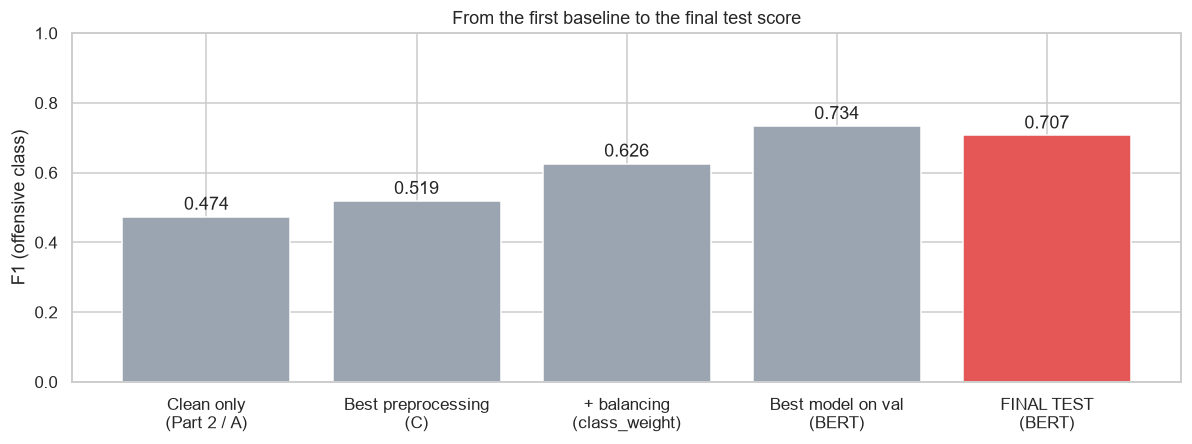

In [93]:
stages = []   # (label, F1)

if syn_prep is not None:                                    # Part 3: preprocessing
    p = syn_prep.set_index("variant")
    stages.append(("Clean only\n(Part 2 / A)", p.loc["A_clean_only", "f1"]))
    best_variant = p["f1"].idxmax()
    stages.append((f"Best preprocessing\n({best_variant.split('_')[0]})", p.loc[best_variant, "f1"]))

if syn_bal is not None:                                     # Part 4: class balancing (Logistic Regression)
    b = syn_bal[syn_bal["model"] == "logistic_regression"].set_index("strategy")
    stages.append((f"+ balancing\n({b['f1'].idxmax()})", b["f1"].max()))

if syn_val is not None:                                     # Parts 5-6: best model on validation
    v = syn_val.sort_values("F1", ascending=False).iloc[0]
    stages.append((f"Best model on val\n({v['Model']})", v["F1"]))

if syn_test is not None:                                    # Part 6: final test
    t = syn_test.iloc[0]
    stages.append((f"FINAL TEST\n({t['Model']})", t["F1"]))

if stages:
    labels, vals = zip(*stages)
    fig, ax = plt.subplots(figsize=(11, 4.2))
    colors = ["#9AA5B1"] * (len(stages) - 1) + ["#E45756"]   # last bar (test) highlighted
    bars = ax.bar(labels, vals, color=colors, edgecolor="white")
    ax.bar_label(bars, fmt="%.3f", padding=2)
    ax.set_ylim(0, 1); ax.set_ylabel("F1 (offensive class)")
    ax.set_title("From the first baseline to the final test score")
    fig.tight_layout()
    out_dir = ROOT / "results" / "figures" / "07_final_project"; out_dir.mkdir(parents=True, exist_ok=True)
    fig.savefig(out_dir / "f1_progress.png", dpi=200, bbox_inches="tight")
    plt.show(); plt.close(fig)
else:
    print("No stage available: run Parts 3 to 6 first.")

**Reading.** Preprocessing (stop-words with negations protected, then lemmatisation) and **balancing** give the first large gains: the model finds many more offensive tweets (recall) at the price of some precision. Among the classical models the tuned ones then differ by only a few thousandths, which is within the noise of a validation set of 1,324 tweets. The **fine-tuned BERT** is the one real jump of the model comparison (validation F1 about 0.73 against about 0.63 for the best classical models and the BiLSTM), mostly through recall. The last bar is the honest estimate: it is computed on tweets that no decision ever used, so it is normally lower than the validation score (hyperparameters and the best epoch were tuned on validation, and the test set has a different class proportion: 27.9 % offensive vs 33-35 % in train and validation).

## 7.3 The selected model on new tweets
Part 6 writes `models/best_model_info.json`, which says which model was selected. A **classical** model is loaded from `models/best_model.joblib` and receives the same two preprocessing steps as in training (`clean_text`, then the winning variant of Part 3, settings read from `src/config.py`); **BERT** is loaded from `models/bert/` and receives the **original tweet** (its tokenizer handles case, punctuation and emojis).

In [94]:
import json, joblib
import numpy as np

info_path = ROOT / "models" / "best_model_info.json"
new_tweets = [
    "@user you are an idiot and everybody knows it",
    "@user thank you so much, have a wonderful birthday!",
    "@user I do not agree with this policy at all",
    "@user what a stupid idea",
    "@user great game last night, congratulations to the team",
]

if not info_path.exists():
    print("models/best_model_info.json not found -> run Part 6 first.")
else:
    info = json.load(open(info_path, encoding="utf-8"))
    print("Selected model:", info["name"], "| parameters:", info["params"])
    demo = None
    if info["name"] == "BERT":                                           # neural model: raw tweet in, no cleaning
        import torch
        from transformers import AutoTokenizer, AutoModelForSequenceClassification
        device = "cuda" if torch.cuda.is_available() else "cpu"
        tok  = AutoTokenizer.from_pretrained(ROOT / "models" / "bert")
        bert = AutoModelForSequenceClassification.from_pretrained(ROOT / "models" / "bert").to(device).eval()
        enc = tok(new_tweets, truncation=True, max_length=64, padding=True, return_tensors="pt").to(device)
        with torch.no_grad():
            score = torch.softmax(bert(**enc).logits, dim=-1)[:, 1].cpu().numpy()      # P(offensive)
        pred = (score >= 0.5).astype(int)
        processed = new_tweets
    else:                                                                # classical model: clean_text + final preprocessing + TF-IDF
        from src import config
        from src.preprocessing import clean_text
        from src.final_pipeline import make_preprocessor
        bundle = joblib.load(ROOT / "models" / "best_model.joblib")      # {"vectorizer", "model", "name", "params"}
        try:
            demo_fn = make_preprocessor(stopwords=config.USE_STOPWORDS, lemmatize=config.USE_LEMMATIZATION,
                                        keep_pronouns=config.KEEP_PRONOUNS, drop_user=config.DROP_USER)
            processed = [demo_fn(clean_text(t)) for t in new_tweets]
            X_new = bundle["vectorizer"].transform(processed)
            model = bundle["model"]
            pred = model.predict(X_new)
            score = (model.predict_proba(X_new)[:, 1] if hasattr(model, "predict_proba")
                     else model.decision_function(X_new) if hasattr(model, "decision_function")
                     else np.full(len(new_tweets), np.nan))
        except (AttributeError, TypeError) as err:
            processed = None
            print(f"Could not rebuild the final preprocessor from src/config.py ({type(err).__name__}: {err}).")
    if processed is not None:
        demo = pd.DataFrame({"tweet": new_tweets, "processed": processed,
                             "prediction": ["offensive" if p == 1 else "non-offensive" for p in pred],
                             "score": np.round(score, 3)})
        display(demo)

Selected model: BERT | parameters: {'checkpoint': 'distilbert-base-uncased', 'best_epoch': 3, 'lr': 2e-05, 'epochs': 3}


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

,tweet,processed,prediction,score
0,@user you are an idiot and everybody knows it,@user you are an idiot and everybody knows it,offensive,0.977
1,"@user thank you so much, have a wonderful birthday!","@user thank you so much, have a wonderful birthday!",non-offensive,0.024
2,@user I do not agree with this policy at all,@user I do not agree with this policy at all,non-offensive,0.051
3,@user what a stupid idea,@user what a stupid idea,offensive,0.978
4,"@user great game last night, congratulations to the team","@user great game last night, congratulations to the team",non-offensive,0.024


**Reading.** The `processed` column shows what the model really sees: for a classical model the cleaned, stop-word-free, lemmatised text; for BERT the original tweet. The score is `P(offensive)` for models that give probabilities (otherwise a signed margin). Five hand-written tweets prove that the saved pipeline works end to end, **not** that the model is accurate: its quality is measured by the test score above. Offensiveness without any insulting word, such as the third tweet, is the typical difficulty of a bag-of-words model; contextual models such as BERT are expected to cope better.

## 7.4 Files produced by the project

In [95]:
for folder in ("data/processed", "models", "results/metrics", "results/figures", "results/predictions"):
    base = ROOT / folder
    if base.exists():
        files = [p for p in base.rglob("*") if p.is_file()]
        print(f"{folder:<20} {len(files):>4} files   (e.g. {', '.join(sorted(p.name for p in files)[:3])} ...)")
    else:
        print(f"{folder:<20} (not created yet)")

data/processed          8 files   (e.g. .gitkeep, test_clean.csv, test_final.csv ...)
models                 10 files   (e.g. README.md, best_model.joblib, best_model_info.json ...)
results/metrics        24 files   (e.g. .gitkeep, balancing_comparison.csv, best_hyperparameters.csv ...)
results/figures        34 files   (e.g. .gitkeep, 01_class_distribution.png, 02_length_histograms.png ...)
results/predictions    13 files   (e.g. test_predictions_bert.csv, test_predictions_best_model.csv, val_predictions_bert.csv ...)


**Reading.** A quick inventory of what the run left on disk: processed datasets, the saved models, the metric tables, the figures and the predictions. These are the files the report is built from.

## 7.5 Conclusions

### What was done (validation results of the stored run; the final test score is in the table of 7.1 once Part 6 has been run)
| Stage | Decision | Validation F1 (offensive) |
|---|---|---|
| Part 2 · cleaning | lowercase, `@mention → user`, hashtag word kept, punctuation / emojis removed, **negations and masked profanity kept** | – |
| Part 3 · preprocessing | stop-words removed **with negations protected**, then lemmatisation (`ass → as` bug fixed) | 0.469 → **0.519** (CV 0.457 → 0.501) |
| Part 3 · vectorisation | TF-IDF (unigrams + bigrams, `min_df=2`) for the classical models | – |
| Part 4 · imbalance | `class_weight="balanced"` (equivalents for models without it; class-weighted loss for the neural models) | 0.519 → **0.626** (recall 0.39 → 0.63, precision 0.79 → 0.62) |
| Part 5 · classical models | 5 required + Complement NB, SGD, Voting; hyperparameters tuned on validation | best **0.633** (Random Forest) |
| Part 5 · neural models | BiLSTM (cleaned text) and fine-tuned DistilBERT (original tweet, 3 epochs, best epoch on validation) | BiLSTM **0.633**, **BERT 0.734** (precision 0.676, recall 0.802, AP 0.794) |
| Part 6 · final test | the best validation model (BERT) scored once on the test set | see 7.1 |

### Main findings
1. **The data is clean but moderately imbalanced** (33 % offensive in train, 28 % in test). Offensiveness is carried mostly by insults, but also by context: many offensive tweets contain no swear word.
2. **Two decisions gave the first large gains**: protecting negations while removing stop-words / lemmatising (+0.05 F1) and handling the imbalance (+0.10 F1, mostly through recall). Both were measured, not assumed.
3. **Classical models are close to each other** (Random Forest 0.633, Logistic Regression 0.626, Voting 0.626, SGD 0.624, SVM 0.623; Naive Bayes 0.572 and KNN 0.503 behind), within the noise of the validation set. The **BiLSTM (0.633) does not beat them**, as expected with about 12k tweets and embeddings learned from scratch; its validation F1 peaks at epoch 3 and then the training loss keeps falling while the score does not improve (overfitting).
4. **Fine-tuned BERT is clearly the best model**: 0.734 F1, about 0.10 above every other model, with a higher recall (0.80 against 0.57-0.63) at a similar or slightly higher precision than the linear models, and the highest average precision (0.794 against at most 0.714), so it ranks tweets better at every threshold. A gap of this size is much larger than the fold-to-fold standard deviation of about 0.01 seen for the classical models in cross-validation. Cross-validation was not run for the neural models, so their own uncertainty is not measured, and the BERT epoch was chosen on validation, which makes its score slightly optimistic.
5. **For the classical models the ranking is not fully stable**: in 5-fold cross-validation Logistic Regression is first (0.619 ± 0.013) and Random Forest fourth (0.593 ± 0.011).
6. The earlier project decision (Random Forest as final model) only reflected the fact that no neural model had been scored; with BERT available, the selection rule "highest validation F1" picks BERT, and Part 6 scores it once on the test set.

### Limits
* **Different class proportions**: the test set has fewer offensive tweets (27.9 %), which lowers precision for the same error rate, and it is small (860 tweets): one tweet is worth about 0.12 accuracy points.
* **Topic and identity bias**: the corpus is political, and words naming groups (for example `immigrants`, `gay`) are associated with the offensive class in this data; a model, BERT included, can wrongly flag neutral tweets that mention them. Label noise exists in the data itself (6 train tweets carry both labels).
* **Neural test scoring**: Part 6 scores BERT from its saved best-epoch weights (trained on train only); classical models are refitted on train + validation, so their test scores benefit from slightly more data. The BiLSTM is compared on validation only.
* **Single run**: no repetition over several random seeds for BERT.

### Possible next steps
* Compare other checkpoints (`roberta-base`, or a tweet-pretrained one such as `cardiffnlp/twitter-roberta-base`, **not** the `-offensive` one already tuned on this dataset) and more epochs.
* Tune the decision threshold on validation to favour recall if the application is moderation.
* Analyse the errors of BERT (tweets without insults, sarcasm, group mentions) with the saved predictions.

---
**End of the project notebook.**